In [45]:
import os
import numpy as np
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [46]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"
integrative_outputs = "../../../3_integrated_assay_results/3_outputs"
input_dir = "../1_inputs/sqY2H"

In [47]:
all_variants_df = pd.read_csv(f"{integrative_outputs}/all_gene_alleles_profiled_by_any_assay.csv")
all_variants_df
all_variants_df_ppi = all_variants_df[~all_variants_df["ppi_score_final_euclidean"].isna()]
all_variants_df_ppi

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit
0,EZH2,EZH2_Arg684Cys,ENSG00000106462,NC_000007.14:148809370:G:A,143,213584.0,2050C>T,Arg684Cys,1_Pathogenic,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.227048,False
1,PTS,PTS_Arg25Gln,ENSG00000150787,NC_000011.10:112226517:G:A,145,200059.0,74G>A,Arg25Gln,1_Pathogenic,6.990040e-07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.096126,False
2,PTS,PTS_Asp116Gly,ENSG00000150787,NC_000011.10:112233464:A:G,145,200065.0,347A>G,Asp116Gly,3_Conflicting,4.105980e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.035047,False
7,MVK,MVK_His20Pro,ENSG00000110921,NC_000012.12:109574881:A:C,281,3.0,59A>C,His20Pro,1_Pathogenic,9.603990e-06,...,0.043478,<10,>90,1.094888,Uncertain,Increase,0.662373,False,0.156925,False
9,MVK,MVK_Ser52Asn,ENSG00000110921,NC_000012.12:109576074:G:A,281,5.0,155G>A,Ser52Asn,2_Benign,1.106140e-01,...,0.176923,10-90,>90,0.332799,N,Increase,NaN,NaN,0.076071,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295,KCNJ2,KCNJ2_Arg312His,ENSG00000123700,NC_000017.11:70175974:G:A,100016069,2649.0,935G>A,Arg312His,1_Pathogenic,6.840540e-07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.441451,False
1300,KCNJ2,KCNJ2_Glu349Lys,ENSG00000123700,NC_000017.11:70176084:G:A,100016069,2654.0,1045G>A,Glu349Lys,3_Conflicting,1.299710e-05,...,0.737113,10-90,>90,-2.398930,Uncertain,Increase,NaN,NaN,0.486680,False
1302,KCNJ2,KCNJ2_Thr400Met,ENSG00000123700,NC_000017.11:70176238:C:T,100016069,2656.0,1199C>T,Thr400Met,3_Conflicting,5.198930e-05,...,0.838028,10-90,<=50,-1.542409,Uncertain,Increase,NaN,NaN,0.440399,False
1304,KCNJ2,KCNJ2_Pro415Leu,ENSG00000123700,NC_000017.11:70176283:C:T,100016069,2659.0,1244C>T,Pro415Leu,3_Conflicting,1.238130e-04,...,0.948529,$\geqslant$90,<=50,-1.829715,Uncertain,Increase,NaN,NaN,0.474199,False


In [48]:
all_variants_df.mut_id.nunique()

1305

In [49]:
all_variants_df_ppi.symbol.nunique()

73

In [50]:
scores = pl.read_csv(f"{sqy2h_outputs_dir}/8_variants_perturbation_scores_automated_annotated_lwh1.csv")

In [51]:
scores.to_pandas().columns

Index(['euclid_distance', 'max_perturbation', 'max_relative_perturbation',
       'max_perturbation_abs', 'max_perturbation_fold',
       'max_perturbation_fold_abs', 'max_log2_fold_change',
       'max_log2_fold_change_abs', 'mahalanobis_distance', 'num_edges',
       'all_edges_severely_perturbed', 'fraction_severely_perturbed',
       'mean_perturbation', 'mean_relative_perturbation',
       'std_relative_perturbation', 'min_edge_value',
       'min_relative_edge_value', 'no_edges_perturbed', 'inconclusive',
       'mean_wt', 'log2fc_perturbed', 'log2fc_no_perturbed',
       'fraction_log2fc_perturbed', 'normalized_euclid_distance',
       'normalized_euclid_distance_normalized', 'symbol', 'aa_change',
       'nt_change', 'ensembl_gene_id', 'collection', 'clinvar_clnsig_clean',
       'gnomad_af', 'StarStatus', 'allele_0', 'variant_class',
       'variant_class_log2fc', 'lwh1_normalized_euclid_distance',
       'lwh1_log2fc_perturbed', 'lwh1_log2fc_no_perturbed',
       'lwh1_fracti

In [52]:
cols_to_keep = ['orf_id', 'mut_id',
       'normalized_euclid_distance_normalized', 'symbol', 'aa_change',
       'nt_change', 'ensembl_gene_id', 'collection', 'clinvar_clnsig_clean',
       'gnomad_af', 'StarStatus', 'allele_0']

scores_pd = scores.to_pandas()
scores_pd = scores_pd[cols_to_keep].rename(columns={'normalized_euclid_distance_normalized': 'ppi_score_final_euclidean'})
scores_pd['perturbed'] = scores_pd['ppi_score_final_euclidean'] > 0.503
scores_pd.to_csv(f"{sqy2h_outputs_dir}/sqY2H_final_scores.csv", index=False)

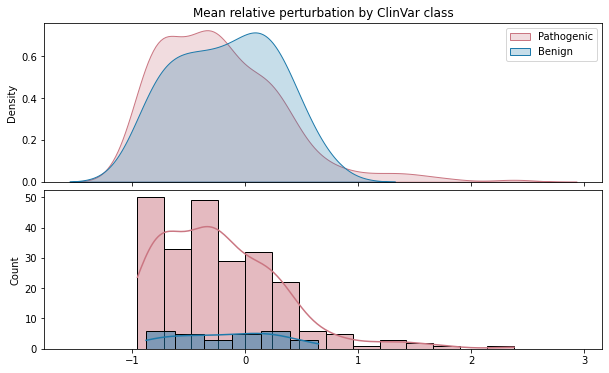

In [53]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["mean_relative_perturbation"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["mean_relative_perturbation"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["mean_relative_perturbation"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["mean_relative_perturbation"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("Mean relative perturbation by ClinVar class")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

In [54]:
scores_pd = scores.to_pandas()
scores_pd

,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,...,variant_class,variant_class_log2fc,lwh1_normalized_euclid_distance,lwh1_log2fc_perturbed,lwh1_log2fc_no_perturbed,lwh1_fraction_log2fc_perturbed,variant_class_log2fc_lwh1,orf_id,mut_id,normalized_euclid_distance_normalized_lwh1
0,0.424768,0.424768,-0.919706,0.424768,12.454179,12.454179,3.638558,3.638558,1.928377,1,...,QN,QN,415.226812,True,False,1.0,QN,70497,3812,0.712846
1,0.122513,0.087804,-0.143996,0.087804,1.274783,1.274783,0.350251,0.350251,1.019492,2,...,QW,QW,7.395152,False,True,0.0,QW,55246,3211,0.012696
2,0.124062,0.106602,0.143107,0.106602,1.172656,1.172656,0.229780,0.229780,0.796632,2,...,QW,QW,70.694897,False,True,0.0,QW,4723,201743,0.121366
3,0.039162,-0.039162,0.097366,0.039162,0.911273,0.911273,-0.134044,0.134044,0.316631,1,...,QW,QW,1.836605,False,True,0.0,QW,54308,3083,0.003153
4,0.243126,0.096929,0.502799,0.096929,1.154568,1.154568,0.207353,0.207353,1.541839,2,...,QW,QW,89.209178,False,True,0.0,QW,4723,201745,0.153151
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,0.575121,0.460490,0.729320,0.460490,2.758646,2.758646,1.463960,1.463960,4.360511,5,...,E,E,136.071682,False,True,0.0,QW,7652,1817,0.233603
471,1.156748,0.336169,9.854759,0.336169,1.742427,1.742427,0.801098,0.801098,4.200358,34,...,E,QW,NaN,None,None,NaN,None,3535,6172,NaN
472,0.135826,0.135826,-0.337313,0.135826,1.509007,1.509007,0.593600,0.593600,1.307451,1,...,I,QW,93.312749,False,True,0.0,QW,8420,216661,0.160196
473,0.380327,0.272928,-0.342955,0.272928,1.537835,1.537835,0.620901,0.620901,1.972313,2,...,I,QW,79.216572,False,True,0.0,QW,7982,202801,0.135996


In [55]:
# Select the columns we want to merge
metrics_to_add = scores_pd[['allele_0', 'max_perturbation_fold', 'max_perturbation', 
                           'max_perturbation_abs', 'max_perturbation_fold_abs', 'max_log2_fold_change', 'variant_class', 'variant_class_log2fc', 'mean_relative_perturbation', 'mean_wt', 'num_edges']]

# Rename the key column to match
metrics_to_add = metrics_to_add.rename(columns={'allele_0': 'gene_variant'})

# Merge with all_variants_df_ppi
all_variants_df_ppi = all_variants_df_ppi.merge(metrics_to_add, on='gene_variant', how='left')

all_variants_df_ppi

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,num_edges
0,EZH2,EZH2_Arg684Cys,ENSG00000106462,NC_000007.14:148809370:G:A,143,213584.0,2050C>T,Arg684Cys,1_Pathogenic,NaN,...,1.597322,0.180090,0.180090,1.597322,0.675656,I,QW,-0.373952,0.481586,1
1,PTS,PTS_Arg25Gln,ENSG00000150787,NC_000011.10:112226517:G:A,145,200059.0,74G>A,Arg25Gln,1_Pathogenic,6.990040e-07,...,0.767416,-0.076245,0.076245,0.767416,-0.381920,QW,QW,0.303075,0.251573,1
2,PTS,PTS_Asp116Gly,ENSG00000150787,NC_000011.10:112233464:A:G,145,200065.0,347A>G,Asp116Gly,3_Conflicting,4.105980e-06,...,1.124227,0.027799,0.027799,1.124227,0.168933,QW,QW,-0.110500,0.251573,1
3,MVK,MVK_His20Pro,ENSG00000110921,NC_000012.12:109574881:A:C,281,3.0,59A>C,His20Pro,1_Pathogenic,9.603990e-06,...,2.766949,0.124470,0.124470,2.766949,1.468296,QN,QN,-0.638591,0.194913,1
4,MVK,MVK_Ser52Asn,ENSG00000110921,NC_000012.12:109576074:G:A,281,5.0,155G>A,Ser52Asn,2_Benign,1.106140e-01,...,0.763612,-0.060338,0.060338,0.763612,-0.389088,QW,QW,0.309565,0.194913,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,KCNJ2,KCNJ2_Arg312His,ENSG00000123700,NC_000017.11:70175974:G:A,100016069,2649.0,935G>A,Arg312His,1_Pathogenic,6.840540e-07,...,4.001877,0.412944,0.412944,4.001877,2.000677,QN,QN,-0.707648,0.480679,2
471,KCNJ2,KCNJ2_Glu349Lys,ENSG00000123700,NC_000017.11:70176084:G:A,100016069,2654.0,1045G>A,Glu349Lys,3_Conflicting,1.299710e-05,...,5.449343,0.449484,0.449484,5.449343,2.446082,QN,QN,-0.785303,0.480679,2
472,KCNJ2,KCNJ2_Thr400Met,ENSG00000123700,NC_000017.11:70176238:C:T,100016069,2656.0,1199C>T,Thr400Met,3_Conflicting,5.198930e-05,...,6.350245,0.352449,0.352449,6.350245,2.666812,QN,QN,-0.741376,0.480679,2
473,KCNJ2,KCNJ2_Pro415Leu,ENSG00000123700,NC_000017.11:70176283:C:T,100016069,2659.0,1244C>T,Pro415Leu,3_Conflicting,1.238130e-04,...,6.276117,0.404532,0.404532,6.276117,2.649872,QN,QN,-0.787751,0.480679,2


In [56]:
all_variants_df_ppi.mean_wt.describe()

count    475.000000
mean       0.435556
std        0.142447
min        0.011517
25%        0.329775
50%        0.449457
75%        0.506865
max        0.834116
Name: mean_wt, dtype: float64

In [57]:
all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi)
all_variants_df_ppi_pl

symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,StarStatus,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,num_edges
str,str,str,str,i64,f64,str,str,str,f64,f64,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,f64,bool,f64,bool,f64,f64,f64,f64,f64,str,str,f64,f64,i64
"""EZH2""","""EZH2_Arg684Cys""","""ENSG00000106462""","""NC_000007.14:148809370:G:A""",143,213584.0,"""2050C>T""","""Arg684Cys""","""1_Pathogenic""",null,2.0,"""0.9989""","""0.99217""","""P""","""-13.11""","""0.89908""","""D""",null,null,null,null,null,null,null,null,null,0.227048,false,1.597322,0.18009,0.18009,1.597322,0.675656,"""I""","""QW""",-0.373952,0.481586,1
"""PTS""","""PTS_Arg25Gln""","""ENSG00000150787""","""NC_000011.10:112226517:G:A""",145,200059.0,"""74G>A""","""Arg25Gln""","""1_Pathogenic""",6.9900e-7,2.0,"""0.5313""","""0.65923""","""A""","""-8.228""","""0.62687""","""D""",null,null,null,null,null,null,null,null,null,0.096126,false,0.767416,-0.076245,0.076245,0.767416,-0.38192,"""QW""","""QW""",0.303075,0.251573,1
"""PTS""","""PTS_Asp116Gly""","""ENSG00000150787""","""NC_000011.10:112233464:A:G""",145,200065.0,"""347A>G""","""Asp116Gly""","""3_Conflicting""",0.000004,1.0,"""0.1184""","""0.24328""","""B""","""-7.521""","""0.57830""","""D""",null,null,null,null,null,null,null,null,null,0.035047,false,1.124227,0.027799,0.027799,1.124227,0.168933,"""QW""","""QW""",-0.1105,0.251573,1
"""MVK""","""MVK_His20Pro""","""ENSG00000110921""","""NC_000012.12:109574881:A:C""",281,3.0,"""59A>C""","""His20Pro""","""1_Pathogenic""",0.00001,2.0,"""0.906""","""0.85569""","""LP""","""-14.191""","""0.93673""","""D""",94.91,0.043478,"""<10""",""">90""",1.094888,"""Uncertain""","""Increase""",0.662373,false,0.156925,false,2.766949,0.12447,0.12447,2.766949,1.468296,"""QN""","""QN""",-0.638591,0.194913,1
"""MVK""","""MVK_Ser52Asn""","""ENSG00000110921""","""NC_000012.12:109576074:G:A""",281,5.0,"""155G>A""","""Ser52Asn""","""2_Benign""",0.110614,2.0,"""0.0898""","""0.12616""","""LB""","""-2.335""","""0.04755""","""T""",96.01,0.176923,"""10-90""",""">90""",0.332799,"""N""","""Increase""",null,null,0.076071,false,0.763612,-0.060338,0.060338,0.763612,-0.389088,"""QW""","""QW""",0.309565,0.194913,1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""KCNJ2""","""KCNJ2_Arg312His""","""ENSG00000123700""","""NC_000017.11:70175974:G:A""",100016069,2649.0,"""935G>A""","""Arg312His""","""1_Pathogenic""",6.8405e-7,2.0,"""0.9769""","""0.91488""","""LP""","""-11.524""","""0.82509""","""D""",null,null,null,null,null,null,null,null,null,0.441451,false,4.001877,0.412944,0.412944,4.001877,2.000677,"""QN""","""QN""",-0.707648,0.480679,2
"""KCNJ2""","""KCNJ2_Glu349Lys""","""ENSG00000123700""","""NC_000017.11:70176084:G:A""",100016069,2654.0,"""1045G>A""","""Glu349Lys""","""3_Conflicting""",0.000013,1.0,"""0.1656""","""0.38882""","""B""","""-8.869""","""0.66926""","""D""",97.03,0.7371134,"""10-90""",""">90""",-2.39893,"""Uncertain""","""Increase""",null,null,0.48668,false,5.449343,0.449484,0.449484,5.449343,2.446082,"""QN""","""QN""",-0.785303,0.480679,2
"""KCNJ2""","""KCNJ2_Thr400Met""","""ENSG00000123700""","""NC_000017.11:70176238:C:T""",100016069,2656.0,"""1199C>T""","""Thr400Met""","""3_Conflicting""",0.000052,1.0,"""0.0762""","""0.06646""","""B""","""-5.131""","""0.38277""","""T""",40.68,0.8380282,"""10-90""","""<=50""",-1.542409,"""Uncertain""","""Increase""",null,null,0.440399,false,6.350245,0.352449,0.352449,6.350245,2.666812,"""QN""","""QN""",-0.741376,0.480679,2


In [58]:
allele_col = pd.read_csv('/Users/user_42/Partners HealthCare Dropbox/Maxime Tixhon/PhD/VarChamp/2025_laval_submitted/1_allele_collection/3_outputs/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv', sep="\t")
allele_col

inh_dict = allele_col.set_index("gene_variant")["inheritance_pattern"].to_dict()
inh_dict

source_dict = allele_col.set_index("gene_variant")["inheritance_source"].to_dict()
rsa_dict = allele_col.set_index("gene_variant")["rsa"].to_dict()
plddt_dict = allele_col.set_index("gene_variant")["plddt"].to_dict()
all_variants_df_ppi_pd = all_variants_df_ppi_pl.to_pandas()

all_variants_df_ppi_pd['inheritance_pattern'] = all_variants_df_ppi_pd['gene_variant'].map(inh_dict)
all_variants_df_ppi_pd['inheritance_source'] = all_variants_df_ppi_pd['gene_variant'].map(source_dict)
all_variants_df_ppi_pd['rsa'] = all_variants_df_ppi_pd['gene_variant'].map(rsa_dict)
all_variants_df_ppi_pd['plddt'] = all_variants_df_ppi_pd['gene_variant'].map(plddt_dict)


all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi_pd)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/2085463965.py:1: DtypeWarning: Columns (104,106,139,142,158,159,161,162,164,166,188,190,191,193,194,196,197,200,211,218,219,231,232,242,243,244,255,256,259,260) have mixed types. Specify dtype option on import or set low_memory=False.
  allele_col = pd.read_csv('/Users/user_42/Partners HealthCare Dropbox/Maxime Tixhon/PhD/VarChamp/2025_laval_submitted/1_allele_collection/3_outputs/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv', sep="\t")


In [59]:
all_variants_df_ppi_pd[all_variants_df_ppi_pd.clinvar_clnsig_clean == '2_Benign'].inheritance_pattern.value_counts()

inheritance_pattern
multiple               8
autosomal recessive    7
autosomal dominant     7
Name: count, dtype: int64

In [60]:
# Create RSA categories
def categorize_rsa(rsa_value):
    if pd.isna(rsa_value):
        return None
    elif rsa_value < 0.1:
        return '<10'
    elif rsa_value >= 0.9:
        return '$\geqslant$90'
    else:
        return '10-90'

# Create pLDDT categories  
def categorize_plddt(plddt_value):
    if pd.isna(plddt_value):
        return None
    elif plddt_value <= 50:
        return '<=50'
    elif plddt_value <= 70:
        return '50-70'
    elif plddt_value <= 90:
        return '70-90'
    else:
        return '>90'

# Apply categorization to pandas dataframe
all_variants_df_ppi_pd['RSA_Category'] = all_variants_df_ppi_pd['rsa'].apply(categorize_rsa)
all_variants_df_ppi_pd['pLDDT_Category'] = all_variants_df_ppi_pd['plddt'].apply(categorize_plddt)

# Convert back to polars
all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi_pd)

# Verify the categories were created correctly
print("RSA Categories:")
print(all_variants_df_ppi_pl['RSA_Category'].value_counts().sort('RSA_Category'))

print("\npLDDT Categories:")
print(all_variants_df_ppi_pl['pLDDT_Category'].value_counts().sort('pLDDT_Category'))

RSA Categories:
shape: (4, 2)
┌───────────────┬───────┐
│ RSA_Category  ┆ count │
│ ---           ┆ ---   │
│ str           ┆ u32   │
╞═══════════════╪═══════╡
│ null          ┆ 26    │
│ $\geqslant$90 ┆ 23    │
│ 10-90         ┆ 285   │
│ <10           ┆ 141   │
└───────────────┴───────┘

pLDDT Categories:
shape: (5, 2)
┌────────────────┬───────┐
│ pLDDT_Category ┆ count │
│ ---            ┆ ---   │
│ str            ┆ u32   │
╞════════════════╪═══════╡
│ null           ┆ 26    │
│ 50-70          ┆ 32    │
│ 70-90          ┆ 72    │
│ <=50           ┆ 27    │
│ >90            ┆ 318   │
└────────────────┴───────┘


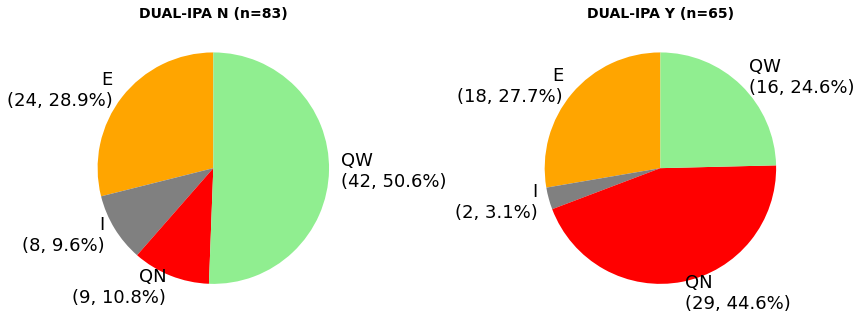

Summary by DUAL-IPA abundance change:

DUAL-IPA N (n=83):
  E: 24 (28.9%)
  I: 8 (9.6%)
  QN: 9 (10.8%)
  QW: 42 (50.6%)

DUAL-IPA Y (n=65):
  E: 18 (27.7%)
  I: 2 (3.1%)
  QN: 29 (44.6%)
  QW: 16 (24.6%)


In [61]:
# Create two separate pie charts for DUAL-IPA N and Y
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

for i, change_type in enumerate(["N", "Y"]):
    subset = all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change") == change_type)
    total = subset.shape[0]
    
    # Get variant class counts
    variant_summary = subset.group_by("variant_class").len().sort("variant_class")
    variant_summary_pd = variant_summary.to_pandas()
    
    if not variant_summary_pd.empty:
        # Calculate percentages
        percentages = (variant_summary_pd['len'] / total * 100).round(1)
        
        # Create labels with counts and percentages
        labels = [f'{cls}\n({count}, {pct}%)' 
                 for cls, count, pct in zip(variant_summary_pd['variant_class'], 
                                          variant_summary_pd['len'], 
                                          percentages)]
        
        # Get colors for each variant class
        colors = [variant_colors.get(cls, 'gray') for cls in variant_summary_pd['variant_class']]
        
        # Create pie chart
        axes[i].pie(variant_summary_pd['len'], 
                   labels=labels, 
                   colors=colors,
                   autopct='',
                   startangle=90,
                   textprops={'fontsize': 18})
        
        axes[i].set_title(f'DUAL-IPA {change_type} (n={total})', fontsize=14, fontweight='bold')
    else:
        axes[i].text(0.5, 0.5, 'No data', ha='center', va='center')
        axes[i].set_title(f'DUAL-IPA {change_type} (n=0)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary by DUAL-IPA abundance change:")
for change_type in ["N", "Y"]:
    subset = all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change") == change_type)
    total = subset.shape[0]
    print(f"\nDUAL-IPA {change_type} (n={total}):")
    variant_summary = subset.group_by("variant_class").len().sort("variant_class")
    for row in variant_summary.iter_rows():
        variant_class, count = row
        percentage = (count / total) * 100
        print(f"  {variant_class}: {count} ({percentage:.1f}%)")

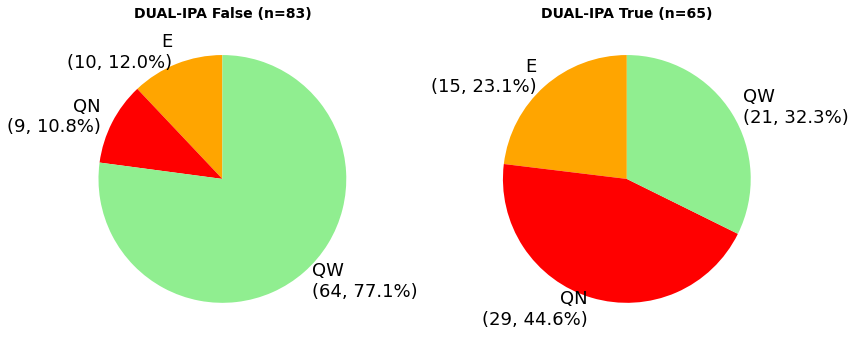

Summary by DUAL-IPA abundance change:

DUAL-IPA N (n=83):
  E: 10 (12.0%)
  QN: 9 (10.8%)
  QW: 64 (77.1%)

DUAL-IPA Y (n=65):
  E: 15 (23.1%)
  QN: 29 (44.6%)
  QW: 21 (32.3%)


In [62]:
# Create two separate pie charts for DUAL-IPA N and Y
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

change_type_dict = {'N': 'False', 'Y': 'True'}

for i, change_type in enumerate(["N", "Y"]):
    subset = all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change") == change_type)
    total = subset.shape[0]
    
    # Get variant class counts
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    variant_summary_pd = variant_summary.to_pandas()
    
    if not variant_summary_pd.empty:
        # Calculate percentages
        percentages = (variant_summary_pd['len'] / total * 100).round(1)
        
        # Create labels with counts and percentages
        labels = [f'{cls}\n({count}, {pct}%)' 
                 for cls, count, pct in zip(variant_summary_pd['variant_class_log2fc'], 
                                          variant_summary_pd['len'], 
                                          percentages)]
        
        # Get colors for each variant class
        colors = [variant_colors.get(cls, 'gray') for cls in variant_summary_pd['variant_class_log2fc']]
        
        # Create pie chart
        axes[i].pie(variant_summary_pd['len'], 
                   labels=labels, 
                   colors=colors,
                   autopct='',
                   startangle=90,
                   textprops={'fontsize': 18})
        
        axes[i].set_title(f'DUAL-IPA {change_type_dict[change_type]} (n={total})', fontsize=14, fontweight='bold')
    else:
        axes[i].text(0.5, 0.5, 'No data', ha='center', va='center')
        axes[i].set_title(f'DUAL-IPA {change_type} (n=0)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary by DUAL-IPA abundance change:")
for change_type in ["N", "Y"]:
    subset = all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change") == change_type)
    total = subset.shape[0]
    print(f"\nDUAL-IPA {change_type} (n={total}):")
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    for row in variant_summary.iter_rows():
        variant_class_log2fc, count = row
        percentage = (count / total) * 100
        print(f"  {variant_class_log2fc}: {count} ({percentage:.1f}%)")

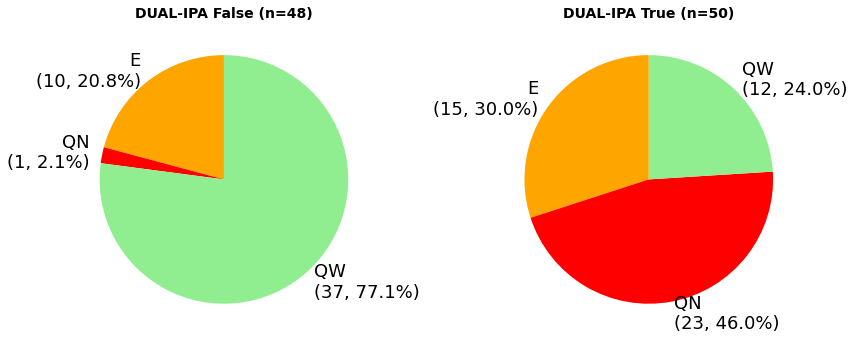

Summary by DUAL-IPA abundance change:

DUAL-IPA N (n=83):
  E: 10 (12.0%)
  QN: 9 (10.8%)
  QW: 64 (77.1%)

DUAL-IPA Y (n=65):
  E: 15 (23.1%)
  QN: 29 (44.6%)
  QW: 21 (32.3%)


In [66]:
# filter for num_edges > 2

# Create two separate pie charts for DUAL-IPA N and Y
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

change_type_dict = {'N': 'False', 'Y': 'True'}

for i, change_type in enumerate(["N", "Y"]):
    subset = all_variants_df_ppi_pl.filter((pl.col("dualipa_abun_change") == change_type) & (pl.col("num_edges") > 1))
    total = subset.shape[0]
    
    # Get variant class counts
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    variant_summary_pd = variant_summary.to_pandas()
    
    if not variant_summary_pd.empty:
        # Calculate percentages
        percentages = (variant_summary_pd['len'] / total * 100).round(1)
        
        # Create labels with counts and percentages
        labels = [f'{cls}\n({count}, {pct}%)' 
                 for cls, count, pct in zip(variant_summary_pd['variant_class_log2fc'], 
                                          variant_summary_pd['len'], 
                                          percentages)]
        
        # Get colors for each variant class
        colors = [variant_colors.get(cls, 'gray') for cls in variant_summary_pd['variant_class_log2fc']]
        
        # Create pie chart
        axes[i].pie(variant_summary_pd['len'], 
                   labels=labels, 
                   colors=colors,
                   autopct='',
                   startangle=90,
                   textprops={'fontsize': 18})
        
        axes[i].set_title(f'DUAL-IPA {change_type_dict[change_type]} (n={total})', fontsize=14, fontweight='bold')
    else:
        axes[i].text(0.5, 0.5, 'No data', ha='center', va='center')
        axes[i].set_title(f'DUAL-IPA {change_type} (n=0)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary by DUAL-IPA abundance change:")
for change_type in ["N", "Y"]:
    subset = all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change") == change_type)
    total = subset.shape[0]
    print(f"\nDUAL-IPA {change_type} (n={total}):")
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    for row in variant_summary.iter_rows():
        variant_class_log2fc, count = row
        percentage = (count / total) * 100
        print(f"  {variant_class_log2fc}: {count} ({percentage:.1f}%)")

In [64]:
stop

NameError: name 'stop' is not defined

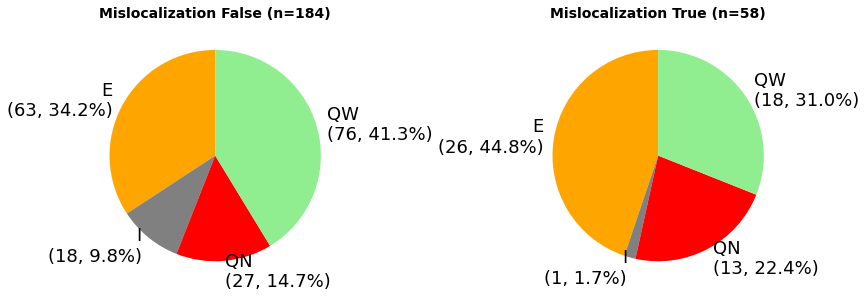

Summary by Mislocalization (Altered_95th_perc_both_batches_GFP):

Mislocalization False (n=184):
  E: 63 (34.2%)
  I: 18 (9.8%)
  QN: 27 (14.7%)
  QW: 76 (41.3%)

Mislocalization True (n=58):
  E: 26 (44.8%)
  I: 1 (1.7%)
  QN: 13 (22.4%)
  QW: 18 (31.0%)


In [ ]:
# Create two separate pie charts for mislocalization N and Y
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

for i, change_type in enumerate([False, True]):
    subset = all_variants_df_ppi_pl.filter(pl.col("Altered_95th_perc_both_batches_GFP") == change_type)
    total = subset.shape[0]
    
    # Get variant class counts
    variant_summary = subset.group_by("variant_class").len().sort("variant_class")
    variant_summary_pd = variant_summary.to_pandas()
    
    if not variant_summary_pd.empty:
        # Calculate percentages
        percentages = (variant_summary_pd['len'] / total * 100).round(1)
        
        # Create labels with counts and percentages
        labels = [f'{cls}\n({count}, {pct}%)' 
                 for cls, count, pct in zip(variant_summary_pd['variant_class'], 
                                          variant_summary_pd['len'], 
                                          percentages)]
        
        # Get colors for each variant class
        colors = [variant_colors.get(cls, 'gray') for cls in variant_summary_pd['variant_class']]
        
        # Create pie chart
        axes[i].pie(variant_summary_pd['len'], 
                   labels=labels, 
                   colors=colors,
                   autopct='',
                   startangle=90,
                   textprops={'fontsize': 18})
        
        axes[i].set_title(f'Mislocalization {change_type} (n={total})', fontsize=14, fontweight='bold')
    else:
        axes[i].text(0.5, 0.5, 'No data', ha='center', va='center')
        axes[i].set_title(f'Mislocalization {change_type} (n=0)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary by Mislocalization (Altered_95th_perc_both_batches_GFP):")
for change_type in [False, True]:
    subset = all_variants_df_ppi_pl.filter(pl.col("Altered_95th_perc_both_batches_GFP") == change_type)
    total = subset.shape[0]
    print(f"\nMislocalization {change_type} (n={total}):")
    variant_summary = subset.group_by("variant_class").len().sort("variant_class")
    for row in variant_summary.iter_rows():
        variant_class, count = row
        percentage = (count / total) * 100
        print(f"  {variant_class}: {count} ({percentage:.1f}%)")

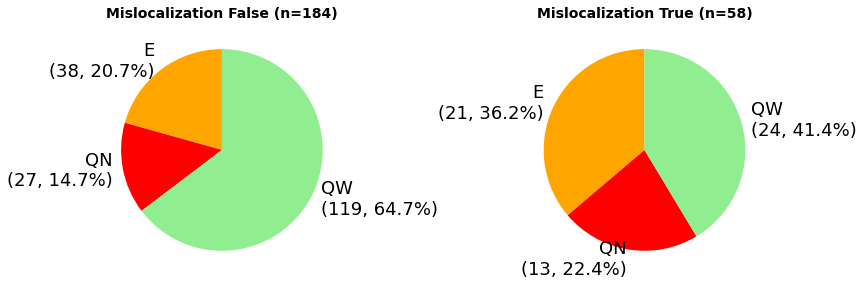

Summary by Mislocalization (Altered_95th_perc_both_batches_GFP):

Mislocalization False (n=184):
  E: 38 (20.7%)
  QN: 27 (14.7%)
  QW: 119 (64.7%)

Mislocalization True (n=58):
  E: 21 (36.2%)
  QN: 13 (22.4%)
  QW: 24 (41.4%)


In [ ]:
# Create two separate pie charts for mislocalization N and Y
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

for i, change_type in enumerate([False, True]):
    subset = all_variants_df_ppi_pl.filter(pl.col("Altered_95th_perc_both_batches_GFP") == change_type)
    total = subset.shape[0]
    
    # Get variant class counts
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    variant_summary_pd = variant_summary.to_pandas()
    
    if not variant_summary_pd.empty:
        # Calculate percentages
        percentages = (variant_summary_pd['len'] / total * 100).round(1)
        
        # Create labels with counts and percentages
        labels = [f'{cls}\n({count}, {pct}%)' 
                 for cls, count, pct in zip(variant_summary_pd['variant_class_log2fc'], 
                                          variant_summary_pd['len'], 
                                          percentages)]
        
        # Get colors for each variant class
        colors = [variant_colors.get(cls, 'gray') for cls in variant_summary_pd['variant_class_log2fc']]
        
        # Create pie chart
        axes[i].pie(variant_summary_pd['len'], 
                   labels=labels, 
                   colors=colors,
                   autopct='',
                   startangle=90,
                   textprops={'fontsize': 18})
        
        axes[i].set_title(f'Mislocalization {change_type} (n={total})', fontsize=14, fontweight='bold')
    else:
        axes[i].text(0.5, 0.5, 'No data', ha='center', va='center')
        axes[i].set_title(f'Mislocalization {change_type} (n=0)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary by Mislocalization (Altered_95th_perc_both_batches_GFP):")
for change_type in [False, True]:
    subset = all_variants_df_ppi_pl.filter(pl.col("Altered_95th_perc_both_batches_GFP") == change_type)
    total = subset.shape[0]
    print(f"\nMislocalization {change_type} (n={total}):")
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    for row in variant_summary.iter_rows():
        variant_class_log2fc, count = row
        percentage = (count / total) * 100
        print(f"  {variant_class_log2fc}: {count} ({percentage:.1f}%)")

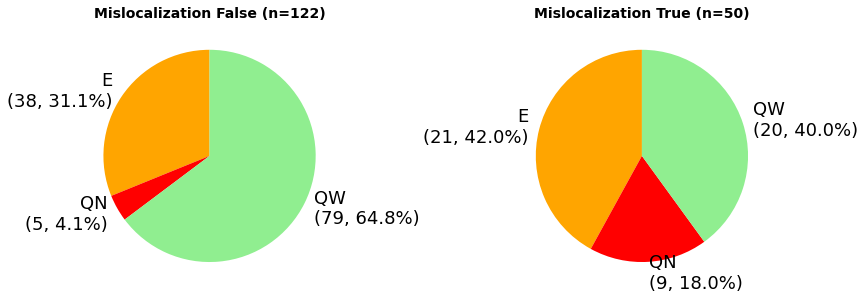

Summary by Mislocalization (Altered_95th_perc_both_batches_GFP):

Mislocalization False (n=184):
  E: 38 (20.7%)
  QN: 27 (14.7%)
  QW: 119 (64.7%)

Mislocalization True (n=58):
  E: 21 (36.2%)
  QN: 13 (22.4%)
  QW: 24 (41.4%)


In [67]:
# filter for num_edges > 2

# Create two separate pie charts for mislocalization N and Y
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

for i, change_type in enumerate([False, True]):
    subset = all_variants_df_ppi_pl.filter((pl.col("Altered_95th_perc_both_batches_GFP") == change_type) & (pl.col("num_edges") > 1))
    total = subset.shape[0]
    
    # Get variant class counts
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    variant_summary_pd = variant_summary.to_pandas()
    
    if not variant_summary_pd.empty:
        # Calculate percentages
        percentages = (variant_summary_pd['len'] / total * 100).round(1)
        
        # Create labels with counts and percentages
        labels = [f'{cls}\n({count}, {pct}%)' 
                 for cls, count, pct in zip(variant_summary_pd['variant_class_log2fc'], 
                                          variant_summary_pd['len'], 
                                          percentages)]
        
        # Get colors for each variant class
        colors = [variant_colors.get(cls, 'gray') for cls in variant_summary_pd['variant_class_log2fc']]
        
        # Create pie chart
        axes[i].pie(variant_summary_pd['len'], 
                   labels=labels, 
                   colors=colors,
                   autopct='',
                   startangle=90,
                   textprops={'fontsize': 18})
        
        axes[i].set_title(f'Mislocalization {change_type} (n={total})', fontsize=14, fontweight='bold')
    else:
        axes[i].text(0.5, 0.5, 'No data', ha='center', va='center')
        axes[i].set_title(f'Mislocalization {change_type} (n=0)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary by Mislocalization (Altered_95th_perc_both_batches_GFP):")
for change_type in [False, True]:
    subset = all_variants_df_ppi_pl.filter(pl.col("Altered_95th_perc_both_batches_GFP") == change_type)
    total = subset.shape[0]
    print(f"\nMislocalization {change_type} (n={total}):")
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    for row in variant_summary.iter_rows():
        variant_class_log2fc, count = row
        percentage = (count / total) * 100
        print(f"  {variant_class_log2fc}: {count} ({percentage:.1f}%)")

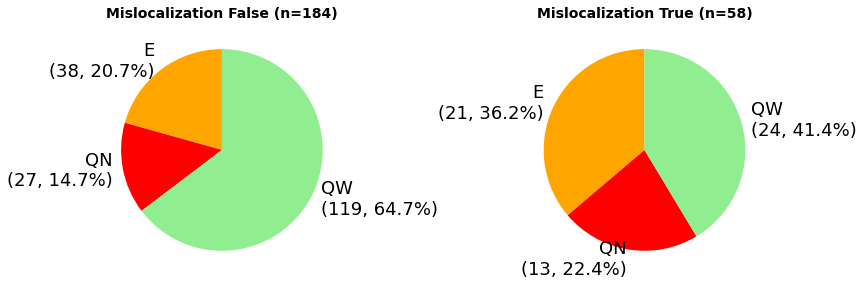

Summary by Mislocalization (Altered_95th_perc_both_batches_GFP):

Mislocalization False (n=184):
  E: 38 (20.7%)
  QN: 27 (14.7%)
  QW: 119 (64.7%)

Mislocalization True (n=58):
  E: 21 (36.2%)
  QN: 13 (22.4%)
  QW: 24 (41.4%)


In [ ]:
# Create two separate pie charts for mislocalization N and Y
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

for i, change_type in enumerate([False, True]):
    subset = all_variants_df_ppi_pl.filter(pl.col("Altered_95th_perc_both_batches_GFP") == change_type)
    total = subset.shape[0]
    
    # Get variant class counts
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    variant_summary_pd = variant_summary.to_pandas()
    
    if not variant_summary_pd.empty:
        # Calculate percentages
        percentages = (variant_summary_pd['len'] / total * 100).round(1)
        
        # Create labels with counts and percentages
        labels = [f'{cls}\n({count}, {pct}%)' 
                 for cls, count, pct in zip(variant_summary_pd['variant_class_log2fc'], 
                                          variant_summary_pd['len'], 
                                          percentages)]
        
        # Get colors for each variant class
        colors = [variant_colors.get(cls, 'gray') for cls in variant_summary_pd['variant_class_log2fc']]
        
        # Create pie chart
        axes[i].pie(variant_summary_pd['len'], 
                   labels=labels, 
                   colors=colors,
                   autopct='',
                   startangle=90,
                   textprops={'fontsize': 18})
        
        axes[i].set_title(f'Mislocalization {change_type} (n={total})', fontsize=14, fontweight='bold')
    else:
        axes[i].text(0.5, 0.5, 'No data', ha='center', va='center')
        axes[i].set_title(f'Mislocalization {change_type} (n=0)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary by Mislocalization (Altered_95th_perc_both_batches_GFP):")
for change_type in [False, True]:
    subset = all_variants_df_ppi_pl.filter(pl.col("Altered_95th_perc_both_batches_GFP") == change_type)
    total = subset.shape[0]
    print(f"\nMislocalization {change_type} (n={total}):")
    variant_summary = subset.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
    for row in variant_summary.iter_rows():
        variant_class_log2fc, count = row
        percentage = (count / total) * 100
        print(f"  {variant_class_log2fc}: {count} ({percentage:.1f}%)")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/3229799208.py:3: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  all_variants_df_ppi_pl


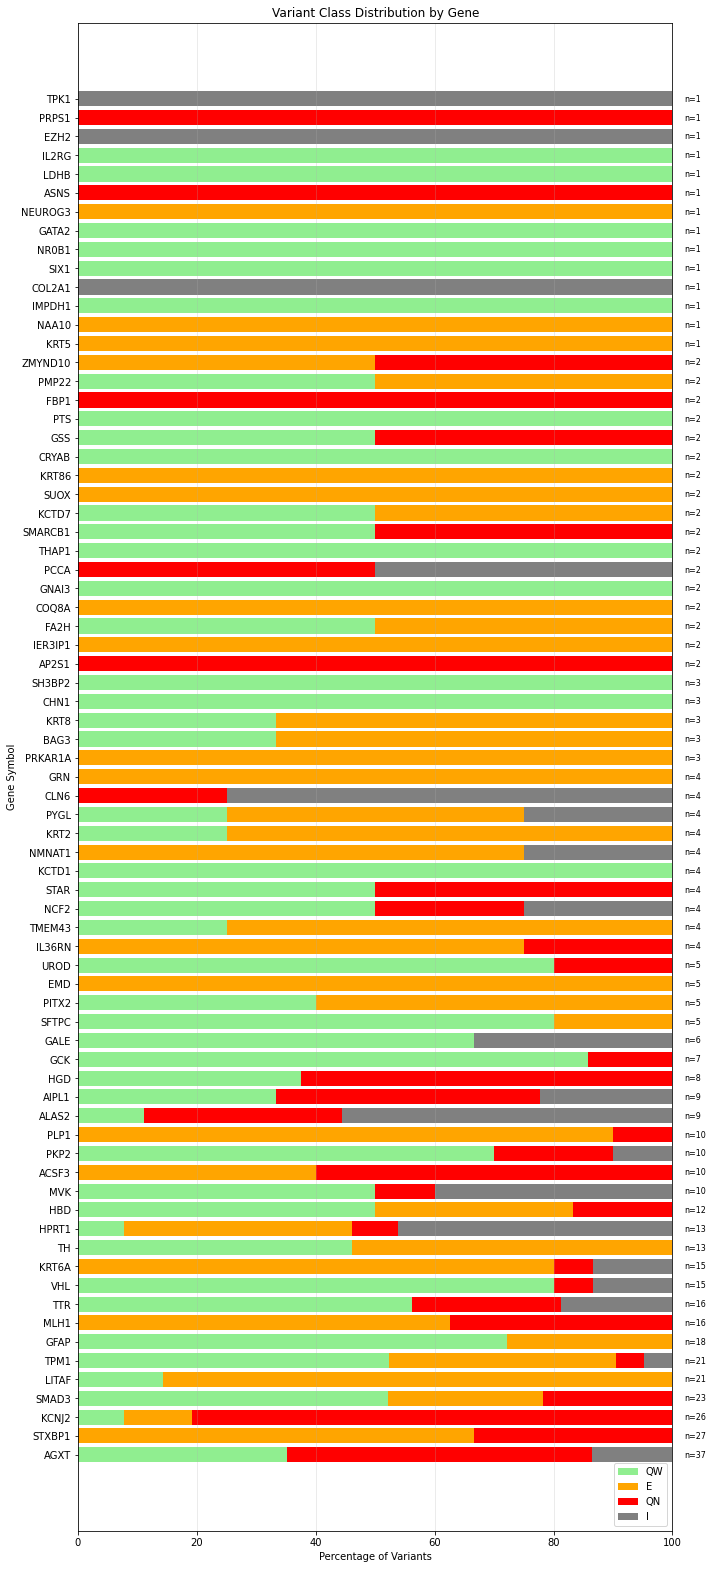

Total genes with variant class data: 73
Total variants analyzed: 475

Top 10 genes by variant count:
symbol
KCTD1       4
SMAD3      23
GRN         4
TPM1       21
CLN6        4
SMARCB1     2
KCTD7       2
PKP2       10
KRT8        3
PYGL        4
dtype: uint64


In [ ]:
# Calculate variant class percentages by gene
variant_class_by_gene = (
    all_variants_df_ppi_pl
    .filter(pl.col("variant_class").is_in(["E", "QN", "QW", 'I']))  # Filter to only these classes
    .group_by(["symbol", "variant_class"])
    .len()
    .pivot(values="len", index="symbol", columns="variant_class")
    .fill_null(0)
)

# Convert to pandas for easier percentage calculation
variant_class_df = variant_class_by_gene.to_pandas().set_index('symbol')

# Fill any missing columns with 0
for col in ["E", "QN", "QW"]:
    if col not in variant_class_df.columns:
        variant_class_df[col] = 0

# Calculate percentages
variant_class_pct = variant_class_df.div(variant_class_df.sum(axis=1), axis=0) * 100

# Sort by total number of variants (descending)
total_variants = variant_class_df.sum(axis=1)
variant_class_pct = variant_class_pct.loc[total_variants.sort_values(ascending=False).index]

# Create the plot
fig, ax = plt.subplots(figsize=(10, max(6, len(variant_class_pct) * 0.3)))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

# Create horizontal stacked bar plot
left = pd.Series(0, index=variant_class_pct.index)
for variant_class in ["QW", "E", "QN", 'I']:  # Order for stacking
    if variant_class in variant_class_pct.columns:
        ax.barh(variant_class_pct.index, variant_class_pct[variant_class], 
                left=left, label=variant_class, color=variant_colors[variant_class])
        left += variant_class_pct[variant_class]

# Customize the plot
ax.set_xlabel('Percentage of Variants')
ax.set_ylabel('Gene Symbol')
ax.set_title('Variant Class Distribution by Gene')
ax.legend(loc='lower right')
ax.set_xlim(0, 100)

# Add grid for easier reading
ax.grid(axis='x', alpha=0.3)

# Add variant counts as text annotations
for i, gene in enumerate(variant_class_pct.index):
    total_count = total_variants[gene]
    ax.text(102, i, f'n={total_count}', va='center', fontsize=8)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total genes with variant class data: {len(variant_class_pct)}")
print(f"Total variants analyzed: {total_variants.sum()}")
print("\nTop 10 genes by variant count:")
print(total_variants.head(10))

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/694177749.py:3: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  all_variants_df_ppi_pl


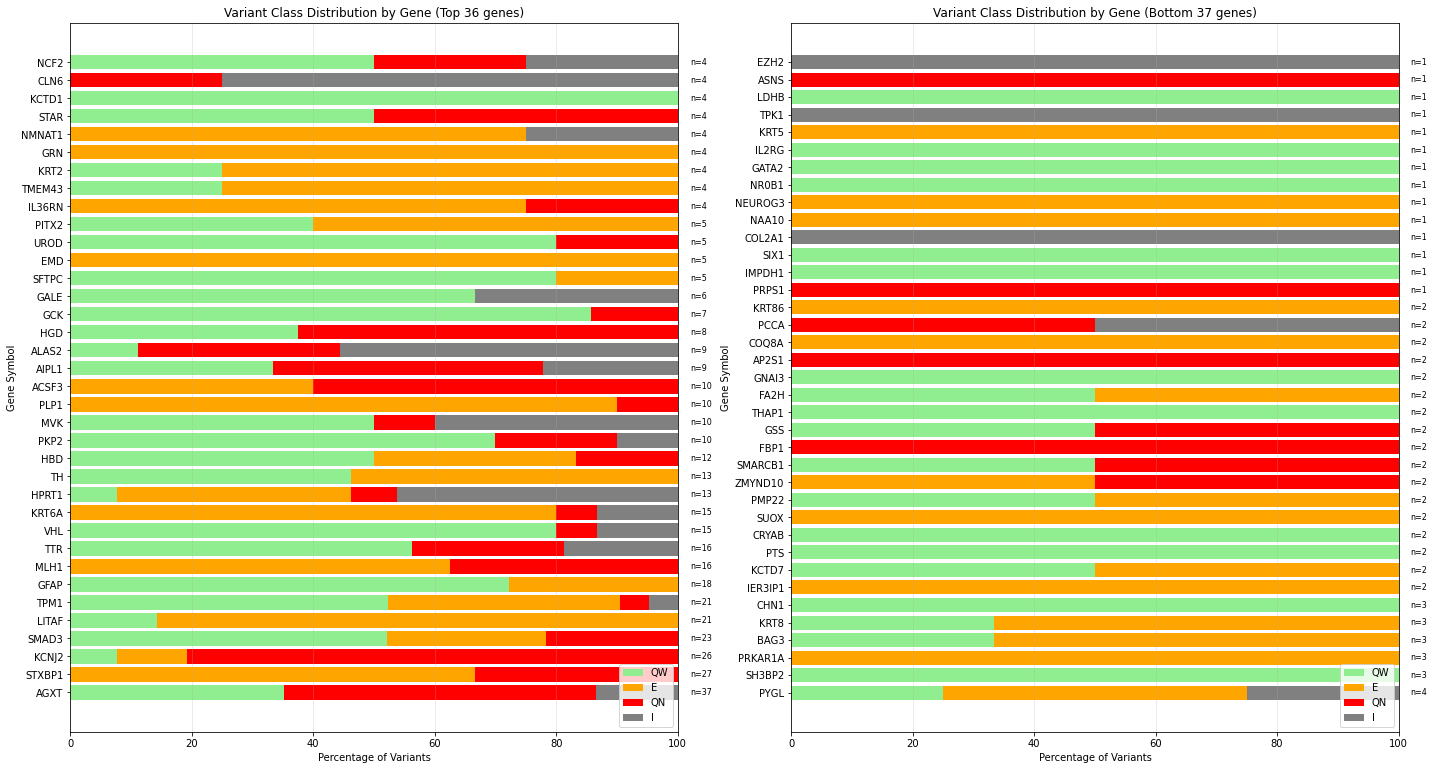

Total genes with variant class data: 73
Total variants analyzed: 475
Split at position 36: Top half has 36 genes, bottom half has 37 genes
Top half variant count range: 18 - 2
Bottom half variant count range: 4 - 1

Top 10 genes by variant count:
symbol
PMP22       2
GALE        6
SMARCB1     2
LITAF      21
VHL        15
IMPDH1      1
GSS         2
SIX1        1
CLN6        4
ALAS2       9
dtype: uint64


In [ ]:
# Calculate variant class percentages by gene
variant_class_by_gene = (
    all_variants_df_ppi_pl
    .filter(pl.col("variant_class").is_in(["E", "QN", "QW", "I"]))  # Filter to only these classes
    .group_by(["symbol", "variant_class"])
    .len()
    .pivot(values="len", index="symbol", columns="variant_class")
    .fill_null(0)
)

# Convert to pandas for easier percentage calculation
variant_class_df = variant_class_by_gene.to_pandas().set_index('symbol')

# Fill any missing columns with 0
for col in ["E", "QN", "QW", "I"]:
    if col not in variant_class_df.columns:
        variant_class_df[col] = 0

# Calculate percentages
variant_class_pct = variant_class_df.div(variant_class_df.sum(axis=1), axis=0) * 100

# Sort by total number of variants (descending)
total_variants = variant_class_df.sum(axis=1)
variant_class_pct = variant_class_pct.loc[total_variants.sort_values(ascending=False).index]

# Split genes into two groups based on variant count
n_genes = len(variant_class_pct)
split_point = n_genes // 2

# Top half (higher variant counts)
variant_class_pct_top = variant_class_pct.iloc[:split_point]
# Bottom half (lower variant counts)
variant_class_pct_bottom = variant_class_pct.iloc[split_point:]

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(20, max(8, len(variant_class_pct_top) * 0.3)))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

# Plot 1: Top genes (higher variant counts)
left_top = pd.Series(0, index=variant_class_pct_top.index)
for variant_class in ["QW", "E", "QN", 'I']:  # Order for stacking
    if variant_class in variant_class_pct_top.columns:
        axes[0].barh(variant_class_pct_top.index, variant_class_pct_top[variant_class], 
                    left=left_top, label=variant_class, color=variant_colors[variant_class])
        left_top += variant_class_pct_top[variant_class]

# Customize plot 1
axes[0].set_xlabel('Percentage of Variants')
axes[0].set_ylabel('Gene Symbol')
axes[0].set_title(f'Variant Class Distribution by Gene (Top {split_point} genes)')
axes[0].legend(loc='lower right')
axes[0].set_xlim(0, 100)
axes[0].grid(axis='x', alpha=0.3)

# Add variant counts as text annotations for plot 1
for i, gene in enumerate(variant_class_pct_top.index):
    total_count = total_variants[gene]
    axes[0].text(102, i, f'n={total_count}', va='center', fontsize=8)

# Plot 2: Bottom genes (lower variant counts)
left_bottom = pd.Series(0, index=variant_class_pct_bottom.index)
for variant_class in ["QW", "E", "QN", 'I']:  # Order for stacking
    if variant_class in variant_class_pct_bottom.columns:
        axes[1].barh(variant_class_pct_bottom.index, variant_class_pct_bottom[variant_class], 
                    left=left_bottom, label=variant_class, color=variant_colors[variant_class])
        left_bottom += variant_class_pct_bottom[variant_class]

# Customize plot 2
axes[1].set_xlabel('Percentage of Variants')
axes[1].set_ylabel('Gene Symbol')
axes[1].set_title(f'Variant Class Distribution by Gene (Bottom {n_genes - split_point} genes)')
axes[1].legend(loc='lower right')
axes[1].set_xlim(0, 100)
axes[1].grid(axis='x', alpha=0.3)

# Add variant counts as text annotations for plot 2
for i, gene in enumerate(variant_class_pct_bottom.index):
    total_count = total_variants[gene]
    axes[1].text(102, i, f'n={total_count}', va='center', fontsize=8)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total genes with variant class data: {len(variant_class_pct)}")
print(f"Total variants analyzed: {total_variants.sum()}")
print(f"Split at position {split_point}: Top half has {len(variant_class_pct_top)} genes, bottom half has {len(variant_class_pct_bottom)} genes")
print(f"Top half variant count range: {total_variants.iloc[split_point-1]} - {total_variants.iloc[0]}")
print(f"Bottom half variant count range: {total_variants.iloc[-1]} - {total_variants.iloc[split_point]}")
print("\nTop 10 genes by variant count:")
print(total_variants.head(10))

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/1362927933.py:3: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  all_variants_df_ppi_pl


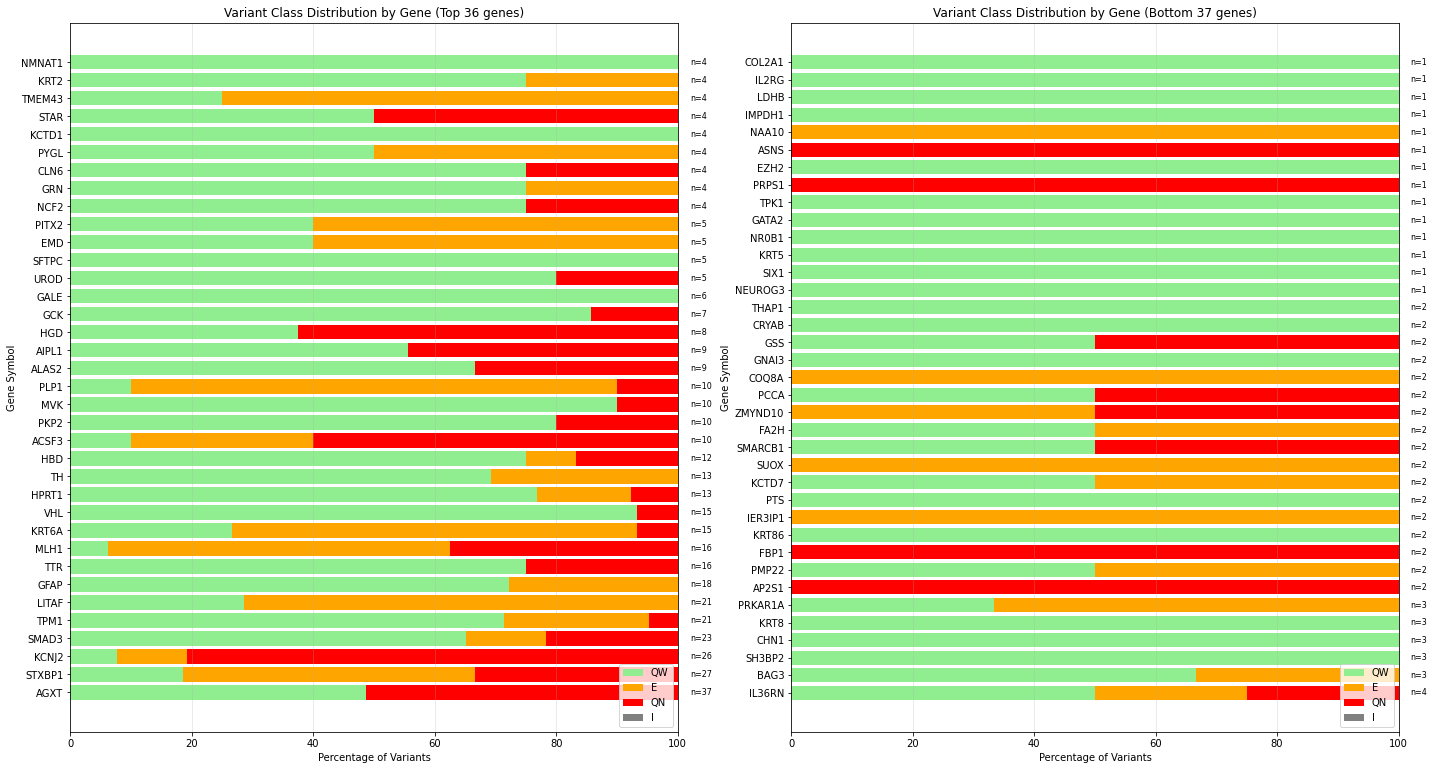

Total genes with variant class data: 73
Total variants analyzed: 475
Split at position 36: Top half has 36 genes, bottom half has 37 genes
Top half variant count range: 2 - 4
Bottom half variant count range: 1 - 2

Top 10 genes by variant count:
symbol
CLN6        4
AIPL1       9
KCNJ2      26
LDHB        1
IMPDH1      1
STXBP1     27
FA2H        2
ZMYND10     2
ASNS        1
STAR        4
dtype: int64


In [ ]:
# Calculate variant class percentages by gene
variant_class_log2fc_by_gene = (
    all_variants_df_ppi_pl
    .filter(pl.col("variant_class_log2fc").is_in(["E", "QN", "QW", "I"]))  # Filter to only these classes
    .group_by(["symbol", "variant_class_log2fc"])
    .len()
    .pivot(values="len", index="symbol", columns="variant_class_log2fc")
    .fill_null(0)
)

# Convert to pandas for easier percentage calculation
variant_class_log2fc_df = variant_class_log2fc_by_gene.to_pandas().set_index('symbol')

# Fill any missing columns with 0
for col in ["E", "QN", "QW", "I"]:
    if col not in variant_class_log2fc_df.columns:
        variant_class_log2fc_df[col] = 0

# Calculate percentages
variant_class_log2fc_pct = variant_class_log2fc_df.div(variant_class_log2fc_df.sum(axis=1), axis=0) * 100

# Sort by total number of variants (descending)
total_variants = variant_class_log2fc_df.sum(axis=1)
variant_class_log2fc_pct = variant_class_log2fc_pct.loc[total_variants.sort_values(ascending=False).index]

# Split genes into two groups based on variant count
n_genes = len(variant_class_log2fc_pct)
split_point = n_genes // 2

# Top half (higher variant counts)
variant_class_log2fc_pct_top = variant_class_log2fc_pct.iloc[:split_point]
# Bottom half (lower variant counts)
variant_class_log2fc_pct_bottom = variant_class_log2fc_pct.iloc[split_point:]

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(20, max(8, len(variant_class_log2fc_pct_top) * 0.3)))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

# Plot 1: Top genes (higher variant counts)
left_top = pd.Series(0, index=variant_class_log2fc_pct_top.index)
for variant_class_log2fc in ["QW", "E", "QN", 'I']:  # Order for stacking
    if variant_class_log2fc in variant_class_log2fc_pct_top.columns:
        axes[0].barh(variant_class_log2fc_pct_top.index, variant_class_log2fc_pct_top[variant_class_log2fc], 
                    left=left_top, label=variant_class_log2fc, color=variant_colors[variant_class_log2fc])
        left_top += variant_class_log2fc_pct_top[variant_class_log2fc]

# Customize plot 1
axes[0].set_xlabel('Percentage of Variants')
axes[0].set_ylabel('Gene Symbol')
axes[0].set_title(f'Variant Class Distribution by Gene (Top {split_point} genes)')
axes[0].legend(loc='lower right')
axes[0].set_xlim(0, 100)
axes[0].grid(axis='x', alpha=0.3)

# Add variant counts as text annotations for plot 1
for i, gene in enumerate(variant_class_log2fc_pct_top.index):
    total_count = total_variants[gene]
    axes[0].text(102, i, f'n={total_count}', va='center', fontsize=8)

# Plot 2: Bottom genes (lower variant counts)
left_bottom = pd.Series(0, index=variant_class_log2fc_pct_bottom.index)
for variant_class_log2fc in ["QW", "E", "QN", 'I']:  # Order for stacking
    if variant_class_log2fc in variant_class_log2fc_pct_bottom.columns:
        axes[1].barh(variant_class_log2fc_pct_bottom.index, variant_class_log2fc_pct_bottom[variant_class_log2fc], 
                    left=left_bottom, label=variant_class_log2fc, color=variant_colors[variant_class_log2fc])
        left_bottom += variant_class_log2fc_pct_bottom[variant_class_log2fc]

# Customize plot 2
axes[1].set_xlabel('Percentage of Variants')
axes[1].set_ylabel('Gene Symbol')
axes[1].set_title(f'Variant Class Distribution by Gene (Bottom {n_genes - split_point} genes)')
axes[1].legend(loc='lower right')
axes[1].set_xlim(0, 100)
axes[1].grid(axis='x', alpha=0.3)

# Add variant counts as text annotations for plot 2
for i, gene in enumerate(variant_class_log2fc_pct_bottom.index):
    total_count = total_variants[gene]
    axes[1].text(102, i, f'n={total_count}', va='center', fontsize=8)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total genes with variant class data: {len(variant_class_log2fc_pct)}")
print(f"Total variants analyzed: {total_variants.sum()}")
print(f"Split at position {split_point}: Top half has {len(variant_class_log2fc_pct_top)} genes, bottom half has {len(variant_class_log2fc_pct_bottom)} genes")
print(f"Top half variant count range: {total_variants.iloc[split_point-1]} - {total_variants.iloc[0]}")
print(f"Bottom half variant count range: {total_variants.iloc[-1]} - {total_variants.iloc[split_point]}")
print("\nTop 10 genes by variant count:")
print(total_variants.head(10))

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/1159614773.py:3: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  all_variants_df_ppi_pl


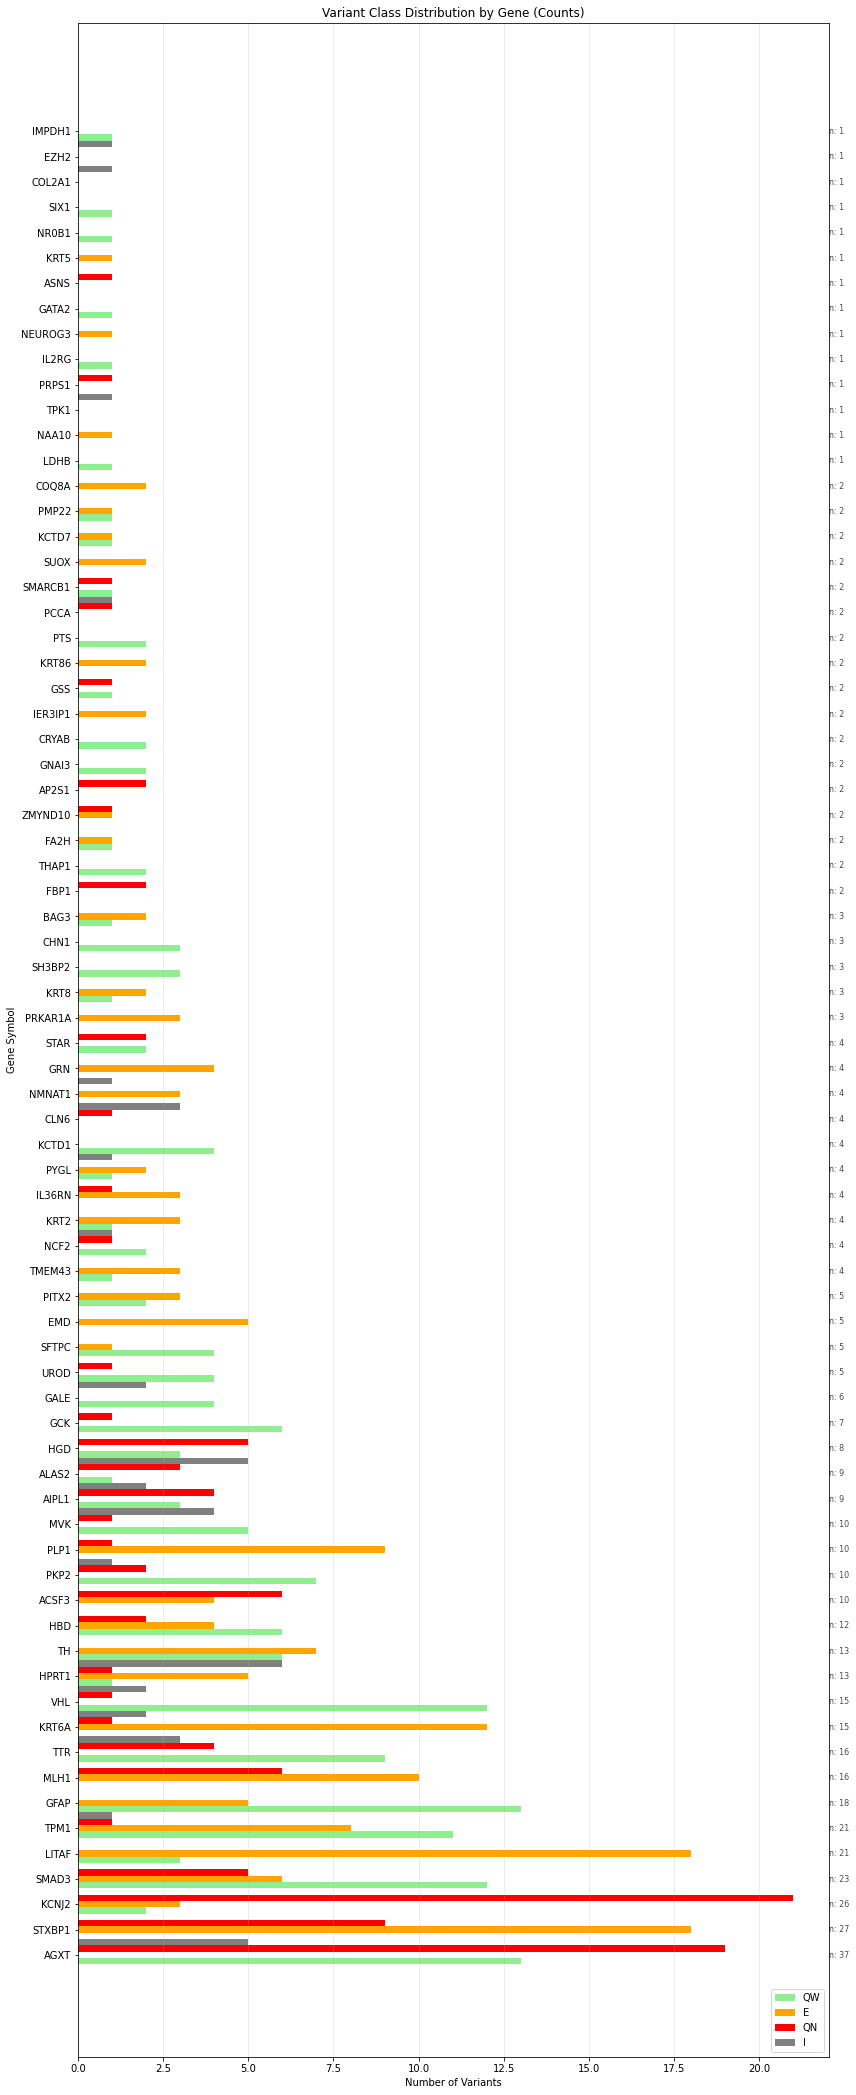

Total genes with variant class data: 73
Total variants analyzed: 475

Variant counts by class:
  E: 158
  QN: 109
  QW: 165

Top 10 genes by variant count:
  HGD: 8
  STAR: 4
  PITX2: 5
  FA2H: 2
  MLH1: 16
  KRT5: 1
  KRT6A: 15
  HBD: 12
  PYGL: 4
  SFTPC: 5


In [ ]:
# Calculate variant class counts by gene
variant_class_by_gene = (
    all_variants_df_ppi_pl
    .filter(pl.col("variant_class").is_in(["E", "QN", "QW", 'I']))  # Filter to only these classes
    .group_by(["symbol", "variant_class"])
    .len()
    .pivot(values="len", index="symbol", columns="variant_class")
    .fill_null(0)
)

# Convert to pandas for easier plotting
variant_class_df = variant_class_by_gene.to_pandas().set_index('symbol')

# Fill any missing columns with 0
for col in ["E", "QN", "QW", 'I']:
    if col not in variant_class_df.columns:
        variant_class_df[col] = 0

# Sort by total number of variants (descending)
total_variants = variant_class_df.sum(axis=1)
variant_class_df = variant_class_df.loc[total_variants.sort_values(ascending=False).index]

# Create the plot with grouped bars
fig, ax = plt.subplots(figsize=(12, max(8, len(variant_class_df) * 0.4)))

# Define colors and positions
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}
y_pos = np.arange(len(variant_class_df))
bar_width = 0.25

# Create grouped horizontal bars
for i, variant_class in enumerate(["QW", "E", "QN", 'I']):
    if variant_class in variant_class_df.columns:
        ax.barh(y_pos + i * bar_width, variant_class_df[variant_class], 
                bar_width, label=variant_class, color=variant_colors[variant_class])

# Customize the plot
ax.set_xlabel('Number of Variants')
ax.set_ylabel('Gene Symbol')
ax.set_title('Variant Class Distribution by Gene (Counts)')
ax.set_yticks(y_pos + bar_width)  # Center the gene labels
ax.set_yticklabels(variant_class_df.index)
ax.legend(loc='lower right')

# Add grid for easier reading
ax.grid(axis='x', alpha=0.3)

# Add total variant counts as text annotations
max_count = variant_class_df.values.max()
for i, gene in enumerate(variant_class_df.index):
    total_count = total_variants[gene]
    ax.text(max_count * 1.05, i + bar_width, f'n: {total_count}', 
            va='center', fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total genes with variant class data: {len(variant_class_df)}")
print(f"Total variants analyzed: {total_variants.sum()}")
print("\nVariant counts by class:")
for variant_class in ["E", "QN", "QW"]:
    if variant_class in variant_class_df.columns:
        total_class = variant_class_df[variant_class].sum()
        print(f"  {variant_class}: {total_class}")

print("\nTop 10 genes by variant count:")
for gene, count in total_variants.head(10).items():
    print(f"  {gene}: {count}")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/3670729042.py:3: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  all_variants_df_ppi_pl


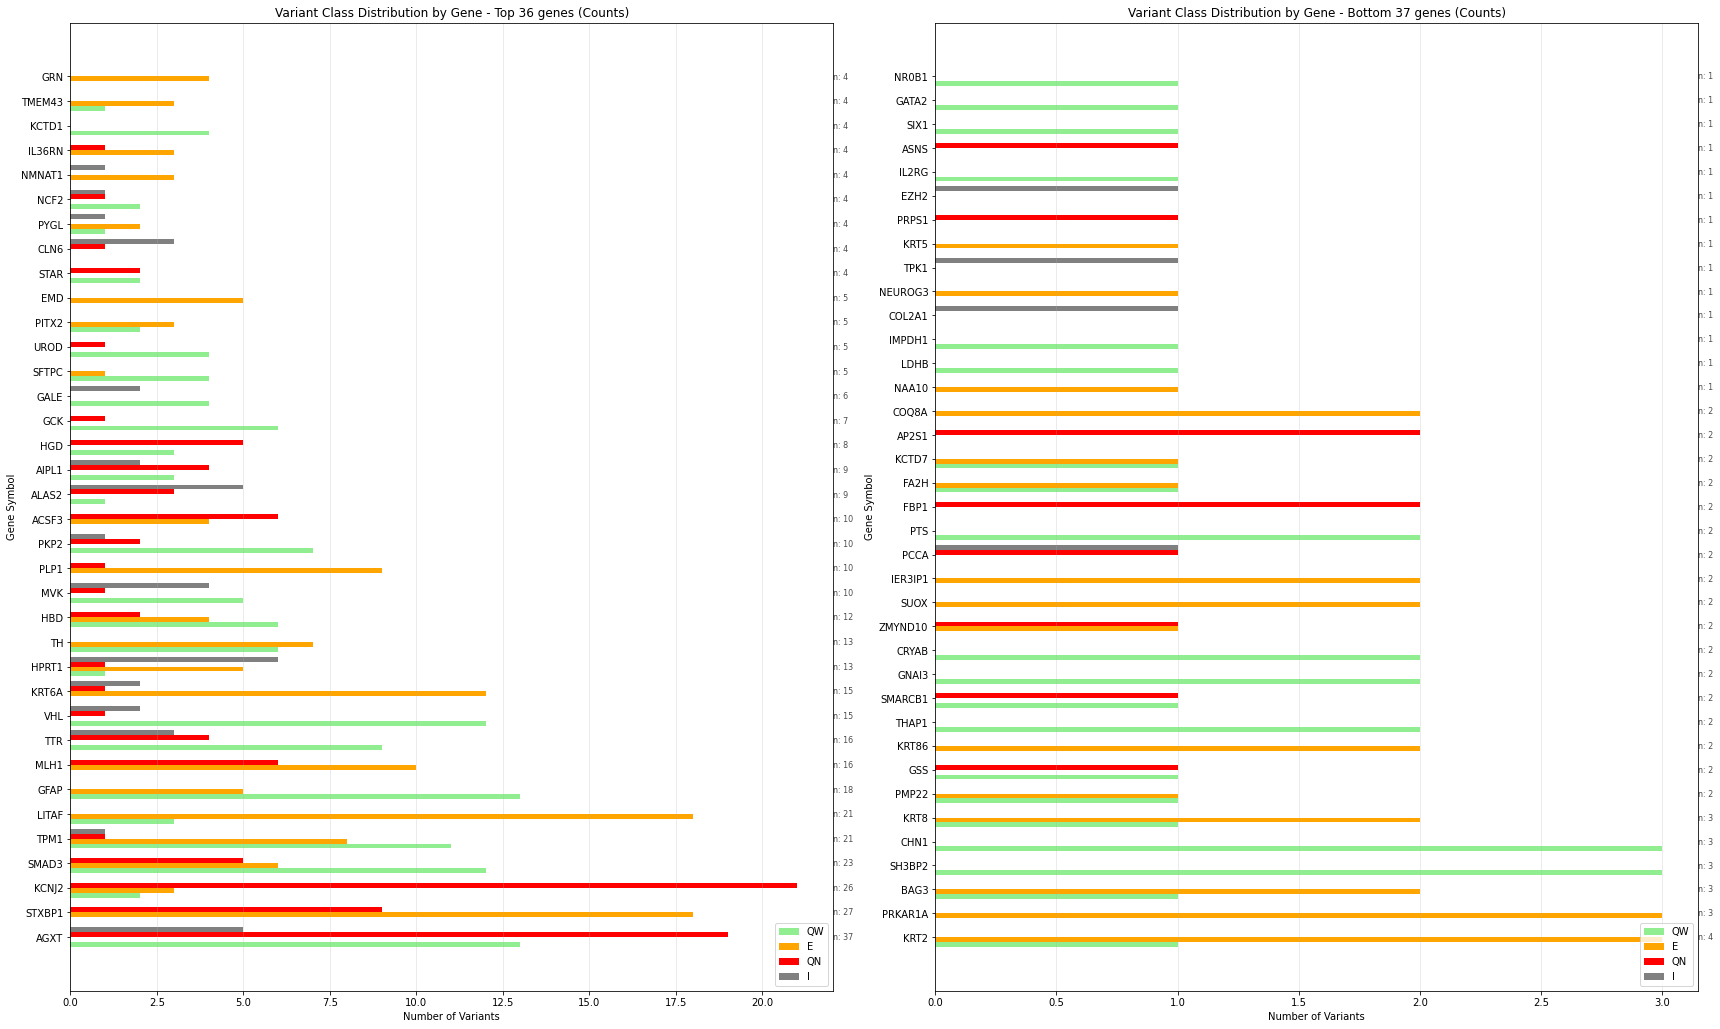

Total genes with variant class data: 73
Total variants analyzed: 475
Split at position 36: Top half has 36 genes, bottom half has 37 genes
Top half variant count range: 2 - 2
Bottom half variant count range: 2 - 1

Variant counts by class:
  E: 158
  QN: 109
  QW: 165
  I: 43

Top 10 genes by variant count:
  SMARCB1: 2
  STAR: 4
  PRKAR1A: 3
  SMAD3: 23
  AIPL1: 9
  TPM1: 21
  MLH1: 16
  PITX2: 5
  ACSF3: 10
  BAG3: 3


In [ ]:
# Calculate variant class counts by gene
variant_class_by_gene = (
    all_variants_df_ppi_pl
    .filter(pl.col("variant_class").is_in(["E", "QN", "QW", 'I']))  # Filter to only these classes
    .group_by(["symbol", "variant_class"])
    .len()
    .pivot(values="len", index="symbol", columns="variant_class")
    .fill_null(0)
)

# Convert to pandas for easier plotting
variant_class_df = variant_class_by_gene.to_pandas().set_index('symbol')

# Fill any missing columns with 0
for col in ["E", "QN", "QW", 'I']:
    if col not in variant_class_df.columns:
        variant_class_df[col] = 0

# Sort by total number of variants (descending)
total_variants = variant_class_df.sum(axis=1)
variant_class_df = variant_class_df.loc[total_variants.sort_values(ascending=False).index]

# Split genes into two groups based on variant count
n_genes = len(variant_class_df)
split_point = n_genes // 2

# Top half (higher variant counts)
variant_class_df_top = variant_class_df.iloc[:split_point]
# Bottom half (lower variant counts)
variant_class_df_bottom = variant_class_df.iloc[split_point:]

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(24, max(10, len(variant_class_df_top) * 0.4)))

# Define colors and positions
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}
bar_width = 0.2

# Plot 1: Top genes (higher variant counts)
y_pos_top = np.arange(len(variant_class_df_top))
for i, variant_class in enumerate(["QW", "E", "QN", 'I']):
    if variant_class in variant_class_df_top.columns:
        axes[0].barh(y_pos_top + i * bar_width, variant_class_df_top[variant_class], 
                    bar_width, label=variant_class, color=variant_colors[variant_class])

# Customize plot 1
axes[0].set_xlabel('Number of Variants')
axes[0].set_ylabel('Gene Symbol')
axes[0].set_title(f'Variant Class Distribution by Gene - Top {split_point} genes (Counts)')
axes[0].set_yticks(y_pos_top + bar_width * 1.5)  # Center the gene labels
axes[0].set_yticklabels(variant_class_df_top.index)
axes[0].legend(loc='lower right')
axes[0].grid(axis='x', alpha=0.3)

# Add total variant counts as text annotations for plot 1
max_count_top = variant_class_df_top.values.max()
for i, gene in enumerate(variant_class_df_top.index):
    total_count = total_variants[gene]
    axes[0].text(max_count_top * 1.05, i + bar_width * 1.5, f'n: {total_count}', 
                va='center', fontsize=8, alpha=0.7)

# Plot 2: Bottom genes (lower variant counts)
y_pos_bottom = np.arange(len(variant_class_df_bottom))
for i, variant_class in enumerate(["QW", "E", "QN", 'I']):
    if variant_class in variant_class_df_bottom.columns:
        axes[1].barh(y_pos_bottom + i * bar_width, variant_class_df_bottom[variant_class], 
                    bar_width, label=variant_class, color=variant_colors[variant_class])

# Customize plot 2
axes[1].set_xlabel('Number of Variants')
axes[1].set_ylabel('Gene Symbol')
axes[1].set_title(f'Variant Class Distribution by Gene - Bottom {n_genes - split_point} genes (Counts)')
axes[1].set_yticks(y_pos_bottom + bar_width * 1.5)  # Center the gene labels
axes[1].set_yticklabels(variant_class_df_bottom.index)
axes[1].legend(loc='lower right')
axes[1].grid(axis='x', alpha=0.3)

# Add total variant counts as text annotations for plot 2
max_count_bottom = variant_class_df_bottom.values.max()
for i, gene in enumerate(variant_class_df_bottom.index):
    total_count = total_variants[gene]
    axes[1].text(max_count_bottom * 1.05, i + bar_width * 1.5, f'n: {total_count}', 
                va='center', fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total genes with variant class data: {len(variant_class_df)}")
print(f"Total variants analyzed: {total_variants.sum()}")
print(f"Split at position {split_point}: Top half has {len(variant_class_df_top)} genes, bottom half has {len(variant_class_df_bottom)} genes")
print(f"Top half variant count range: {total_variants.iloc[split_point-1]} - {total_variants.iloc[0]}")
print(f"Bottom half variant count range: {total_variants.iloc[-1]} - {total_variants.iloc[split_point]}")

print("\nVariant counts by class:")
for variant_class in ["E", "QN", "QW", "I"]:
    if variant_class in variant_class_df.columns:
        total_class = variant_class_df[variant_class].sum()
        print(f"  {variant_class}: {total_class}")

print("\nTop 10 genes by variant count:")
for gene, count in total_variants.head(10).items():
    print(f"  {gene}: {count}")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/2383166189.py:3: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  all_variants_df_ppi_pl


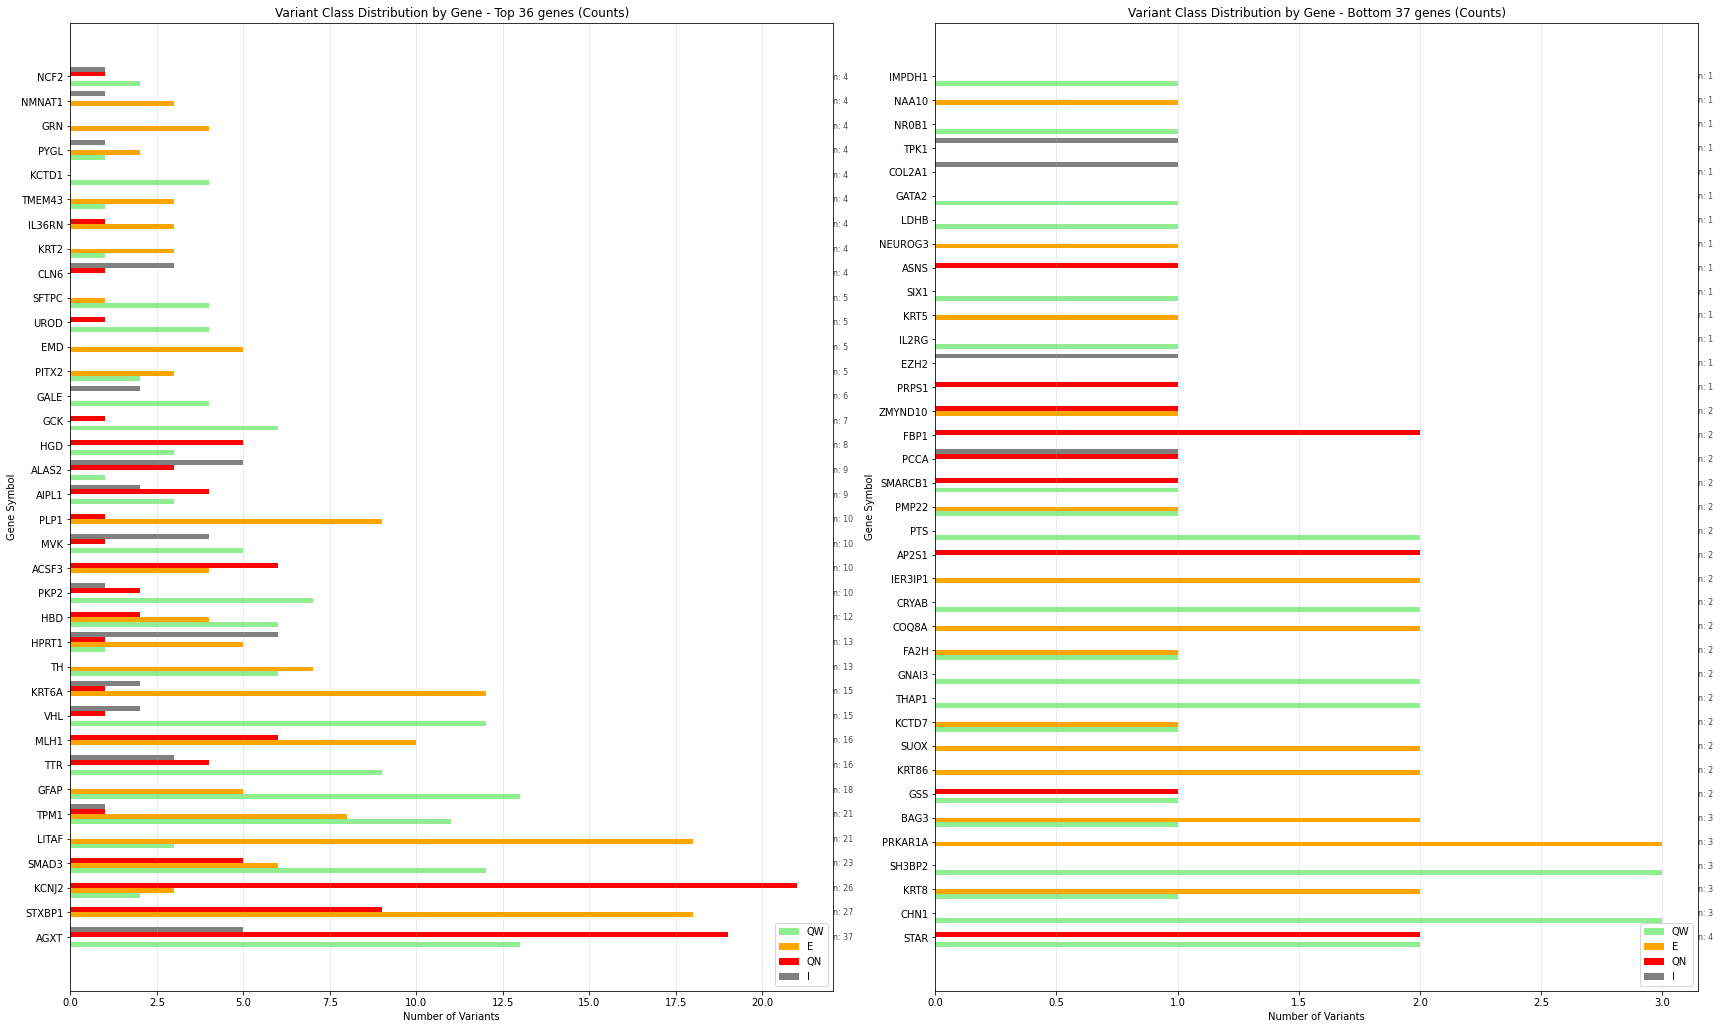

Total genes with variant class data: 73
Total variants analyzed: 475
Split at position 36: Top half has 36 genes, bottom half has 37 genes
Top half variant count range: 2 - 13
Bottom half variant count range: 4 - 4

Variant counts by class:
  E: 158
  QN: 109
  QW: 165
  I: 43

Top 10 genes by variant count:
  HPRT1: 13
  PMP22: 2
  MVK: 10
  NCF2: 4
  HBD: 12
  PLP1: 10
  STXBP1: 27
  GCK: 7
  ACSF3: 10
  PKP2: 10


In [ ]:
# Calculate variant class counts by gene
variant_class_by_gene = (
    all_variants_df_ppi_pl
    .filter(pl.col("variant_class").is_in(["E", "QN", "QW", 'I']))  # Filter to only these classes
    .group_by(["symbol", "variant_class"])
    .len()
    .pivot(values="len", index="symbol", columns="variant_class")
    .fill_null(0)
)

# Convert to pandas for easier plotting
variant_class_df = variant_class_by_gene.to_pandas().set_index('symbol')

# Fill any missing columns with 0
for col in ["E", "QN", "QW", 'I']:
    if col not in variant_class_df.columns:
        variant_class_df[col] = 0

# Sort by total number of variants (descending) - THIS IS THE KEY ORDERING
total_variants = variant_class_df.sum(axis=1)
gene_order = total_variants.sort_values(ascending=False).index  # Save the gene order
variant_class_df = variant_class_df.loc[gene_order]  # Apply ordering to counts

# Calculate percentages using the SAME gene ordering
variant_class_pct = variant_class_df.div(variant_class_df.sum(axis=1), axis=0) * 100
variant_class_pct = variant_class_pct.loc[gene_order]  # Apply same ordering to percentages

# Split genes into two groups based on variant count (using consistent ordering)
n_genes = len(variant_class_df)
split_point = n_genes // 2

# Top half (higher variant counts) - using same split for both
variant_class_df_top = variant_class_df.iloc[:split_point]
variant_class_df_bottom = variant_class_df.iloc[split_point:]
variant_class_pct_top = variant_class_pct.iloc[:split_point]
variant_class_pct_bottom = variant_class_pct.iloc[split_point:]

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(24, max(10, len(variant_class_df_top) * 0.4)))

# Define colors and positions
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}
bar_width = 0.2

# Plot 1: Top genes (higher variant counts)
y_pos_top = np.arange(len(variant_class_df_top))
for i, variant_class in enumerate(["QW", "E", "QN", 'I']):
    if variant_class in variant_class_df_top.columns:
        axes[0].barh(y_pos_top + i * bar_width, variant_class_df_top[variant_class], 
                    bar_width, label=variant_class, color=variant_colors[variant_class])

# Customize plot 1
axes[0].set_xlabel('Number of Variants')
axes[0].set_ylabel('Gene Symbol')
axes[0].set_title(f'Variant Class Distribution by Gene - Top {split_point} genes (Counts)')
axes[0].set_yticks(y_pos_top + bar_width * 1.5)  # Center the gene labels
axes[0].set_yticklabels(variant_class_df_top.index)
axes[0].legend(loc='lower right')
axes[0].grid(axis='x', alpha=0.3)

# Add total variant counts as text annotations for plot 1
max_count_top = variant_class_df_top.values.max()
for i, gene in enumerate(variant_class_df_top.index):
    total_count = total_variants[gene]
    axes[0].text(max_count_top * 1.05, i + bar_width * 1.5, f'n: {total_count}', 
                va='center', fontsize=8, alpha=0.7)

# Plot 2: Bottom genes (lower variant counts)
y_pos_bottom = np.arange(len(variant_class_df_bottom))
for i, variant_class in enumerate(["QW", "E", "QN", 'I']):
    if variant_class in variant_class_df_bottom.columns:
        axes[1].barh(y_pos_bottom + i * bar_width, variant_class_df_bottom[variant_class], 
                    bar_width, label=variant_class, color=variant_colors[variant_class])

# Customize plot 2
axes[1].set_xlabel('Number of Variants')
axes[1].set_ylabel('Gene Symbol')
axes[1].set_title(f'Variant Class Distribution by Gene - Bottom {n_genes - split_point} genes (Counts)')
axes[1].set_yticks(y_pos_bottom + bar_width * 1.5)  # Center the gene labels
axes[1].set_yticklabels(variant_class_df_bottom.index)
axes[1].legend(loc='lower right')
axes[1].grid(axis='x', alpha=0.3)

# Add total variant counts as text annotations for plot 2
max_count_bottom = variant_class_df_bottom.values.max()
for i, gene in enumerate(variant_class_df_bottom.index):
    total_count = total_variants[gene]
    axes[1].text(max_count_bottom * 1.05, i + bar_width * 1.5, f'n: {total_count}', 
                va='center', fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total genes with variant class data: {len(variant_class_df)}")
print(f"Total variants analyzed: {total_variants.sum()}")
print(f"Split at position {split_point}: Top half has {len(variant_class_df_top)} genes, bottom half has {len(variant_class_df_bottom)} genes")
print(f"Top half variant count range: {total_variants.iloc[split_point-1]} - {total_variants.iloc[0]}")
print(f"Bottom half variant count range: {total_variants.iloc[-1]} - {total_variants.iloc[split_point]}")

print("\nVariant counts by class:")
for variant_class in ["E", "QN", "QW", "I"]:
    if variant_class in variant_class_df.columns:
        total_class = variant_class_df[variant_class].sum()
        print(f"  {variant_class}: {total_class}")

print("\nTop 10 genes by variant count:")
for gene, count in total_variants.head(10).items():
    print(f"  {gene}: {count}")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/3255821445.py:3: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  all_variants_df_ppi_pl


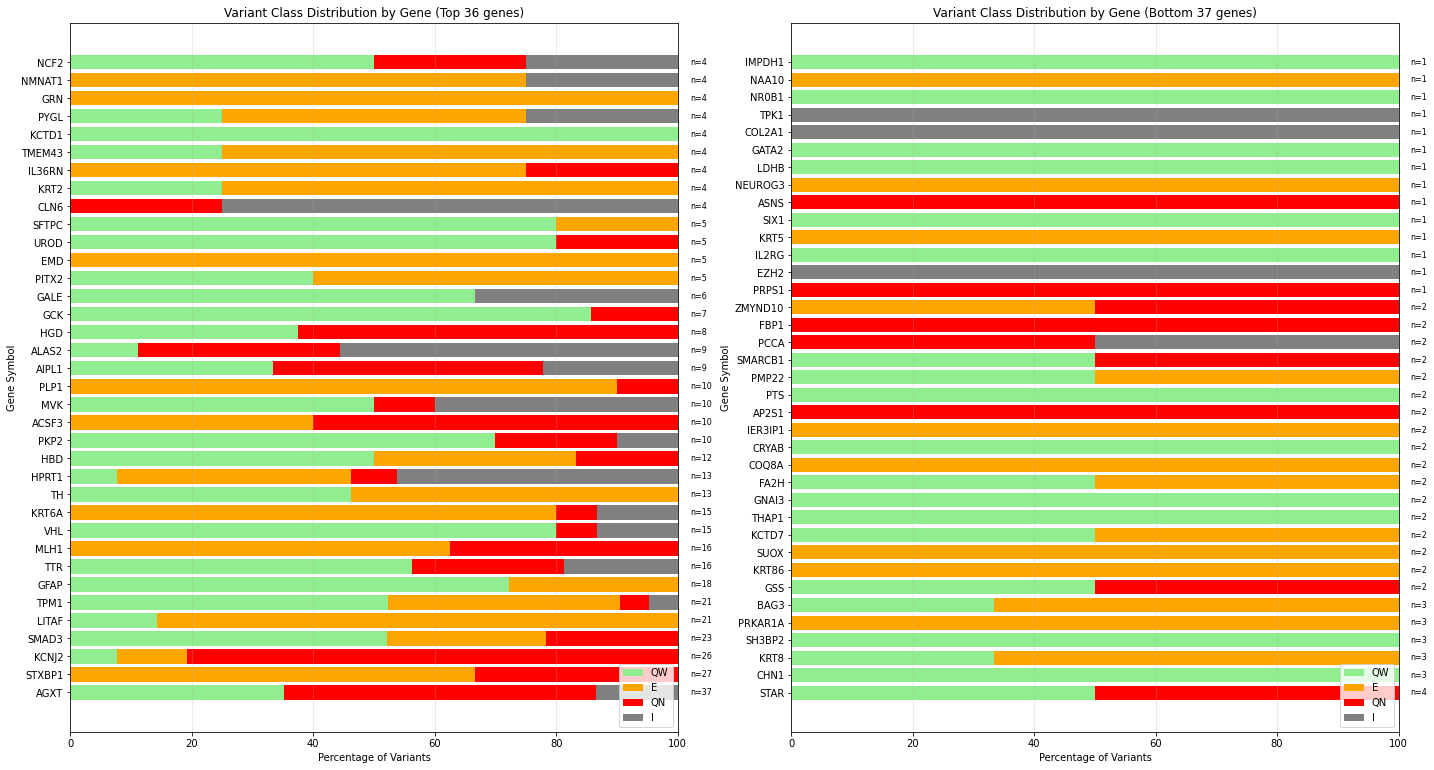

Total genes with variant class data: 73
Total variants analyzed: 475
Split at position 36: Top half has 36 genes, bottom half has 37 genes
Top half variant count range: 8 - 2
Bottom half variant count range: 2 - 1

Top 10 genes by variant count:
symbol
THAP1     2
IL2RG     1
PYGL      4
NCF2      4
HPRT1    13
CLN6      4
AIPL1     9
TTR      16
GATA2     1
SMAD3    23
dtype: uint64


In [ ]:
# Calculate variant class percentages by gene
variant_class_by_gene = (
    all_variants_df_ppi_pl
    .filter(pl.col("variant_class").is_in(["E", "QN", "QW", "I"]))  # Filter to only these classes
    .group_by(["symbol", "variant_class"])
    .len()
    .pivot(values="len", index="symbol", columns="variant_class")
    .fill_null(0)
)

# Convert to pandas for easier percentage calculation
variant_class_df = variant_class_by_gene.to_pandas().set_index('symbol')

# Fill any missing columns with 0
for col in ["E", "QN", "QW", "I"]:
    if col not in variant_class_df.columns:
        variant_class_df[col] = 0

# Sort by total number of variants (descending) - THIS IS THE KEY ORDERING
total_variants = variant_class_df.sum(axis=1)
# gene_order = total_variants.sort_values(ascending=False).index  # Save the gene order
variant_class_df = variant_class_df.loc[gene_order]  # Apply ordering to counts

# Calculate percentages using the SAME gene ordering
variant_class_pct = variant_class_df.div(variant_class_df.sum(axis=1), axis=0) * 100
variant_class_pct = variant_class_pct.loc[gene_order]  # Apply same ordering to percentages

# Split genes into two groups based on variant count (using consistent ordering)
n_genes = len(variant_class_pct)
split_point = n_genes // 2

# Top half (higher variant counts) - using same split for both
variant_class_pct_top = variant_class_pct.iloc[:split_point]
# Bottom half (lower variant counts)
variant_class_pct_bottom = variant_class_pct.iloc[split_point:]

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(20, max(8, len(variant_class_pct_top) * 0.3)))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

# Plot 1: Top genes (higher variant counts)
left_top = pd.Series(0, index=variant_class_pct_top.index)
for variant_class in ["QW", "E", "QN", 'I']:  # Order for stacking
    if variant_class in variant_class_pct_top.columns:
        axes[0].barh(variant_class_pct_top.index, variant_class_pct_top[variant_class], 
                    left=left_top, label=variant_class, color=variant_colors[variant_class])
        left_top += variant_class_pct_top[variant_class]

# Customize plot 1
axes[0].set_xlabel('Percentage of Variants')
axes[0].set_ylabel('Gene Symbol')
axes[0].set_title(f'Variant Class Distribution by Gene (Top {split_point} genes)')
axes[0].legend(loc='lower right')
axes[0].set_xlim(0, 100)
axes[0].grid(axis='x', alpha=0.3)

# Add variant counts as text annotations for plot 1
for i, gene in enumerate(variant_class_pct_top.index):
    total_count = total_variants[gene]
    axes[0].text(102, i, f'n={total_count}', va='center', fontsize=8)

# Plot 2: Bottom genes (lower variant counts)
left_bottom = pd.Series(0, index=variant_class_pct_bottom.index)
for variant_class in ["QW", "E", "QN", 'I']:  # Order for stacking
    if variant_class in variant_class_pct_bottom.columns:
        axes[1].barh(variant_class_pct_bottom.index, variant_class_pct_bottom[variant_class], 
                    left=left_bottom, label=variant_class, color=variant_colors[variant_class])
        left_bottom += variant_class_pct_bottom[variant_class]

# Customize plot 2
axes[1].set_xlabel('Percentage of Variants')
axes[1].set_ylabel('Gene Symbol')
axes[1].set_title(f'Variant Class Distribution by Gene (Bottom {n_genes - split_point} genes)')
axes[1].legend(loc='lower right')
axes[1].set_xlim(0, 100)
axes[1].grid(axis='x', alpha=0.3)

# Add variant counts as text annotations for plot 2
for i, gene in enumerate(variant_class_pct_bottom.index):
    total_count = total_variants[gene]
    axes[1].text(102, i, f'n={total_count}', va='center', fontsize=8)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total genes with variant class data: {len(variant_class_pct)}")
print(f"Total variants analyzed: {total_variants.sum()}")
print(f"Split at position {split_point}: Top half has {len(variant_class_pct_top)} genes, bottom half has {len(variant_class_pct_bottom)} genes")
print(f"Top half variant count range: {total_variants.iloc[split_point-1]} - {total_variants.iloc[0]}")
print(f"Bottom half variant count range: {total_variants.iloc[-1]} - {total_variants.iloc[split_point]}")
print("\nTop 10 genes by variant count:")
print(total_variants.head(10))

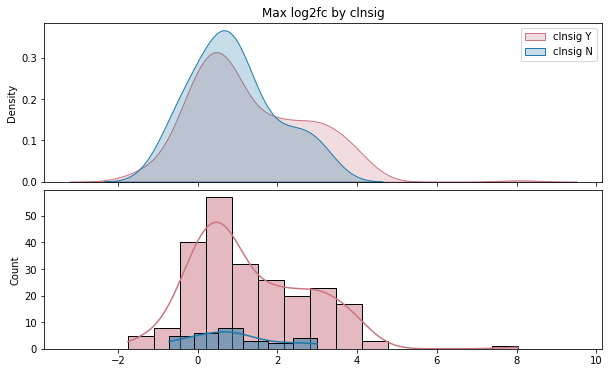

In [ ]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='clnsig Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='clnsig N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='clnsig Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='clnsig N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("Max log2fc by clnsig")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

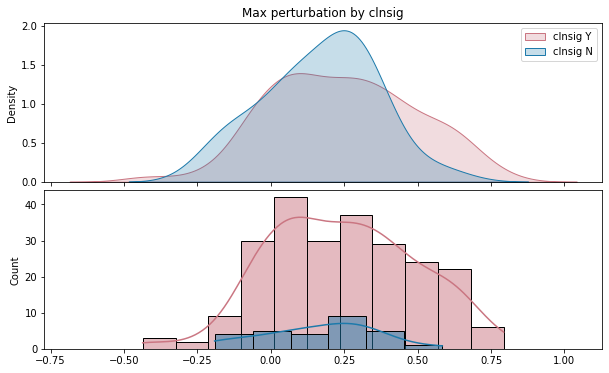

In [ ]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation"].to_numpy(), label='clnsig Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation"].to_numpy(), label='clnsig N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation"].to_numpy(), label='clnsig Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation"].to_numpy(), label='clnsig N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("Max perturbation by clnsig")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

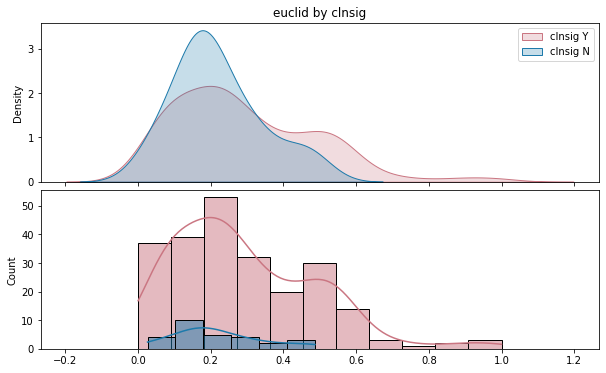

In [ ]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["ppi_score_final_euclidean"].to_numpy(), label='clnsig Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["ppi_score_final_euclidean"].to_numpy(), label='clnsig N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["ppi_score_final_euclidean"].to_numpy(), label='clnsig Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["ppi_score_final_euclidean"].to_numpy(), label='clnsig N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("euclid by clnsig")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

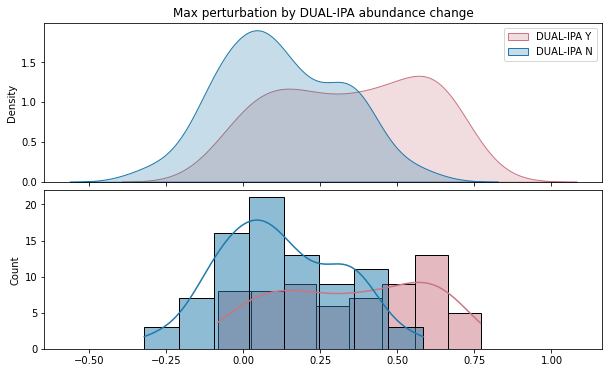

In [ ]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["max_perturbation"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["max_perturbation"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["max_perturbation"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["max_perturbation"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("Max perturbation by DUAL-IPA abundance change")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

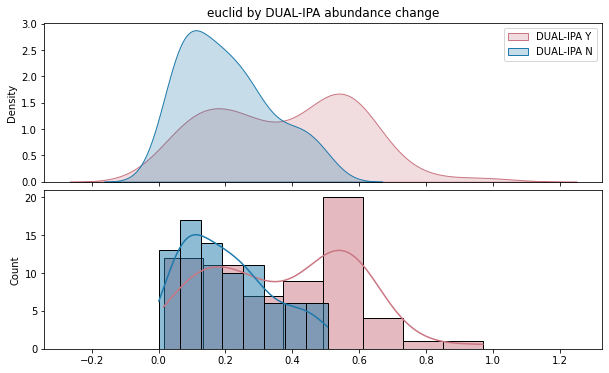

In [ ]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["ppi_score_final_euclidean"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["ppi_score_final_euclidean"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["ppi_score_final_euclidean"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["ppi_score_final_euclidean"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("euclid by DUAL-IPA abundance change")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

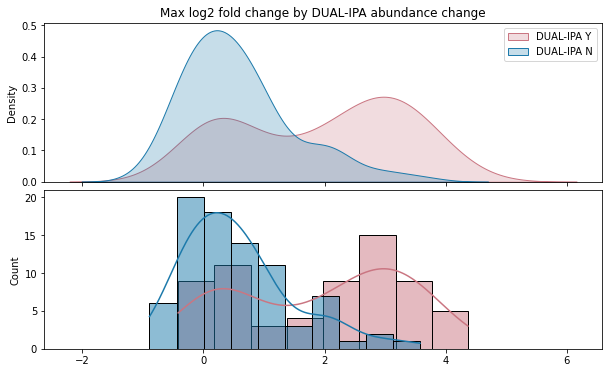

In [ ]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["max_log2_fold_change"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["max_log2_fold_change"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["max_log2_fold_change"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["max_log2_fold_change"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("Max log2 fold change by DUAL-IPA abundance change")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

In [ ]:
all_variants_df_ppi_pl

symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,StarStatus,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,num_edges,inheritance_pattern,inheritance_source,rsa,plddt
str,str,str,str,i64,f64,str,str,str,f64,f64,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,f64,bool,f64,bool,f64,f64,f64,f64,f64,str,str,f64,f64,i64,str,str,f64,f64
"""EZH2""","""EZH2_Arg684Cys""","""ENSG00000106462""","""NC_000007.14:148809370:G:A""",143,213584.0,"""2050C>T""","""Arg684Cys""","""1_Pathogenic""",null,2.0,"""0.9989""","""0.99217""","""P""","""-13.11""","""0.89908""","""D""",null,null,null,null,null,null,null,null,null,0.227048,false,1.597322,0.18009,0.18009,1.597322,0.675656,"""I""","""QW""",-0.373952,0.481586,1,null,null,null,null
"""PTS""","""PTS_Arg25Gln""","""ENSG00000150787""","""NC_000011.10:112226517:G:A""",145,200059.0,"""74G>A""","""Arg25Gln""","""1_Pathogenic""",6.9900e-7,2.0,"""0.5313""","""0.65923""","""A""","""-8.228""","""0.62687""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.096126,false,0.767416,-0.076245,0.076245,0.767416,-0.38192,"""QW""","""QW""",0.303075,0.251573,1,"""autosomal recessive""","""OMIM""",0.254032,98.45
"""PTS""","""PTS_Asp116Gly""","""ENSG00000150787""","""NC_000011.10:112233464:A:G""",145,200065.0,"""347A>G""","""Asp116Gly""","""3_Conflicting""",0.000004,1.0,"""0.1184""","""0.24328""","""B""","""-7.521""","""0.57830""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.035047,false,1.124227,0.027799,0.027799,1.124227,0.168933,"""QW""","""QW""",-0.1105,0.251573,1,"""autosomal recessive""","""OMIM""",0.392638,98.63
"""MVK""","""MVK_His20Pro""","""ENSG00000110921""","""NC_000012.12:109574881:A:C""",281,3.0,"""59A>C""","""His20Pro""","""1_Pathogenic""",0.00001,2.0,"""0.906""","""0.85569""","""LP""","""-14.191""","""0.93673""","""D""",94.91,0.043478,"""<10""",""">90""",1.094888,"""Uncertain""","""Increase""",0.662373,false,0.156925,false,2.766949,0.12447,0.12447,2.766949,1.468296,"""QN""","""QN""",-0.638591,0.194913,1,"""multiple""","""OMIM""",0.043478,94.91
"""MVK""","""MVK_Ser52Asn""","""ENSG00000110921""","""NC_000012.12:109576074:G:A""",281,5.0,"""155G>A""","""Ser52Asn""","""2_Benign""",0.110614,2.0,"""0.0898""","""0.12616""","""LB""","""-2.335""","""0.04755""","""T""",96.01,0.176923,"""10-90""",""">90""",0.332799,"""N""","""Increase""",null,null,0.076071,false,0.763612,-0.060338,0.060338,0.763612,-0.389088,"""QW""","""QW""",0.309565,0.194913,1,"""multiple""","""OMIM""",0.176923,96.01
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""KCNJ2""","""KCNJ2_Arg312His""","""ENSG00000123700""","""NC_000017.11:70175974:G:A""",100016069,2649.0,"""935G>A""","""Arg312His""","""1_Pathogenic""",6.8405e-7,2.0,"""0.9769""","""0.91488""","""LP""","""-11.524""","""0.82509""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.441451,false,4.001877,0.412944,0.412944,4.001877,2.000677,"""QN""","""QN""",-0.707648,0.480679,2,"""autosomal dominant""","""OMIM""",0.181452,95.87
"""KCNJ2""","""KCNJ2_Glu349Lys""","""ENSG00000123700""","""NC_000017.11:70176084:G:A""",100016069,2654.0,"""1045G>A""","""Glu349Lys""","""3_Conflicting""",0.000013,1.0,"""0.1656""","""0.38882""","""B""","""-8.869""","""0.66926""","""D""",97.03,0.7371134,"""10-90""",""">90""",-2.39893,"""Uncertain""","""Increase""",null,null,0.48668,false,5.449343,0.449484,0.449484,5.449343,2.446082,"""QN""","""QN""",-0.785303,0.480679,2,"""autosomal dominant""","""OMIM""",0.737113,97.03
"""KCNJ2""","""KCNJ2_Thr400Met""

In [ ]:
def plot_assay_hit_by_category(df, hit_col, cat_cols, title="", ax=None):
    """
    plot_assay_hit_by_category
    ==========================
    
    Create a paired horizontal bar chart that shows, for every category in
    `cat_cols`, both the **total number of observations** and the **number of
    positive hits** (as defined by `hit_col`).  The chart also annotates the
    hit-rate as a percentage.
    
    Parameters
    ----------
    df : polars.DataFrame
        Input table containing at least the columns listed in `cat_cols` and a
        boolean column indicating hits.
    hit_col : str
        Name of the boolean column that flags hits (e.g. `"is_hit"`).
    cat_cols : str or list[str]
        Column(s) that define the categorical grouping(s).  If a single string is
        supplied it is handled automatically.
    title : str, optional
        Title placed above the plot.
    ax : matplotlib.axes.Axes, optional
        Pre-existing axes to draw on.  If None, a new figure and axes are created.
    
    Returns
    -------
    polars.DataFrame
        A tidy frame with one row per category, containing:
            - the grouping key(s)
            - total_counts   : total observations in that category
            - hit_counts     : observations that were hits
            - hit_perc       : hit rate in percent (hit_counts / total_counts * 100)
    
    Example
    -------
    >>> plot_assay_hit_by_category(
    ...     df=my_data,
    ...     hit_col="is_hit",
    ...     cat_cols="clinvar_clnsig_clean",
    ...     title="Hit rate by ClinVar significance"
    ... )
    """
    # --- compute hit counts and percentages ---
    df_tot_cnt_per_cat = (
        df.group_by(cat_cols)
        .len()
        .rename({"len": "total_counts"})
    )
    df_hit_cnt_per_cat = (
        df.unique("gene_variant")
        .filter(pl.col(hit_col))
        .group_by(cat_cols)
        .len()
        .rename({"len": "hit_counts"})
    )

    img_hits_perc_df = (
        df_tot_cnt_per_cat.join(
            df_hit_cnt_per_cat,
            on=cat_cols,
            how="left"
        )
        .fill_null(0)
        .with_columns(
            (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
        )
        .sort(cat_cols)
    )

    # --- plotting ---
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(6, img_hits_perc_df.shape[0]))

    plot_df = img_hits_perc_df.to_pandas()

    # total bars (blue)
    sns.barplot(
        data=plot_df,
        y=cat_cols if isinstance(cat_cols, str) else cat_cols[-1],
        x="total_counts",
        color="steelblue",
        label="Total count",
        ax=ax
    )

    # hit bars (red)
    sns.barplot(
        data=plot_df,
        y=cat_cols if isinstance(cat_cols, str) else cat_cols[-1],
        x="hit_counts",
        color="tomato",
        label="Hit count",
        ax=ax
    )

    ax.set_title(title)
    ax.grid(alpha=.2)

    # percentage annotations
    max_tot = plot_df["total_counts"].max()
    for idx, row in plot_df.iterrows():
        ax.text(
            row["hit_counts"] + max_tot * 0.01,
            idx,
            f"{row['hit_perc']:.1f}%",
            va="center",
            ha="left",
            fontweight="bold",
            fontsize=12,
            color="black"
        )

    return img_hits_perc_df

In [ ]:
all_variants_df_ppi_pl

symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,StarStatus,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,num_edges,inheritance_pattern,inheritance_source,rsa,plddt
str,str,str,str,i64,f64,str,str,str,f64,f64,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,f64,bool,f64,bool,f64,f64,f64,f64,f64,str,str,f64,f64,i64,str,str,f64,f64
"""EZH2""","""EZH2_Arg684Cys""","""ENSG00000106462""","""NC_000007.14:148809370:G:A""",143,213584.0,"""2050C>T""","""Arg684Cys""","""1_Pathogenic""",null,2.0,"""0.9989""","""0.99217""","""P""","""-13.11""","""0.89908""","""D""",null,null,null,null,null,null,null,null,null,0.227048,false,1.597322,0.18009,0.18009,1.597322,0.675656,"""I""","""QW""",-0.373952,0.481586,1,null,null,null,null
"""PTS""","""PTS_Arg25Gln""","""ENSG00000150787""","""NC_000011.10:112226517:G:A""",145,200059.0,"""74G>A""","""Arg25Gln""","""1_Pathogenic""",6.9900e-7,2.0,"""0.5313""","""0.65923""","""A""","""-8.228""","""0.62687""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.096126,false,0.767416,-0.076245,0.076245,0.767416,-0.38192,"""QW""","""QW""",0.303075,0.251573,1,"""autosomal recessive""","""OMIM""",0.254032,98.45
"""PTS""","""PTS_Asp116Gly""","""ENSG00000150787""","""NC_000011.10:112233464:A:G""",145,200065.0,"""347A>G""","""Asp116Gly""","""3_Conflicting""",0.000004,1.0,"""0.1184""","""0.24328""","""B""","""-7.521""","""0.57830""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.035047,false,1.124227,0.027799,0.027799,1.124227,0.168933,"""QW""","""QW""",-0.1105,0.251573,1,"""autosomal recessive""","""OMIM""",0.392638,98.63
"""MVK""","""MVK_His20Pro""","""ENSG00000110921""","""NC_000012.12:109574881:A:C""",281,3.0,"""59A>C""","""His20Pro""","""1_Pathogenic""",0.00001,2.0,"""0.906""","""0.85569""","""LP""","""-14.191""","""0.93673""","""D""",94.91,0.043478,"""<10""",""">90""",1.094888,"""Uncertain""","""Increase""",0.662373,false,0.156925,false,2.766949,0.12447,0.12447,2.766949,1.468296,"""QN""","""QN""",-0.638591,0.194913,1,"""multiple""","""OMIM""",0.043478,94.91
"""MVK""","""MVK_Ser52Asn""","""ENSG00000110921""","""NC_000012.12:109576074:G:A""",281,5.0,"""155G>A""","""Ser52Asn""","""2_Benign""",0.110614,2.0,"""0.0898""","""0.12616""","""LB""","""-2.335""","""0.04755""","""T""",96.01,0.176923,"""10-90""",""">90""",0.332799,"""N""","""Increase""",null,null,0.076071,false,0.763612,-0.060338,0.060338,0.763612,-0.389088,"""QW""","""QW""",0.309565,0.194913,1,"""multiple""","""OMIM""",0.176923,96.01
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""KCNJ2""","""KCNJ2_Arg312His""","""ENSG00000123700""","""NC_000017.11:70175974:G:A""",100016069,2649.0,"""935G>A""","""Arg312His""","""1_Pathogenic""",6.8405e-7,2.0,"""0.9769""","""0.91488""","""LP""","""-11.524""","""0.82509""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.441451,false,4.001877,0.412944,0.412944,4.001877,2.000677,"""QN""","""QN""",-0.707648,0.480679,2,"""autosomal dominant""","""OMIM""",0.181452,95.87
"""KCNJ2""","""KCNJ2_Glu349Lys""","""ENSG00000123700""","""NC_000017.11:70176084:G:A""",100016069,2654.0,"""1045G>A""","""Glu349Lys""","""3_Conflicting""",0.000013,1.0,"""0.1656""","""0.38882""","""B""","""-8.869""","""0.66926""","""D""",97.03,0.7371134,"""10-90""",""">90""",-2.39893,"""Uncertain""","""Increase""",null,null,0.48668,false,5.449343,0.449484,0.449484,5.449343,2.446082,"""QN""","""QN""",-0.785303,0.480679,2,"""autosomal dominant""","""OMIM""",0.737113,97.03
"""KCNJ2""","""KCNJ2_Thr400Met""

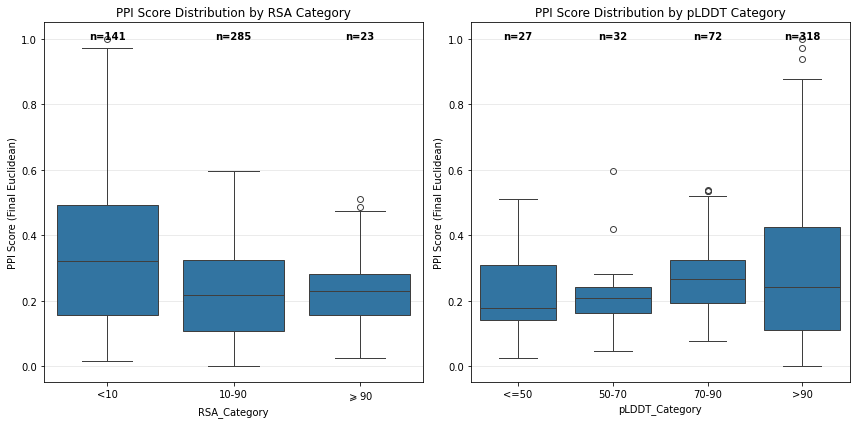

RSA Category Summary:
               count   mean  median    std
RSA_Category                              
<10              141  0.342   0.323  0.220
10-90            285  0.236   0.218  0.147
$\geqslant$90     23  0.234   0.229  0.131

pLDDT Category Summary:
                count   mean  median    std
pLDDT_Category                             
<=50               27  0.226   0.178  0.140
50-70              32  0.208   0.207  0.103
70-90              72  0.266   0.267  0.117
>90               318  0.280   0.243  0.197


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/3282343266.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rsa_summary = rsa_data.groupby('RSA_Category')['ppi_score_final_euclidean'].agg(['count', 'mean', 'median', 'std']).round(3)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_7541/3282343266.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plddt_summary = plddt_data.groupby('pLDDT_Category')['ppi_score_final_euclidean'].agg(['count', 'mean', 'median', 'std']).round(3)


In [ ]:
# Set the proper order for both RSA and pLDDT categories
rsa_order = ['<10', '10-90', '$\geqslant$90']
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = all_variants_df_ppi_pl.to_pandas()

# Set categorical order for both RSA and pLDDT
all_variants_df_ppi_pd['RSA_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['RSA_Category'], 
    categories=rsa_order, 
    ordered=True
)
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# RSA Category boxplot
rsa_data = all_variants_df_ppi_pd.dropna(subset=['RSA_Category', 'ppi_score_final_euclidean'])
sns.boxplot(data=rsa_data, x='RSA_Category', y='ppi_score_final_euclidean', ax=axes[0])
axes[0].set_title('PPI Score Distribution by RSA Category')
axes[0].set_ylabel('PPI Score (Final Euclidean)')
axes[0].grid(alpha=0.3, axis='y')

# Add sample sizes for RSA categories (using ordered categories)
for i, category in enumerate(rsa_order):
    n = len(rsa_data[rsa_data['RSA_Category'] == category])
    axes[0].text(i, axes[0].get_ylim()[1] * 0.95, f'n={n}', ha='center', fontweight='bold')

# pLDDT Category boxplot  
plddt_data = all_variants_df_ppi_pd.dropna(subset=['pLDDT_Category', 'ppi_score_final_euclidean'])
sns.boxplot(data=plddt_data, x='pLDDT_Category', y='ppi_score_final_euclidean', ax=axes[1])
axes[1].set_title('PPI Score Distribution by pLDDT Category')
axes[1].set_ylabel('PPI Score (Final Euclidean)')
axes[1].grid(alpha=0.3, axis='y')

# Add sample sizes for pLDDT categories
for i, category in enumerate(plddt_order):
    n = len(plddt_data[plddt_data['pLDDT_Category'] == category])
    axes[1].text(i, axes[1].get_ylim()[1] * 0.95, f'n={n}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("RSA Category Summary:")
rsa_summary = rsa_data.groupby('RSA_Category')['ppi_score_final_euclidean'].agg(['count', 'mean', 'median', 'std']).round(3)
print(rsa_summary)

print("\npLDDT Category Summary:")
plddt_summary = plddt_data.groupby('pLDDT_Category')['ppi_score_final_euclidean'].agg(['count', 'mean', 'median', 'std']).round(3)
print(plddt_summary)

pLDDT_Category,total_counts,hit_counts,hit_perc
cat,u32,u32,f64
"""50-70""",32,1,3.125
"""70-90""",72,4,5.555556
"""<=50""",27,1,3.703704
""">90""",318,52,16.352201


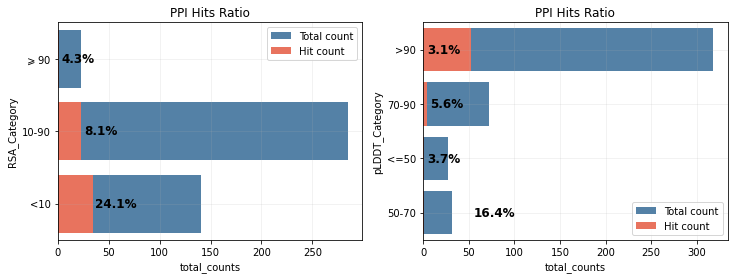

In [ ]:
# Set the proper order for pLDDT categories
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = all_variants_df_ppi_pl.to_pandas()
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)
all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi_pd)

fig, axes = plt.subplots(1,2,figsize=(12,4))
plot_assay_hit_by_category(all_variants_df_ppi_pl.drop_nulls(subset='RSA_Category'), "ppi_hit", "RSA_Category", f"PPI Hits Ratio", ax=axes[0])
plot_assay_hit_by_category(all_variants_df_ppi_pl.drop_nulls(subset='pLDDT_Category'), "ppi_hit", "pLDDT_Category", f"PPI Hits Ratio", ax=axes[1])

In [ ]:
all_variants_df_ppi_pl

symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,StarStatus,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,num_edges,inheritance_pattern,inheritance_source,rsa,plddt
str,str,str,str,i64,f64,str,str,str,f64,f64,str,str,str,str,str,str,f64,f64,str,cat,f64,str,str,f64,bool,f64,bool,f64,f64,f64,f64,f64,str,str,f64,f64,i64,str,str,f64,f64
"""EZH2""","""EZH2_Arg684Cys""","""ENSG00000106462""","""NC_000007.14:148809370:G:A""",143,213584.0,"""2050C>T""","""Arg684Cys""","""1_Pathogenic""",null,2.0,"""0.9989""","""0.99217""","""P""","""-13.11""","""0.89908""","""D""",null,null,null,null,null,null,null,null,null,0.227048,false,1.597322,0.18009,0.18009,1.597322,0.675656,"""I""","""QW""",-0.373952,0.481586,1,null,null,null,null
"""PTS""","""PTS_Arg25Gln""","""ENSG00000150787""","""NC_000011.10:112226517:G:A""",145,200059.0,"""74G>A""","""Arg25Gln""","""1_Pathogenic""",6.9900e-7,2.0,"""0.5313""","""0.65923""","""A""","""-8.228""","""0.62687""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.096126,false,0.767416,-0.076245,0.076245,0.767416,-0.38192,"""QW""","""QW""",0.303075,0.251573,1,"""autosomal recessive""","""OMIM""",0.254032,98.45
"""PTS""","""PTS_Asp116Gly""","""ENSG00000150787""","""NC_000011.10:112233464:A:G""",145,200065.0,"""347A>G""","""Asp116Gly""","""3_Conflicting""",0.000004,1.0,"""0.1184""","""0.24328""","""B""","""-7.521""","""0.57830""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.035047,false,1.124227,0.027799,0.027799,1.124227,0.168933,"""QW""","""QW""",-0.1105,0.251573,1,"""autosomal recessive""","""OMIM""",0.392638,98.63
"""MVK""","""MVK_His20Pro""","""ENSG00000110921""","""NC_000012.12:109574881:A:C""",281,3.0,"""59A>C""","""His20Pro""","""1_Pathogenic""",0.00001,2.0,"""0.906""","""0.85569""","""LP""","""-14.191""","""0.93673""","""D""",94.91,0.043478,"""<10""",""">90""",1.094888,"""Uncertain""","""Increase""",0.662373,false,0.156925,false,2.766949,0.12447,0.12447,2.766949,1.468296,"""QN""","""QN""",-0.638591,0.194913,1,"""multiple""","""OMIM""",0.043478,94.91
"""MVK""","""MVK_Ser52Asn""","""ENSG00000110921""","""NC_000012.12:109576074:G:A""",281,5.0,"""155G>A""","""Ser52Asn""","""2_Benign""",0.110614,2.0,"""0.0898""","""0.12616""","""LB""","""-2.335""","""0.04755""","""T""",96.01,0.176923,"""10-90""",""">90""",0.332799,"""N""","""Increase""",null,null,0.076071,false,0.763612,-0.060338,0.060338,0.763612,-0.389088,"""QW""","""QW""",0.309565,0.194913,1,"""multiple""","""OMIM""",0.176923,96.01
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""KCNJ2""","""KCNJ2_Arg312His""","""ENSG00000123700""","""NC_000017.11:70175974:G:A""",100016069,2649.0,"""935G>A""","""Arg312His""","""1_Pathogenic""",6.8405e-7,2.0,"""0.9769""","""0.91488""","""LP""","""-11.524""","""0.82509""","""D""",null,null,"""10-90""",""">90""",null,null,null,null,null,0.441451,false,4.001877,0.412944,0.412944,4.001877,2.000677,"""QN""","""QN""",-0.707648,0.480679,2,"""autosomal dominant""","""OMIM""",0.181452,95.87
"""KCNJ2""","""KCNJ2_Glu349Lys""","""ENSG00000123700""","""NC_000017.11:70176084:G:A""",100016069,2654.0,"""1045G>A""","""Glu349Lys""","""3_Conflicting""",0.000013,1.0,"""0.1656""","""0.38882""","""B""","""-8.869""","""0.66926""","""D""",97.03,0.7371134,"""10-90""",""">90""",-2.39893,"""Uncertain""","""Increase""",null,null,0.48668,false,5.449343,0.449484,0.449484,5.449343,2.446082,"""QN""","""QN""",-0.785303,0.480679,2,"""autosomal dominant""","""OMIM""",0.737113,97.03
"""KCNJ2""","""KCNJ2_Thr400Met""

,clinvar_clnsig_clean,count,percent
0,1_Pathogenic,234,49.787234
1,2_Benign,28,5.957447
2,3_Conflicting,75,15.957447
3,4_VUS,91,19.361702
4,5_Others,42,8.936170


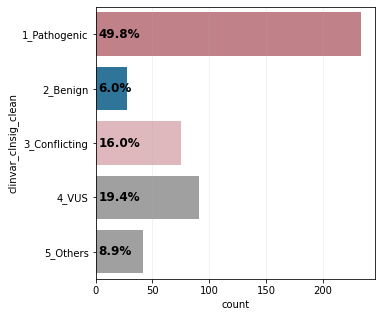

In [ ]:

fig, axes = plt.subplots(1,figsize=(5,5))
plot_cat_count_perc(
    all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean") != '6_No_ClinVar'),
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes,
    palette=palette_dict["clinvar_clnsig_clean"]
)

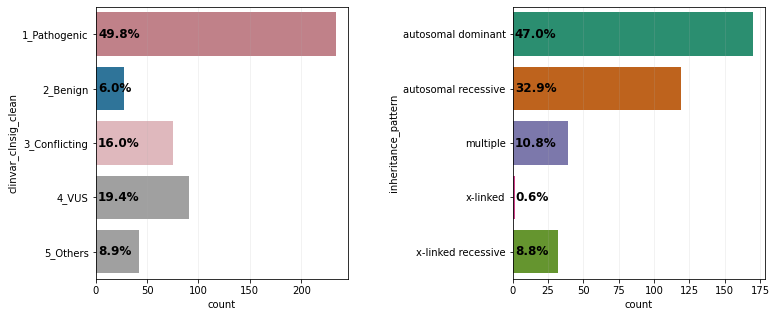

In [ ]:

fig, axes = plt.subplots(1,2,figsize=(12,5))
plot_cat_count_perc(
    all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean") != '6_No_ClinVar'),
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)

inh_cats = ['autosomal dominant', 'autosomal recessive', 'x-linked','x-linked recessive', 'multiple']

# drop categories that are not in inh_cats
all_variants_df_ppi_pl_plot = all_variants_df_ppi_pl.filter(pl.col("inheritance_pattern").is_in(inh_cats))

plot_cat_count_perc(
    all_variants_df_ppi_pl_plot,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)
# plt.suptitle(f"{all_variants_df_ppi_pl.unique('gene_variant').shape[0]} Variants from {all_variants_df_ppi_pl.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=0.65)
plt.show()

In [ ]:
all_variants_df_ppi_pd

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,num_edges,inheritance_pattern,inheritance_source,rsa,plddt
0,EZH2,EZH2_Arg684Cys,ENSG00000106462,NC_000007.14:148809370:G:A,143,213584.0,2050C>T,Arg684Cys,1_Pathogenic,NaN,...,0.675656,I,QW,-0.373952,0.481586,1,None,None,NaN,NaN
1,PTS,PTS_Arg25Gln,ENSG00000150787,NC_000011.10:112226517:G:A,145,200059.0,74G>A,Arg25Gln,1_Pathogenic,6.990040e-07,...,-0.381920,QW,QW,0.303075,0.251573,1,autosomal recessive,OMIM,0.254032,98.45
2,PTS,PTS_Asp116Gly,ENSG00000150787,NC_000011.10:112233464:A:G,145,200065.0,347A>G,Asp116Gly,3_Conflicting,4.105980e-06,...,0.168933,QW,QW,-0.110500,0.251573,1,autosomal recessive,OMIM,0.392638,98.63
3,MVK,MVK_His20Pro,ENSG00000110921,NC_000012.12:109574881:A:C,281,3.0,59A>C,His20Pro,1_Pathogenic,9.603990e-06,...,1.468296,QN,QN,-0.638591,0.194913,1,multiple,OMIM,0.043478,94.91
4,MVK,MVK_Ser52Asn,ENSG00000110921,NC_000012.12:109576074:G:A,281,5.0,155G>A,Ser52Asn,2_Benign,1.106140e-01,...,-0.389088,QW,QW,0.309565,0.194913,1,multiple,OMIM,0.176923,96.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,KCNJ2,KCNJ2_Arg312His,ENSG00000123700,NC_000017.11:70175974:G:A,100016069,2649.0,935G>A,Arg312His,1_Pathogenic,6.840540e-07,...,2.000677,QN,QN,-0.707648,0.480679,2,autosomal dominant,OMIM,0.181452,95.87
471,KCNJ2,KCNJ2_Glu349Lys,ENSG00000123700,NC_000017.11:70176084:G:A,100016069,2654.0,1045G>A,Glu349Lys,3_Conflicting,1.299710e-05,...,2.446082,QN,QN,-0.785303,0.480679,2,autosomal dominant,OMIM,0.737113,97.03
472,KCNJ2,KCNJ2_Thr400Met,ENSG00000123700,NC_000017.11:70176238:C:T,100016069,2656.0,1199C>T,Thr400Met,3_Conflicting,5.198930e-05,...,2.666812,QN,QN,-0.741376,0.480679,2,autosomal dominant,OMIM,0.838028,40.68
473,KCNJ2,KCNJ2_Pro415Leu,ENSG00000123700,NC_000017.11:70176283:C:T,100016069,2659.0,1244C>T,Pro415Leu,3_Conflicting,1.238130e-04,...,2.649872,QN,QN,-0.787751,0.480679,2,autosomal dominant,OMIM,0.948529,43.90


# Exploring Alternative Metrics for Edgetic Classification

The euclidean distance metric shows good separation between ClinVar pathogenic and benign variants, but may be too focused on complete protein disruption rather than edgetic effects (subset of interactions disrupted). 

Let's explore whether `max_perturbation` and `max_log2_fold_change` can capture pathogenic variants that are missed by the euclidean distance, particularly those with edgetic effects.

In [ ]:
all_variants_df_ppi_pl_pd = all_variants_df_ppi_pl.to_pandas()
all_variants_df_ppi_pl_pd

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,max_perturbation_fold_abs,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,inheritance_pattern,inheritance_source,rsa,plddt
0,EZH2,EZH2_Arg684Cys,ENSG00000106462,NC_000007.14:148809370:G:A,143,213584.0,2050C>T,Arg684Cys,1_Pathogenic,NaN,...,1.597322,0.675656,I,QW,-0.373952,0.481586,None,None,NaN,NaN
1,PTS,PTS_Arg25Gln,ENSG00000150787,NC_000011.10:112226517:G:A,145,200059.0,74G>A,Arg25Gln,1_Pathogenic,6.990040e-07,...,0.767416,-0.381920,QW,QW,0.303075,0.251573,autosomal recessive,OMIM,0.254032,98.45
2,PTS,PTS_Asp116Gly,ENSG00000150787,NC_000011.10:112233464:A:G,145,200065.0,347A>G,Asp116Gly,3_Conflicting,4.105980e-06,...,1.124227,0.168933,QW,QW,-0.110500,0.251573,autosomal recessive,OMIM,0.392638,98.63
3,MVK,MVK_His20Pro,ENSG00000110921,NC_000012.12:109574881:A:C,281,3.0,59A>C,His20Pro,1_Pathogenic,9.603990e-06,...,2.766949,1.468296,QN,QN,-0.638591,0.194913,multiple,OMIM,0.043478,94.91
4,MVK,MVK_Ser52Asn,ENSG00000110921,NC_000012.12:109576074:G:A,281,5.0,155G>A,Ser52Asn,2_Benign,1.106140e-01,...,0.763612,-0.389088,QW,QW,0.309565,0.194913,multiple,OMIM,0.176923,96.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,KCNJ2,KCNJ2_Arg312His,ENSG00000123700,NC_000017.11:70175974:G:A,100016069,2649.0,935G>A,Arg312His,1_Pathogenic,6.840540e-07,...,4.001877,2.000677,QN,QN,-0.707648,0.480679,autosomal dominant,OMIM,0.181452,95.87
471,KCNJ2,KCNJ2_Glu349Lys,ENSG00000123700,NC_000017.11:70176084:G:A,100016069,2654.0,1045G>A,Glu349Lys,3_Conflicting,1.299710e-05,...,5.449343,2.446082,QN,QN,-0.785303,0.480679,autosomal dominant,OMIM,0.737113,97.03
472,KCNJ2,KCNJ2_Thr400Met,ENSG00000123700,NC_000017.11:70176238:C:T,100016069,2656.0,1199C>T,Thr400Met,3_Conflicting,5.198930e-05,...,6.350245,2.666812,QN,QN,-0.741376,0.480679,autosomal dominant,OMIM,0.838028,40.68
473,KCNJ2,KCNJ2_Pro415Leu,ENSG00000123700,NC_000017.11:70176283:C:T,100016069,2659.0,1244C>T,Pro415Leu,3_Conflicting,1.238130e-04,...,6.276117,2.649872,QN,QN,-0.787751,0.480679,autosomal dominant,OMIM,0.948529,43.90


In [ ]:
all_variants_df_ppi_pd

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,max_perturbation_fold_abs,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,inheritance_pattern,inheritance_source,rsa,plddt
0,EZH2,EZH2_Arg684Cys,ENSG00000106462,NC_000007.14:148809370:G:A,143,213584.0,2050C>T,Arg684Cys,1_Pathogenic,NaN,...,1.597322,0.675656,I,QW,-0.373952,0.481586,None,None,NaN,NaN
1,PTS,PTS_Arg25Gln,ENSG00000150787,NC_000011.10:112226517:G:A,145,200059.0,74G>A,Arg25Gln,1_Pathogenic,6.990040e-07,...,0.767416,-0.381920,QW,QW,0.303075,0.251573,autosomal recessive,OMIM,0.254032,98.45
2,PTS,PTS_Asp116Gly,ENSG00000150787,NC_000011.10:112233464:A:G,145,200065.0,347A>G,Asp116Gly,3_Conflicting,4.105980e-06,...,1.124227,0.168933,QW,QW,-0.110500,0.251573,autosomal recessive,OMIM,0.392638,98.63
3,MVK,MVK_His20Pro,ENSG00000110921,NC_000012.12:109574881:A:C,281,3.0,59A>C,His20Pro,1_Pathogenic,9.603990e-06,...,2.766949,1.468296,QN,QN,-0.638591,0.194913,multiple,OMIM,0.043478,94.91
4,MVK,MVK_Ser52Asn,ENSG00000110921,NC_000012.12:109576074:G:A,281,5.0,155G>A,Ser52Asn,2_Benign,1.106140e-01,...,0.763612,-0.389088,QW,QW,0.309565,0.194913,multiple,OMIM,0.176923,96.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,KCNJ2,KCNJ2_Arg312His,ENSG00000123700,NC_000017.11:70175974:G:A,100016069,2649.0,935G>A,Arg312His,1_Pathogenic,6.840540e-07,...,4.001877,2.000677,QN,QN,-0.707648,0.480679,autosomal dominant,OMIM,0.181452,95.87
471,KCNJ2,KCNJ2_Glu349Lys,ENSG00000123700,NC_000017.11:70176084:G:A,100016069,2654.0,1045G>A,Glu349Lys,3_Conflicting,1.299710e-05,...,5.449343,2.446082,QN,QN,-0.785303,0.480679,autosomal dominant,OMIM,0.737113,97.03
472,KCNJ2,KCNJ2_Thr400Met,ENSG00000123700,NC_000017.11:70176238:C:T,100016069,2656.0,1199C>T,Thr400Met,3_Conflicting,5.198930e-05,...,6.350245,2.666812,QN,QN,-0.741376,0.480679,autosomal dominant,OMIM,0.838028,40.68
473,KCNJ2,KCNJ2_Pro415Leu,ENSG00000123700,NC_000017.11:70176283:C:T,100016069,2659.0,1244C>T,Pro415Leu,3_Conflicting,1.238130e-04,...,6.276117,2.649872,QN,QN,-0.787751,0.480679,autosomal dominant,OMIM,0.948529,43.90


Variants with complete PPI metrics: 475


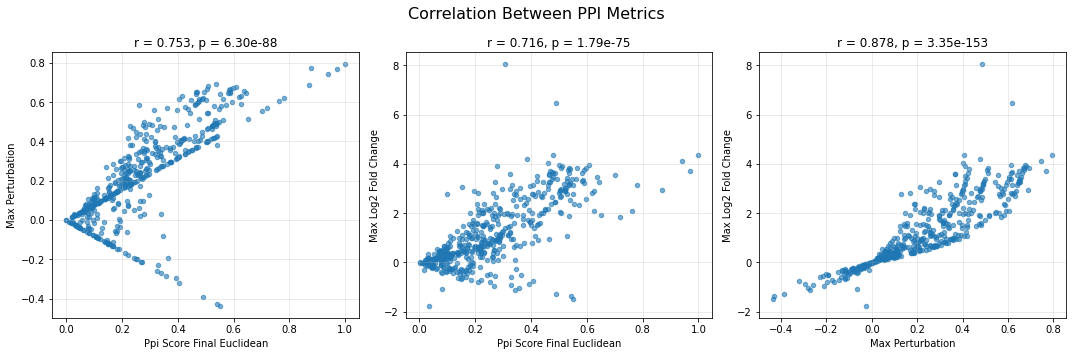

ppi_score_final_euclidean vs max_perturbation: r = 0.753, p = 6.30e-88
ppi_score_final_euclidean vs max_log2_fold_change: r = 0.716, p = 1.79e-75
max_perturbation vs max_log2_fold_change: r = 0.878, p = 3.35e-153


In [ ]:
# 1. Correlation analysis between PPI metrics
import scipy.stats as stats

# Filter to variants with all three metrics available
complete_metrics = all_variants_df_ppi_pd

# .filter(
#     pl.col("ppi_score_final_euclidean").is_not_null() &
#     pl.col("max_perturbation").is_not_null() &
#     pl.col("max_log2_fold_change").is_not_null()
# ).to_pandas()

print(f"Variants with complete PPI metrics: {len(complete_metrics)}")

# Calculate correlations
metrics = ['ppi_score_final_euclidean', 'max_perturbation', 'max_log2_fold_change']
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

correlations = {}
for i, (metric1, metric2) in enumerate([
    ('ppi_score_final_euclidean', 'max_perturbation'),
    ('ppi_score_final_euclidean', 'max_log2_fold_change'),
    ('max_perturbation', 'max_log2_fold_change')
]):
    # Remove NaN and infinite values for correlation
    mask = ~(complete_metrics[metric1].isna() | complete_metrics[metric2].isna() | 
             np.isinf(complete_metrics[metric1]) | np.isinf(complete_metrics[metric2]))
    x = complete_metrics[mask][metric1]
    y = complete_metrics[mask][metric2]
    
    if len(x) > 1 and len(y) > 1:  # Need at least 2 points for correlation
        r, p_val = stats.pearsonr(x, y)
        correlations[f"{metric1} vs {metric2}"] = {'r': r, 'p': p_val}
    else:
        r, p_val = np.nan, np.nan
        correlations[f"{metric1} vs {metric2}"] = {'r': r, 'p': p_val}
    
    axes[i].scatter(x, y, alpha=0.6, s=20)
    axes[i].set_xlabel(metric1.replace('_', ' ').title())
    axes[i].set_ylabel(metric2.replace('_', ' ').title())
    axes[i].set_title(f'r = {r:.3f}, p = {p_val:.2e}')
    axes[i].grid(alpha=0.3)

plt.suptitle('Correlation Between PPI Metrics', fontsize=16)
plt.tight_layout()
plt.show()

for comparison, stats_dict in correlations.items():
    print(f"{comparison}: r = {stats_dict['r']:.3f}, p = {stats_dict['p']:.2e}")

In [ ]:
# 2. Identify pathogenic variants potentially missed by euclidean distance
# Define thresholds (can be adjusted based on distributions)
euclidean_threshold = complete_metrics['ppi_score_final_euclidean'].quantile(0.8)  # Top 25%
max_pert_threshold = complete_metrics['max_perturbation'].quantile(0.8)  # Top 25%
max_log2_threshold = complete_metrics['max_log2_fold_change'].quantile(0.8)  # Top 25%

print(f"Thresholds (75th percentile):")
print(f"Euclidean distance: {euclidean_threshold:.3f}")
print(f"Max perturbation: {max_pert_threshold:.3f}")
print(f"Max log2 fold change: {max_log2_threshold:.3f}")

# Focus on pathogenic variants
pathogenic_variants = complete_metrics[complete_metrics['clinvar_clnsig_clean'] == '1_Pathogenic'].copy()
print(f"\nPathogenic variants with complete metrics: {len(pathogenic_variants)}")

# Classify variants based on different metrics
pathogenic_variants['euclidean_high'] = pathogenic_variants['ppi_score_final_euclidean'] >= euclidean_threshold
pathogenic_variants['max_pert_high'] = pathogenic_variants['max_perturbation'] >= max_pert_threshold
pathogenic_variants['max_log2_high'] = pathogenic_variants['max_log2_fold_change'] >= max_log2_threshold

# Find variants missed by euclidean but caught by other metrics
missed_by_euclidean = pathogenic_variants[~pathogenic_variants['euclidean_high']]
rescued_by_max_pert = missed_by_euclidean[missed_by_euclidean['max_pert_high']]
rescued_by_max_log2 = missed_by_euclidean[missed_by_euclidean['max_log2_high']]
rescued_by_either = missed_by_euclidean[missed_by_euclidean['max_pert_high'] | missed_by_euclidean['max_log2_high']]

print(f"\nPathogenic variants analysis:")
print(f"Total pathogenic: {len(pathogenic_variants)}")
print(f"Caught by euclidean (>= {euclidean_threshold:.3f}): {pathogenic_variants['euclidean_high'].sum()}")
print(f"Missed by euclidean: {(~pathogenic_variants['euclidean_high']).sum()}")
print(f"  - Rescued by max_perturbation: {len(rescued_by_max_pert)} ({len(rescued_by_max_pert)/len(missed_by_euclidean)*100:.1f}%)")
print(f"  - Rescued by max_log2_fold_change: {len(rescued_by_max_log2)} ({len(rescued_by_max_log2)/len(missed_by_euclidean)*100:.1f}%)")
print(f"  - Rescued by either metric: {len(rescued_by_either)} ({len(rescued_by_either)/len(missed_by_euclidean)*100:.1f}%)")

Thresholds (75th percentile):
Euclidean distance: 0.427
Max perturbation: 0.423
Max log2 fold change: 2.651

Pathogenic variants with complete metrics: 234

Pathogenic variants analysis:
Total pathogenic: 234
Caught by euclidean (>= 0.427): 58
Missed by euclidean: 176
  - Rescued by max_perturbation: 12 (6.8%)
  - Rescued by max_log2_fold_change: 13 (7.4%)
  - Rescued by either metric: 17 (9.7%)


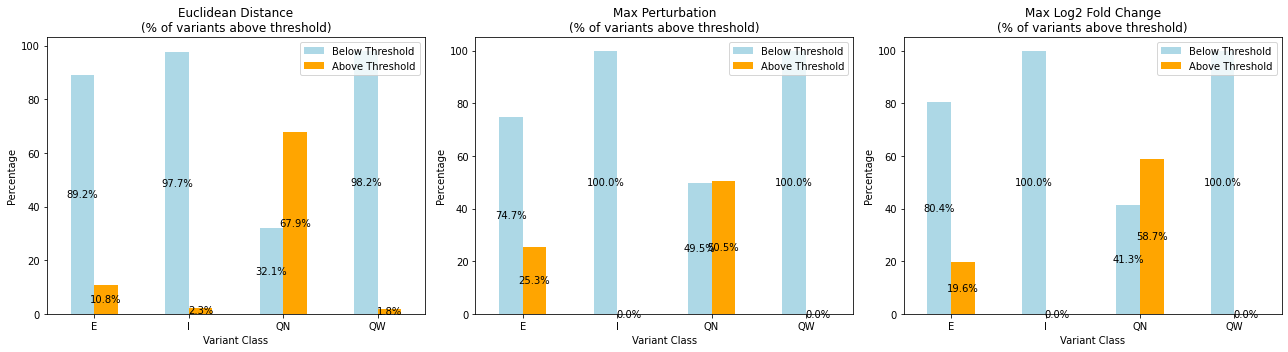

Detailed breakdown by variant class:

QW variants (n=165):
  High euclidean: 3 (1.8%)
  High max_perturbation: 0 (0.0%)
  High max_log2_fold_change: 0 (0.0%)

E variants (n=158):
  High euclidean: 17 (10.8%)
  High max_perturbation: 40 (25.3%)
  High max_log2_fold_change: 31 (19.6%)
  Edgetic variants missed by euclidean: 141
  Rescued by alternative metrics: 32 (22.7%)

QN variants (n=109):
  High euclidean: 74 (67.9%)
  High max_perturbation: 55 (50.5%)
  High max_log2_fold_change: 64 (58.7%)


In [ ]:
# 3. Analyze variant classification (QW, E, QN) patterns across metrics
# Look at how edgetic (E) variants are distributed across different metric thresholds

variant_class_analysis = complete_metrics.copy()
variant_class_analysis['euclidean_high'] = variant_class_analysis['ppi_score_final_euclidean'] >= euclidean_threshold
variant_class_analysis['max_pert_high'] = variant_class_analysis['max_perturbation'] >= max_pert_threshold
variant_class_analysis['max_log2_high'] = variant_class_analysis['max_log2_fold_change'] >= max_log2_threshold

# Create contingency tables for each metric vs variant class
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics_analysis = [
    ('euclidean_high', 'Euclidean Distance'),
    ('max_pert_high', 'Max Perturbation'), 
    ('max_log2_high', 'Max Log2 Fold Change')
]

for i, (metric_col, metric_name) in enumerate(metrics_analysis):
    # Create crosstab
    crosstab = pd.crosstab(variant_class_analysis['variant_class'], 
                          variant_class_analysis[metric_col], 
                          normalize='index') * 100  # Convert to percentages
    
    # Plot stacked bar chart
    crosstab.plot(kind='bar', ax=axes[i], color=['lightblue', 'orange'], 
                 title=f'{metric_name}\n(% of variants above threshold)')
    axes[i].set_xlabel('Variant Class')
    axes[i].set_ylabel('Percentage')
    axes[i].legend(['Below Threshold', 'Above Threshold'])
    axes[i].tick_params(axis='x', rotation=0)
    
    # Add percentage labels on bars
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.1f%%', label_type='center')

plt.tight_layout()
plt.show()

# Print detailed breakdown
print("Detailed breakdown by variant class:")
for variant_class in ['QW', 'E', 'QN']:
    subset = variant_class_analysis[variant_class_analysis['variant_class'] == variant_class]
    if len(subset) > 0:
        print(f"\n{variant_class} variants (n={len(subset)}):")
        print(f"  High euclidean: {subset['euclidean_high'].sum()} ({subset['euclidean_high'].mean()*100:.1f}%)")
        print(f"  High max_perturbation: {subset['max_pert_high'].sum()} ({subset['max_pert_high'].mean()*100:.1f}%)")
        print(f"  High max_log2_fold_change: {subset['max_log2_high'].sum()} ({subset['max_log2_high'].mean()*100:.1f}%)")
        
        # Look at edgetic variants specifically - are they better captured by alternative metrics?
        if variant_class == 'E':
            euclidean_missed = subset[~subset['euclidean_high']]
            if len(euclidean_missed) > 0:
                rescued = euclidean_missed[euclidean_missed['max_pert_high'] | euclidean_missed['max_log2_high']]
                print(f"  Edgetic variants missed by euclidean: {len(euclidean_missed)}")
                print(f"  Rescued by alternative metrics: {len(rescued)} ({len(rescued)/len(euclidean_missed)*100:.1f}%)")

In [ ]:
missed_by_euclidean[missed_by_euclidean['max_pert_high']]

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,variant_class_log2fc,mean_relative_perturbation,mean_wt,inheritance_pattern,inheritance_source,rsa,plddt,euclidean_high,max_pert_high,max_log2_high
25,PRKAR1A,PRKAR1A_Arg335Pro,ENSG00000108946,NC_000017.11:68530307:G:C,2455,200621.0,1004G>C,Arg335Pro,1_Pathogenic,NaN,...,E,-0.251756,0.373790,autosomal dominant,OMIM,0.064516,93.38,False,True,False
43,MLH1,MLH1_Val185Gly,ENSG00000076242,NC_000003.12:37011828:T:G,2713,200837.0,554T>G,Val185Gly,1_Pathogenic,1.368700e-06,...,E,-0.634909,0.449457,autosomal dominant,GenCC,0.000000,95.47,False,True,True
80,EMD,EMD_Ser54Phe,ENSG00000102119,NC_000023.11:154379768:C:T,3535,6159.0,161C>T,Ser54Phe,1_Pathogenic,9.155850e-07,...,E,0.818024,0.336304,x-linked recessive,OMIM,0.953846,42.08,False,True,False
84,EMD,EMD_Met1Val,ENSG00000102119,NC_000023.11:154379485:A:G,3535,201190.0,1A>G,Met1Val,1_Pathogenic,9.500010e-07,...,E,0.402840,0.336304,None,None,0.696809,61.53,False,True,True
108,PLP1,PLP1_Thr43Ile,ENSG00000123560,NC_000023.11:103785705:C:T,4062,201422.0,128C>T,Thr43Ile,1_Pathogenic,NaN,...,E,-0.511337,0.484395,x-linked recessive,OMIM,0.133803,90.94,False,True,True
112,PLP1,PLP1_Asp168His,ENSG00000123560,NC_000023.11:103787951:G:C,4062,201427.0,502G>C,Asp168His,1_Pathogenic,NaN,...,E,-0.355462,0.484395,x-linked recessive,OMIM,0.141104,89.16,False,True,True
113,PLP1,PLP1_Ile152Thr,ENSG00000123560,NC_000023.11:103787904:T:C,4062,201428.0,455T>C,Ile152Thr,1_Pathogenic,NaN,...,E,-0.345557,0.484395,x-linked recessive,OMIM,0.053254,86.83,False,True,False
114,PLP1,PLP1_Ser135Phe,ENSG00000123560,NC_000023.11:103787853:C:T,4062,201429.0,404C>T,Ser135Phe,1_Pathogenic,NaN,...,E,-0.178083,0.484395,x-linked recessive,OMIM,0.130769,95.06,False,True,False
195,STXBP1,STXBP1_Arg190Trp,ENSG00000136854,NC_000009.12:127663343:C:T,7652,1800.0,568C>T,Arg190Trp,1_Pathogenic,0.000000e+00,...,E,-0.258730,0.559794,multiple,OMIM,0.000000,97.57,False,True,True
350,LITAF,LITAF_Trp116Gly,ENSG00000189067,NC_000016.10:11553564:A:C,52920,2675.0,346T>G,Trp116Gly,1_Pathogenic,NaN,...,E,0.227423,0.493621,autosomal dominant,OMIM,0.704846,88.76,False,True,True


Pathogenic variants: 234
Benign variants: 28


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/2698545842.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=auc_df, x='Metric', y='AUC', palette=colors[:len(auc_df)], ax=axes[1])


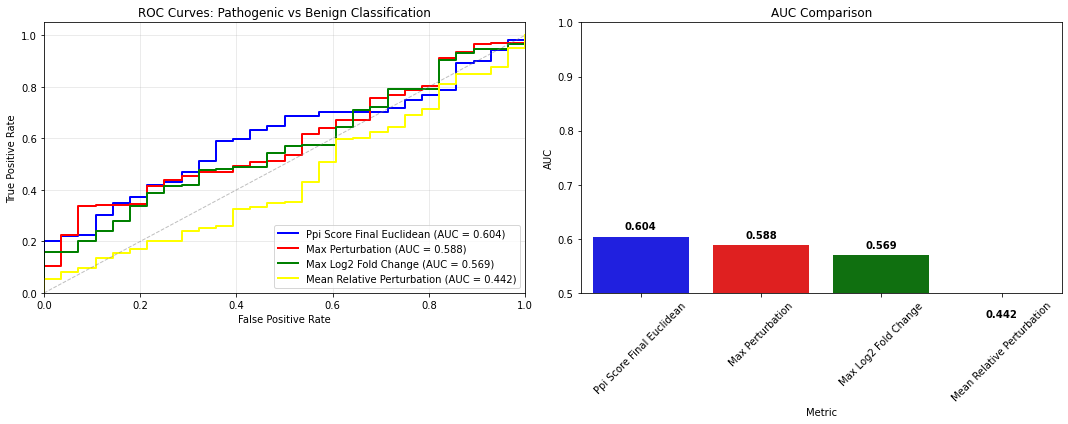


AUC Scores for Pathogenic vs Benign Classification:
Ppi Score Final Euclidean: 0.604
Max Perturbation: 0.588
Max Log2 Fold Change: 0.569
Mean Relative Perturbation: 0.442


In [ ]:
# 4. ROC analysis to compare metric performance in pathogenic vs benign classification
from sklearn.metrics import roc_curve, auc

# Filter to pathogenic and benign variants only
path_benign = complete_metrics[complete_metrics['clinvar_clnsig_clean'].isin(['1_Pathogenic', '2_Benign'])].copy()
path_benign['is_pathogenic'] = (path_benign['clinvar_clnsig_clean'] == '1_Pathogenic').astype(int)

print(f"Pathogenic variants: {path_benign['is_pathogenic'].sum()}")
print(f"Benign variants: {(1-path_benign['is_pathogenic']).sum()}")

# Calculate ROC curves for each metric
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

metrics_roc = ['ppi_score_final_euclidean', 'max_perturbation', 'max_log2_fold_change', 'mean_relative_perturbation']
colors = ['blue', 'red', 'green', 'yellow']
auc_scores = {}

# ROC curves
for metric, color in zip(metrics_roc, colors):
    # Filter out NaN and infinite values
    mask = ~(path_benign['is_pathogenic'].isna() | path_benign[metric].isna() | 
             np.isinf(path_benign[metric]))
    
    if mask.sum() > 0:  # Ensure we have data after filtering
        y_true = path_benign[mask]['is_pathogenic']
        y_score = path_benign[mask][metric]
        
        if len(y_true) > 1 and y_true.nunique() > 1:  # Need multiple classes for ROC
            fpr, tpr, _ = roc_curve(y_true, y_score)
            roc_auc = auc(fpr, tpr)
            auc_scores[metric] = roc_auc
            
            axes[0].plot(fpr, tpr, color=color, lw=2, 
                        label=f'{metric.replace("_", " ").title()} (AUC = {roc_auc:.3f})')
        else:
            print(f"Insufficient valid data for {metric} ROC analysis")
            auc_scores[metric] = np.nan
    else:
        print(f"No valid data for {metric} ROC analysis")
        auc_scores[metric] = np.nan

axes[0].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', alpha=0.5)
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves: Pathogenic vs Benign Classification')
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# AUC comparison bar plot
valid_auc_scores = {k: v for k, v in auc_scores.items() if not np.isnan(v)}
if valid_auc_scores:
    auc_df = pd.DataFrame.from_dict(valid_auc_scores, orient='index', columns=['AUC']).reset_index()
    auc_df['Metric'] = auc_df['index'].str.replace('_', ' ').str.title()

    sns.barplot(data=auc_df, x='Metric', y='AUC', palette=colors[:len(auc_df)], ax=axes[1])
    axes[1].set_title('AUC Comparison')
    axes[1].set_ylim([0.5, 1.0])
    axes[1].tick_params(axis='x', rotation=45)

    # Add AUC values on bars
    for i, (_, row) in enumerate(auc_df.iterrows()):
        axes[1].text(i, row['AUC'] + 0.01, f'{row["AUC"]:.3f}', 
                    ha='center', va='bottom', fontweight='bold')
else:
    axes[1].text(0.5, 0.5, 'No valid AUC scores', ha='center', va='center')
    axes[1].set_title('AUC Comparison - No Valid Data')

plt.tight_layout()
plt.show()

print("\nAUC Scores for Pathogenic vs Benign Classification:")
for metric, score in auc_scores.items():
    if not np.isnan(score):
        print(f"{metric.replace('_', ' ').title()}: {score:.3f}")
    else:
        print(f"{metric.replace('_', ' ').title()}: No valid data")

In [ ]:
complete_metrics['wt_class'] = ['HD' if x > 0.5 else 'LD' for x in complete_metrics['mean_wt']]

Pathogenic variants: 76
Benign variants: 3


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/115493399.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=auc_df, x='Metric', y='AUC', palette=colors[:len(auc_df)], ax=axes[1])


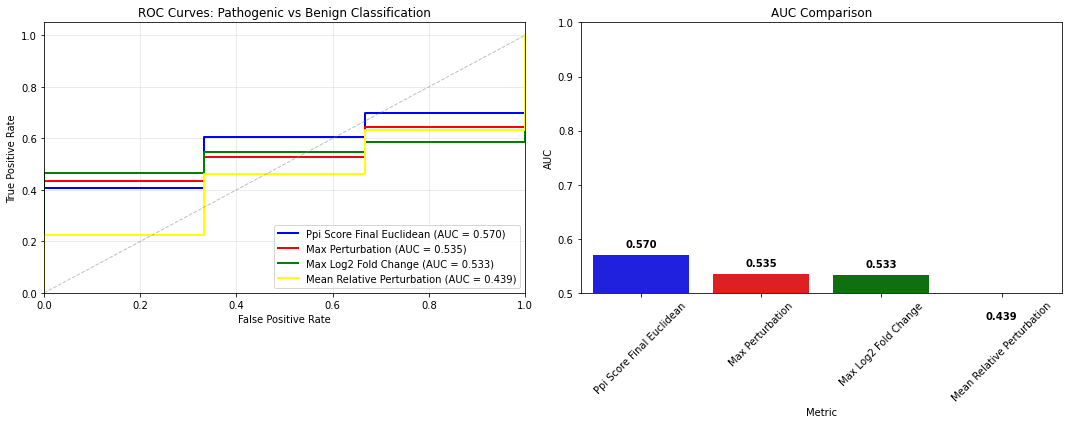


AUC Scores for Pathogenic vs Benign Classification:
Ppi Score Final Euclidean: 0.570
Max Perturbation: 0.535
Max Log2 Fold Change: 0.533
Mean Relative Perturbation: 0.439


In [ ]:
# 4. ROC analysis to compare metric performance in pathogenic vs benign classification
from sklearn.metrics import roc_curve, auc

complete_metrics_HD = complete_metrics[complete_metrics['wt_class'] == 'HD']

# Filter to pathogenic and benign variants only
path_benign = complete_metrics_HD[complete_metrics_HD['clinvar_clnsig_clean'].isin(['1_Pathogenic', '2_Benign'])].copy()
path_benign['is_pathogenic'] = (path_benign['clinvar_clnsig_clean'] == '1_Pathogenic').astype(int)

print(f"Pathogenic variants: {path_benign['is_pathogenic'].sum()}")
print(f"Benign variants: {(1-path_benign['is_pathogenic']).sum()}")

# Calculate ROC curves for each metric
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

metrics_roc = ['ppi_score_final_euclidean', 'max_perturbation', 'max_log2_fold_change', 'mean_relative_perturbation']
colors = ['blue', 'red', 'green', 'yellow']
auc_scores = {}

# ROC curves
for metric, color in zip(metrics_roc, colors):
    # Filter out NaN and infinite values
    mask = ~(path_benign['is_pathogenic'].isna() | path_benign[metric].isna() | 
             np.isinf(path_benign[metric]))
    
    if mask.sum() > 0:  # Ensure we have data after filtering
        y_true = path_benign[mask]['is_pathogenic']
        y_score = path_benign[mask][metric]
        
        if len(y_true) > 1 and y_true.nunique() > 1:  # Need multiple classes for ROC
            fpr, tpr, _ = roc_curve(y_true, y_score)
            roc_auc = auc(fpr, tpr)
            auc_scores[metric] = roc_auc
            
            axes[0].plot(fpr, tpr, color=color, lw=2, 
                        label=f'{metric.replace("_", " ").title()} (AUC = {roc_auc:.3f})')
        else:
            print(f"Insufficient valid data for {metric} ROC analysis")
            auc_scores[metric] = np.nan
    else:
        print(f"No valid data for {metric} ROC analysis")
        auc_scores[metric] = np.nan

axes[0].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', alpha=0.5)
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves: Pathogenic vs Benign Classification')
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# AUC comparison bar plot
valid_auc_scores = {k: v for k, v in auc_scores.items() if not np.isnan(v)}
if valid_auc_scores:
    auc_df = pd.DataFrame.from_dict(valid_auc_scores, orient='index', columns=['AUC']).reset_index()
    auc_df['Metric'] = auc_df['index'].str.replace('_', ' ').str.title()

    sns.barplot(data=auc_df, x='Metric', y='AUC', palette=colors[:len(auc_df)], ax=axes[1])
    axes[1].set_title('AUC Comparison')
    axes[1].set_ylim([0.5, 1.0])
    axes[1].tick_params(axis='x', rotation=45)

    # Add AUC values on bars
    for i, (_, row) in enumerate(auc_df.iterrows()):
        axes[1].text(i, row['AUC'] + 0.01, f'{row["AUC"]:.3f}', 
                    ha='center', va='bottom', fontweight='bold')
else:
    axes[1].text(0.5, 0.5, 'No valid AUC scores', ha='center', va='center')
    axes[1].set_title('AUC Comparison - No Valid Data')

plt.tight_layout()
plt.show()

print("\nAUC Scores for Pathogenic vs Benign Classification:")
for metric, score in auc_scores.items():
    if not np.isnan(score):
        print(f"{metric.replace('_', ' ').title()}: {score:.3f}")
    else:
        print(f"{metric.replace('_', ' ').title()}: No valid data")

Pathogenic variants: 234
Benign variants: 28


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/2698545842.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=auc_df, x='Metric', y='AUC', palette=colors[:len(auc_df)], ax=axes[1])


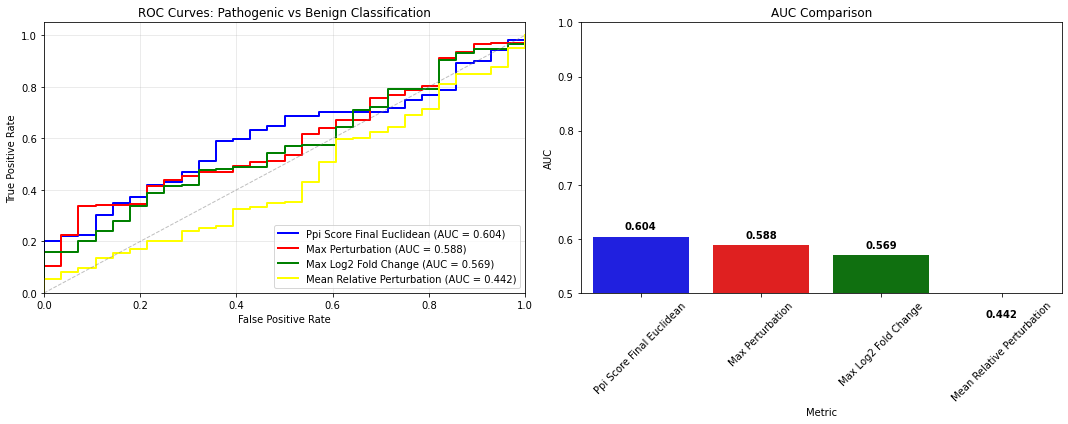


AUC Scores for Pathogenic vs Benign Classification:
Ppi Score Final Euclidean: 0.604
Max Perturbation: 0.588
Max Log2 Fold Change: 0.569
Mean Relative Perturbation: 0.442


In [ ]:
# 4. ROC analysis to compare metric performance in pathogenic vs benign classification
from sklearn.metrics import roc_curve, auc

# Filter to pathogenic and benign variants only
path_benign = complete_metrics[complete_metrics['clinvar_clnsig_clean'].isin(['1_Pathogenic', '2_Benign'])].copy()
path_benign['is_pathogenic'] = (path_benign['clinvar_clnsig_clean'] == '1_Pathogenic').astype(int)

print(f"Pathogenic variants: {path_benign['is_pathogenic'].sum()}")
print(f"Benign variants: {(1-path_benign['is_pathogenic']).sum()}")

# Calculate ROC curves for each metric
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

metrics_roc = ['ppi_score_final_euclidean', 'max_perturbation', 'max_log2_fold_change', 'mean_relative_perturbation']
colors = ['blue', 'red', 'green', 'yellow']
auc_scores = {}

# ROC curves
for metric, color in zip(metrics_roc, colors):
    # Filter out NaN and infinite values
    mask = ~(path_benign['is_pathogenic'].isna() | path_benign[metric].isna() | 
             np.isinf(path_benign[metric]))
    
    if mask.sum() > 0:  # Ensure we have data after filtering
        y_true = path_benign[mask]['is_pathogenic']
        y_score = path_benign[mask][metric]
        
        if len(y_true) > 1 and y_true.nunique() > 1:  # Need multiple classes for ROC
            fpr, tpr, _ = roc_curve(y_true, y_score)
            roc_auc = auc(fpr, tpr)
            auc_scores[metric] = roc_auc
            
            axes[0].plot(fpr, tpr, color=color, lw=2, 
                        label=f'{metric.replace("_", " ").title()} (AUC = {roc_auc:.3f})')
        else:
            print(f"Insufficient valid data for {metric} ROC analysis")
            auc_scores[metric] = np.nan
    else:
        print(f"No valid data for {metric} ROC analysis")
        auc_scores[metric] = np.nan

axes[0].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', alpha=0.5)
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves: Pathogenic vs Benign Classification')
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# AUC comparison bar plot
valid_auc_scores = {k: v for k, v in auc_scores.items() if not np.isnan(v)}
if valid_auc_scores:
    auc_df = pd.DataFrame.from_dict(valid_auc_scores, orient='index', columns=['AUC']).reset_index()
    auc_df['Metric'] = auc_df['index'].str.replace('_', ' ').str.title()

    sns.barplot(data=auc_df, x='Metric', y='AUC', palette=colors[:len(auc_df)], ax=axes[1])
    axes[1].set_title('AUC Comparison')
    axes[1].set_ylim([0.5, 1.0])
    axes[1].tick_params(axis='x', rotation=45)

    # Add AUC values on bars
    for i, (_, row) in enumerate(auc_df.iterrows()):
        axes[1].text(i, row['AUC'] + 0.01, f'{row["AUC"]:.3f}', 
                    ha='center', va='bottom', fontweight='bold')
else:
    axes[1].text(0.5, 0.5, 'No valid AUC scores', ha='center', va='center')
    axes[1].set_title('AUC Comparison - No Valid Data')

plt.tight_layout()
plt.show()

print("\nAUC Scores for Pathogenic vs Benign Classification:")
for metric, score in auc_scores.items():
    if not np.isnan(score):
        print(f"{metric.replace('_', ' ').title()}: {score:.3f}")
    else:
        print(f"{metric.replace('_', ' ').title()}: No valid data")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/2512831170.py:10: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  all_variants_df_ppi_pl


RSA categories: ['<10', '10-90', '$\\geqslant$90']
pLDDT categories: ['<=50', '50-70', '70-90', '>90']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/2512831170.py:63: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  all_variants_df_ppi_pl


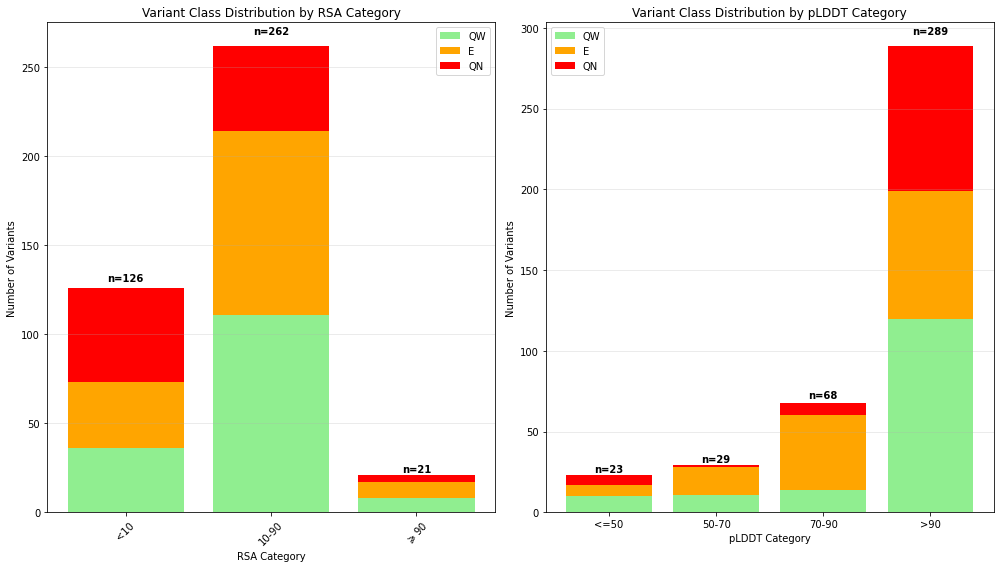

Summary Statistics:

RSA Category Distribution:
<10: 126 variants
  QW: 36 (28.6%)
  E: 37 (29.4%)
  QN: 53 (42.1%)
10-90: 262 variants
  QW: 111 (42.4%)
  E: 103 (39.3%)
  QN: 48 (18.3%)
$\geqslant$90: 21 variants
  QW: 8 (38.1%)
  E: 9 (42.9%)
  QN: 4 (19.0%)

pLDDT Category Distribution:
<=50: 23 variants
  QW: 10 (43.5%)
  E: 7 (30.4%)
  QN: 6 (26.1%)
50-70: 29 variants
  QW: 11 (37.9%)
  E: 17 (58.6%)
  QN: 1 (3.4%)
70-90: 68 variants
  QW: 14 (20.6%)
  E: 46 (67.6%)
  QN: 8 (11.8%)
>90: 289 variants
  QW: 120 (41.5%)
  E: 79 (27.3%)
  QN: 90 (31.1%)

Total variants analyzed:
  RSA data: 409
  pLDDT data: 409


In [ ]:
# Create vertical stacked bar plots for variant class distribution across RSA and pLDDT categories

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# RSA categories stacked bar plot
rsa_data = (
    all_variants_df_ppi_pl
    .filter(pl.col("RSA_Category").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["RSA_Category", "variant_class"])
    .len()
    .pivot(values="len", index="RSA_Category", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get RSA categories as a regular column, then set it as index properly
rsa_data = rsa_data.reset_index().set_index('RSA_Category')

rsa_order = ['<10', '10-90', '$\geqslant$90']

# Reindex to the desired order
rsa_data = rsa_data.reindex(rsa_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in rsa_data.columns:
        rsa_data[col] = 0
    else:
        rsa_data[col] = pd.to_numeric(rsa_data[col], errors='coerce').fillna(0)

print("RSA categories:", rsa_data.index.tolist())  # Debug print

# Create stacked bar plot for RSA
bottom_rsa = np.zeros(len(rsa_data))
x_positions = np.arange(len(rsa_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in rsa_data.columns:
        axes[0].bar(x_positions, rsa_data[variant_class], 
                   bottom=bottom_rsa, label=variant_class, 
                   color=variant_colors[variant_class])
        bottom_rsa += rsa_data[variant_class]

axes[0].set_xlabel('RSA Category')
axes[0].set_ylabel('Number of Variants')
axes[0].set_title('Variant Class Distribution by RSA Category')
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(rsa_data.index, rotation=45)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(rsa_data.index):
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[0].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

# pLDDT categories stacked bar plot (same fix)
plddt_data = (
    all_variants_df_ppi_pl
    .filter(pl.col("pLDDT_Category").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["pLDDT_Category", "variant_class"])
    .len()
    .pivot(values="len", index="pLDDT_Category", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get pLDDT categories as a regular column, then set it as index properly
plddt_data = plddt_data.reset_index().set_index('pLDDT_Category')

# Handle proper ordering for pLDDT
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# Reindex to the desired order
plddt_data = plddt_data.reindex(plddt_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in plddt_data.columns:
        plddt_data[col] = 0
    else:
        plddt_data[col] = pd.to_numeric(plddt_data[col], errors='coerce').fillna(0)

print("pLDDT categories:", plddt_data.index.tolist())  # Debug print

# Create stacked bar plot for pLDDT
bottom_plddt = np.zeros(len(plddt_data))
x_positions_plddt = np.arange(len(plddt_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in plddt_data.columns:
        axes[1].bar(x_positions_plddt, plddt_data[variant_class], 
                   bottom=bottom_plddt, label=variant_class, 
                   color=variant_colors[variant_class])
        bottom_plddt += plddt_data[variant_class]

axes[1].set_xlabel('pLDDT Category')
axes[1].set_ylabel('Number of Variants')
axes[1].set_title('Variant Class Distribution by pLDDT Category')
axes[1].set_xticks(x_positions_plddt)
axes[1].set_xticklabels(plddt_data.index)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(plddt_data.index):
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[1].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nRSA Category Distribution:")
for category in rsa_data.index:
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in rsa_data.columns:
            count = int(rsa_data.loc[category, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print("\npLDDT Category Distribution:")
for category in plddt_data.index:
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in plddt_data.columns:
            count = int(plddt_data.loc[category, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed:")
print(f"  RSA data: {int(rsa_data[['E', 'QN', 'QW']].sum().sum())}")
print(f"  pLDDT data: {int(plddt_data[['E', 'QN', 'QW']].sum().sum())}")

In [ ]:
all_variants_df_ppi_pl.to_pandas()

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,max_perturbation_fold_abs,max_log2_fold_change,variant_class,variant_class_log2fc,mean_relative_perturbation,mean_wt,inheritance_pattern,inheritance_source,rsa,plddt
0,EZH2,EZH2_Arg684Cys,ENSG00000106462,NC_000007.14:148809370:G:A,143,213584.0,2050C>T,Arg684Cys,1_Pathogenic,NaN,...,1.597322,0.675656,I,QW,-0.373952,0.481586,None,None,NaN,NaN
1,PTS,PTS_Arg25Gln,ENSG00000150787,NC_000011.10:112226517:G:A,145,200059.0,74G>A,Arg25Gln,1_Pathogenic,6.990040e-07,...,0.767416,-0.381920,QW,QW,0.303075,0.251573,autosomal recessive,OMIM,0.254032,98.45
2,PTS,PTS_Asp116Gly,ENSG00000150787,NC_000011.10:112233464:A:G,145,200065.0,347A>G,Asp116Gly,3_Conflicting,4.105980e-06,...,1.124227,0.168933,QW,QW,-0.110500,0.251573,autosomal recessive,OMIM,0.392638,98.63
3,MVK,MVK_His20Pro,ENSG00000110921,NC_000012.12:109574881:A:C,281,3.0,59A>C,His20Pro,1_Pathogenic,9.603990e-06,...,2.766949,1.468296,QN,QN,-0.638591,0.194913,multiple,OMIM,0.043478,94.91
4,MVK,MVK_Ser52Asn,ENSG00000110921,NC_000012.12:109576074:G:A,281,5.0,155G>A,Ser52Asn,2_Benign,1.106140e-01,...,0.763612,-0.389088,QW,QW,0.309565,0.194913,multiple,OMIM,0.176923,96.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,KCNJ2,KCNJ2_Arg312His,ENSG00000123700,NC_000017.11:70175974:G:A,100016069,2649.0,935G>A,Arg312His,1_Pathogenic,6.840540e-07,...,4.001877,2.000677,QN,QN,-0.707648,0.480679,autosomal dominant,OMIM,0.181452,95.87
471,KCNJ2,KCNJ2_Glu349Lys,ENSG00000123700,NC_000017.11:70176084:G:A,100016069,2654.0,1045G>A,Glu349Lys,3_Conflicting,1.299710e-05,...,5.449343,2.446082,QN,QN,-0.785303,0.480679,autosomal dominant,OMIM,0.737113,97.03
472,KCNJ2,KCNJ2_Thr400Met,ENSG00000123700,NC_000017.11:70176238:C:T,100016069,2656.0,1199C>T,Thr400Met,3_Conflicting,5.198930e-05,...,6.350245,2.666812,QN,QN,-0.741376,0.480679,autosomal dominant,OMIM,0.838028,40.68
473,KCNJ2,KCNJ2_Pro415Leu,ENSG00000123700,NC_000017.11:70176283:C:T,100016069,2659.0,1244C>T,Pro415Leu,3_Conflicting,1.238130e-04,...,6.276117,2.649872,QN,QN,-0.787751,0.480679,autosomal dominant,OMIM,0.948529,43.90


RSA categories: ['<10', '10-90', '$\\geqslant$90']
pLDDT categories: ['<=50', '50-70', '70-90', '>90']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/1996362414.py:10: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  all_variants_df_ppi_pl
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/1996362414.py:63: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  all_variants_df_ppi_pl


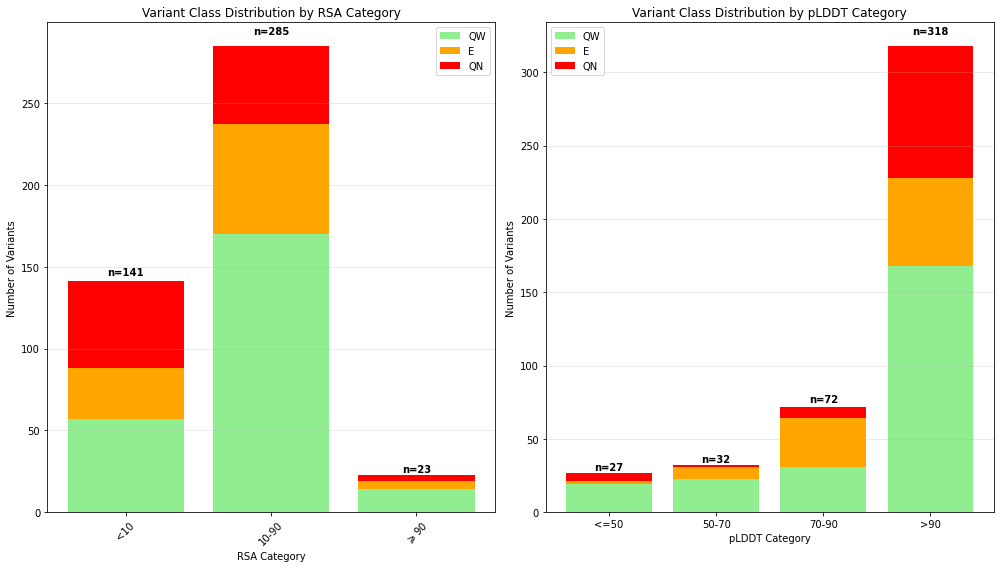

Summary Statistics:

RSA Category Distribution:
<10: 141 variants
  QW: 57 (40.4%)
  E: 31 (22.0%)
  QN: 53 (37.6%)
10-90: 285 variants
  QW: 170 (59.6%)
  E: 67 (23.5%)
  QN: 48 (16.8%)
$\geqslant$90: 23 variants
  QW: 14 (60.9%)
  E: 5 (21.7%)
  QN: 4 (17.4%)

pLDDT Category Distribution:
<=50: 27 variants
  QW: 19 (70.4%)
  E: 2 (7.4%)
  QN: 6 (22.2%)
50-70: 32 variants
  QW: 23 (71.9%)
  E: 8 (25.0%)
  QN: 1 (3.1%)
70-90: 72 variants
  QW: 31 (43.1%)
  E: 33 (45.8%)
  QN: 8 (11.1%)
>90: 318 variants
  QW: 168 (52.8%)
  E: 60 (18.9%)
  QN: 90 (28.3%)

Total variants analyzed:
  RSA data: 449
  pLDDT data: 449


In [ ]:
# Create vertical stacked bar plots for variant class distribution across RSA and pLDDT categories

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# RSA categories stacked bar plot
rsa_data = (
    all_variants_df_ppi_pl
    .filter(pl.col("RSA_Category").is_not_null() & pl.col("variant_class_log2fc").is_in(["E", "QN", "QW"]))
    .group_by(["RSA_Category", "variant_class_log2fc"])
    .len()
    .pivot(values="len", index="RSA_Category", columns="variant_class_log2fc")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get RSA categories as a regular column, then set it as index properly
rsa_data = rsa_data.reset_index().set_index('RSA_Category')

rsa_order = ['<10', '10-90', '$\geqslant$90']

# Reindex to the desired order
rsa_data = rsa_data.reindex(rsa_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in rsa_data.columns:
        rsa_data[col] = 0
    else:
        rsa_data[col] = pd.to_numeric(rsa_data[col], errors='coerce').fillna(0)

print("RSA categories:", rsa_data.index.tolist())  # Debug print

# Create stacked bar plot for RSA
bottom_rsa = np.zeros(len(rsa_data))
x_positions = np.arange(len(rsa_data))

for variant_class_log2fc in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class_log2fc in rsa_data.columns:
        axes[0].bar(x_positions, rsa_data[variant_class_log2fc], 
                   bottom=bottom_rsa, label=variant_class_log2fc, 
                   color=variant_colors[variant_class_log2fc])
        bottom_rsa += rsa_data[variant_class_log2fc]

axes[0].set_xlabel('RSA Category')
axes[0].set_ylabel('Number of Variants')
axes[0].set_title('Variant Class Distribution by RSA Category')
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(rsa_data.index, rotation=45)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(rsa_data.index):
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[0].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

# pLDDT categories stacked bar plot (same fix)
plddt_data = (
    all_variants_df_ppi_pl
    .filter(pl.col("pLDDT_Category").is_not_null() & pl.col("variant_class_log2fc").is_in(["E", "QN", "QW"]))
    .group_by(["pLDDT_Category", "variant_class_log2fc"])
    .len()
    .pivot(values="len", index="pLDDT_Category", columns="variant_class_log2fc")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get pLDDT categories as a regular column, then set it as index properly
plddt_data = plddt_data.reset_index().set_index('pLDDT_Category')

# Handle proper ordering for pLDDT
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# Reindex to the desired order
plddt_data = plddt_data.reindex(plddt_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in plddt_data.columns:
        plddt_data[col] = 0
    else:
        plddt_data[col] = pd.to_numeric(plddt_data[col], errors='coerce').fillna(0)

print("pLDDT categories:", plddt_data.index.tolist())  # Debug print

# Create stacked bar plot for pLDDT
bottom_plddt = np.zeros(len(plddt_data))
x_positions_plddt = np.arange(len(plddt_data))

for variant_class_log2fc in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class_log2fc in plddt_data.columns:
        axes[1].bar(x_positions_plddt, plddt_data[variant_class_log2fc], 
                   bottom=bottom_plddt, label=variant_class_log2fc, 
                   color=variant_colors[variant_class_log2fc])
        bottom_plddt += plddt_data[variant_class_log2fc]

axes[1].set_xlabel('pLDDT Category')
axes[1].set_ylabel('Number of Variants')
axes[1].set_title('Variant Class Distribution by pLDDT Category')
axes[1].set_xticks(x_positions_plddt)
axes[1].set_xticklabels(plddt_data.index)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(plddt_data.index):
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[1].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nRSA Category Distribution:")
for category in rsa_data.index:
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class_log2fc in ["QW", "E", "QN"]:
        if variant_class_log2fc in rsa_data.columns:
            count = int(rsa_data.loc[category, variant_class_log2fc])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class_log2fc}: {count} ({pct:.1f}%)")

print("\npLDDT Category Distribution:")
for category in plddt_data.index:
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class_log2fc in ["QW", "E", "QN"]:
        if variant_class_log2fc in plddt_data.columns:
            count = int(plddt_data.loc[category, variant_class_log2fc])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class_log2fc}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed:")
print(f"  RSA data: {int(rsa_data[['E', 'QN', 'QW']].sum().sum())}")
print(f"  pLDDT data: {int(plddt_data[['E', 'QN', 'QW']].sum().sum())}")

RSA categories: ['<10', '10-90', '$\\geqslant$90']
pLDDT categories: ['<=50', '50-70', '70-90', '>90']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/2289118059.py:12: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  patho_df
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/2289118059.py:65: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  patho_df


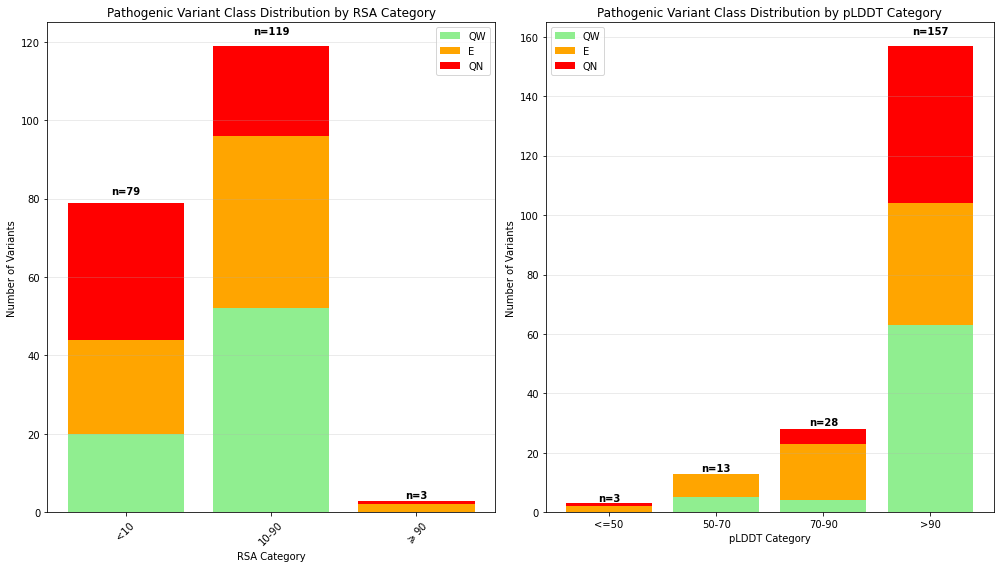

Summary Statistics:

RSA Category Distribution:
<10: 79 variants
  QW: 20 (25.3%)
  E: 24 (30.4%)
  QN: 35 (44.3%)
10-90: 119 variants
  QW: 52 (43.7%)
  E: 44 (37.0%)
  QN: 23 (19.3%)
$\geqslant$90: 3 variants
  QW: 0 (0.0%)
  E: 2 (66.7%)
  QN: 1 (33.3%)

pLDDT Category Distribution:
<=50: 3 variants
  QW: 0 (0.0%)
  E: 2 (66.7%)
  QN: 1 (33.3%)
50-70: 13 variants
  QW: 5 (38.5%)
  E: 8 (61.5%)
  QN: 0 (0.0%)
70-90: 28 variants
  QW: 4 (14.3%)
  E: 19 (67.9%)
  QN: 5 (17.9%)
>90: 157 variants
  QW: 63 (40.1%)
  E: 41 (26.1%)
  QN: 53 (33.8%)

Total variants analyzed:
  RSA data: 201
  pLDDT data: 201


In [ ]:
patho_df = all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")

# Create vertical stacked bar plots for variant class distribution across RSA and pLDDT categories

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# RSA categories stacked bar plot
rsa_data = (
    patho_df
    .filter(pl.col("RSA_Category").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["RSA_Category", "variant_class"])
    .len()
    .pivot(values="len", index="RSA_Category", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get RSA categories as a regular column, then set it as index properly
rsa_data = rsa_data.reset_index().set_index('RSA_Category')

rsa_order = ['<10', '10-90', '$\geqslant$90']

# Reindex to the desired order
rsa_data = rsa_data.reindex(rsa_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in rsa_data.columns:
        rsa_data[col] = 0
    else:
        rsa_data[col] = pd.to_numeric(rsa_data[col], errors='coerce').fillna(0)

print("RSA categories:", rsa_data.index.tolist())  # Debug print

# Create stacked bar plot for RSA
bottom_rsa = np.zeros(len(rsa_data))
x_positions = np.arange(len(rsa_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in rsa_data.columns:
        axes[0].bar(x_positions, rsa_data[variant_class], 
                   bottom=bottom_rsa, label=variant_class, 
                   color=variant_colors[variant_class])
        bottom_rsa += rsa_data[variant_class]

axes[0].set_xlabel('RSA Category')
axes[0].set_ylabel('Number of Variants')
axes[0].set_title('Pathogenic Variant Class Distribution by RSA Category')
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(rsa_data.index, rotation=45)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(rsa_data.index):
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[0].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

# pLDDT categories stacked bar plot (same fix)
plddt_data = (
    patho_df
    .filter(pl.col("pLDDT_Category").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["pLDDT_Category", "variant_class"])
    .len()
    .pivot(values="len", index="pLDDT_Category", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get pLDDT categories as a regular column, then set it as index properly
plddt_data = plddt_data.reset_index().set_index('pLDDT_Category')

# Handle proper ordering for pLDDT
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# Reindex to the desired order
plddt_data = plddt_data.reindex(plddt_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in plddt_data.columns:
        plddt_data[col] = 0
    else:
        plddt_data[col] = pd.to_numeric(plddt_data[col], errors='coerce').fillna(0)

print("pLDDT categories:", plddt_data.index.tolist())  # Debug print

# Create stacked bar plot for pLDDT
bottom_plddt = np.zeros(len(plddt_data))
x_positions_plddt = np.arange(len(plddt_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in plddt_data.columns:
        axes[1].bar(x_positions_plddt, plddt_data[variant_class], 
                   bottom=bottom_plddt, label=variant_class, 
                   color=variant_colors[variant_class])
        bottom_plddt += plddt_data[variant_class]

axes[1].set_xlabel('pLDDT Category')
axes[1].set_ylabel('Number of Variants')
axes[1].set_title('Pathogenic Variant Class Distribution by pLDDT Category')
axes[1].set_xticks(x_positions_plddt)
axes[1].set_xticklabels(plddt_data.index)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(plddt_data.index):
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[1].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nRSA Category Distribution:")
for category in rsa_data.index:
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in rsa_data.columns:
            count = int(rsa_data.loc[category, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print("\npLDDT Category Distribution:")
for category in plddt_data.index:
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in plddt_data.columns:
            count = int(plddt_data.loc[category, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed:")
print(f"  RSA data: {int(rsa_data[['E', 'QN', 'QW']].sum().sum())}")
print(f"  pLDDT data: {int(plddt_data[['E', 'QN', 'QW']].sum().sum())}")

RSA categories: ['<10', '10-90', '$\\geqslant$90']
pLDDT categories: ['<=50', '50-70', '70-90', '>90']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/625249251.py:12: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  patho_df
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/625249251.py:65: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  patho_df


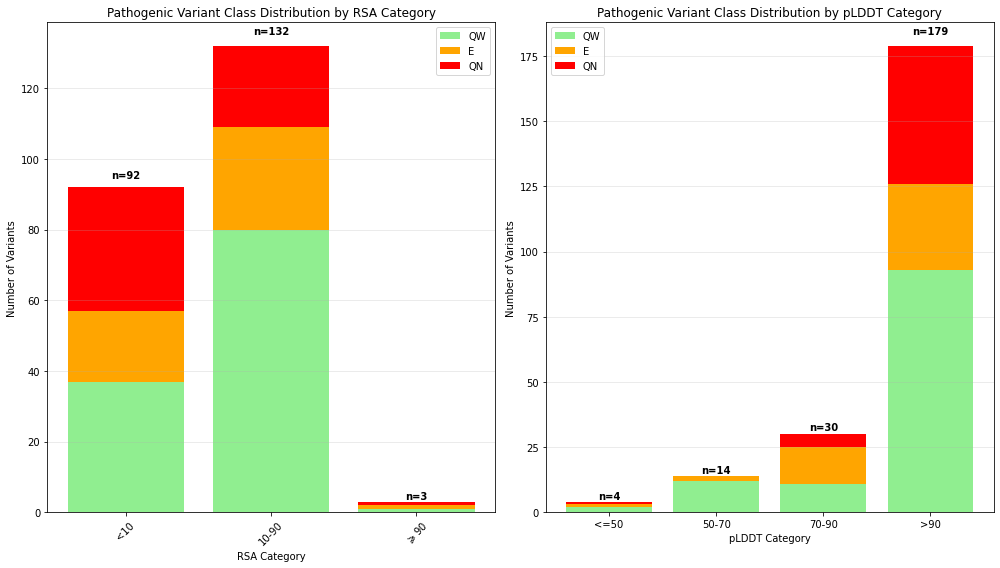

Summary Statistics:

RSA Category Distribution:
<10: 92 variants
  QW: 37 (40.2%)
  E: 20 (21.7%)
  QN: 35 (38.0%)
10-90: 132 variants
  QW: 80 (60.6%)
  E: 29 (22.0%)
  QN: 23 (17.4%)
$\geqslant$90: 3 variants
  QW: 1 (33.3%)
  E: 1 (33.3%)
  QN: 1 (33.3%)

pLDDT Category Distribution:
<=50: 4 variants
  QW: 2 (50.0%)
  E: 1 (25.0%)
  QN: 1 (25.0%)
50-70: 14 variants
  QW: 12 (85.7%)
  E: 2 (14.3%)
  QN: 0 (0.0%)
70-90: 30 variants
  QW: 11 (36.7%)
  E: 14 (46.7%)
  QN: 5 (16.7%)
>90: 179 variants
  QW: 93 (52.0%)
  E: 33 (18.4%)
  QN: 53 (29.6%)

Total variants analyzed:
  RSA data: 227
  pLDDT data: 227


In [ ]:
patho_df = all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")

# Create vertical stacked bar plots for variant class distribution across RSA and pLDDT categories

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# RSA categories stacked bar plot
rsa_data = (
    patho_df
    .filter(pl.col("RSA_Category").is_not_null() & pl.col("variant_class_log2fc").is_in(["E", "QN", "QW"]))
    .group_by(["RSA_Category", "variant_class_log2fc"])
    .len()
    .pivot(values="len", index="RSA_Category", columns="variant_class_log2fc")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get RSA categories as a regular column, then set it as index properly
rsa_data = rsa_data.reset_index().set_index('RSA_Category')

rsa_order = ['<10', '10-90', '$\geqslant$90']

# Reindex to the desired order
rsa_data = rsa_data.reindex(rsa_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in rsa_data.columns:
        rsa_data[col] = 0
    else:
        rsa_data[col] = pd.to_numeric(rsa_data[col], errors='coerce').fillna(0)

print("RSA categories:", rsa_data.index.tolist())  # Debug print

# Create stacked bar plot for RSA
bottom_rsa = np.zeros(len(rsa_data))
x_positions = np.arange(len(rsa_data))

for variant_class_log2fc in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class_log2fc in rsa_data.columns:
        axes[0].bar(x_positions, rsa_data[variant_class_log2fc], 
                   bottom=bottom_rsa, label=variant_class_log2fc, 
                   color=variant_colors[variant_class_log2fc])
        bottom_rsa += rsa_data[variant_class_log2fc]

axes[0].set_xlabel('RSA Category')
axes[0].set_ylabel('Number of Variants')
axes[0].set_title('Pathogenic Variant Class Distribution by RSA Category')
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(rsa_data.index, rotation=45)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(rsa_data.index):
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[0].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

# pLDDT categories stacked bar plot (same fix)
plddt_data = (
    patho_df
    .filter(pl.col("pLDDT_Category").is_not_null() & pl.col("variant_class_log2fc").is_in(["E", "QN", "QW"]))
    .group_by(["pLDDT_Category", "variant_class_log2fc"])
    .len()
    .pivot(values="len", index="pLDDT_Category", columns="variant_class_log2fc")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get pLDDT categories as a regular column, then set it as index properly
plddt_data = plddt_data.reset_index().set_index('pLDDT_Category')

# Handle proper ordering for pLDDT
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# Reindex to the desired order
plddt_data = plddt_data.reindex(plddt_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in plddt_data.columns:
        plddt_data[col] = 0
    else:
        plddt_data[col] = pd.to_numeric(plddt_data[col], errors='coerce').fillna(0)

print("pLDDT categories:", plddt_data.index.tolist())  # Debug print

# Create stacked bar plot for pLDDT
bottom_plddt = np.zeros(len(plddt_data))
x_positions_plddt = np.arange(len(plddt_data))

for variant_class_log2fc in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class_log2fc in plddt_data.columns:
        axes[1].bar(x_positions_plddt, plddt_data[variant_class_log2fc], 
                   bottom=bottom_plddt, label=variant_class_log2fc, 
                   color=variant_colors[variant_class_log2fc])
        bottom_plddt += plddt_data[variant_class_log2fc]

axes[1].set_xlabel('pLDDT Category')
axes[1].set_ylabel('Number of Variants')
axes[1].set_title('Pathogenic Variant Class Distribution by pLDDT Category')
axes[1].set_xticks(x_positions_plddt)
axes[1].set_xticklabels(plddt_data.index)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(plddt_data.index):
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[1].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nRSA Category Distribution:")
for category in rsa_data.index:
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class_log2fc in ["QW", "E", "QN"]:
        if variant_class_log2fc in rsa_data.columns:
            count = int(rsa_data.loc[category, variant_class_log2fc])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class_log2fc}: {count} ({pct:.1f}%)")

print("\npLDDT Category Distribution:")
for category in plddt_data.index:
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class_log2fc in ["QW", "E", "QN"]:
        if variant_class_log2fc in plddt_data.columns:
            count = int(plddt_data.loc[category, variant_class_log2fc])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class_log2fc}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed:")
print(f"  RSA data: {int(rsa_data[['E', 'QN', 'QW']].sum().sum())}")
print(f"  pLDDT data: {int(plddt_data[['E', 'QN', 'QW']].sum().sum())}")

RSA categories: ['<10', '10-90', '$\\geqslant$90']
pLDDT categories: ['<=50', '50-70', '70-90', '>90']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/1853831850.py:12: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  ben_df
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/1853831850.py:65: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  ben_df


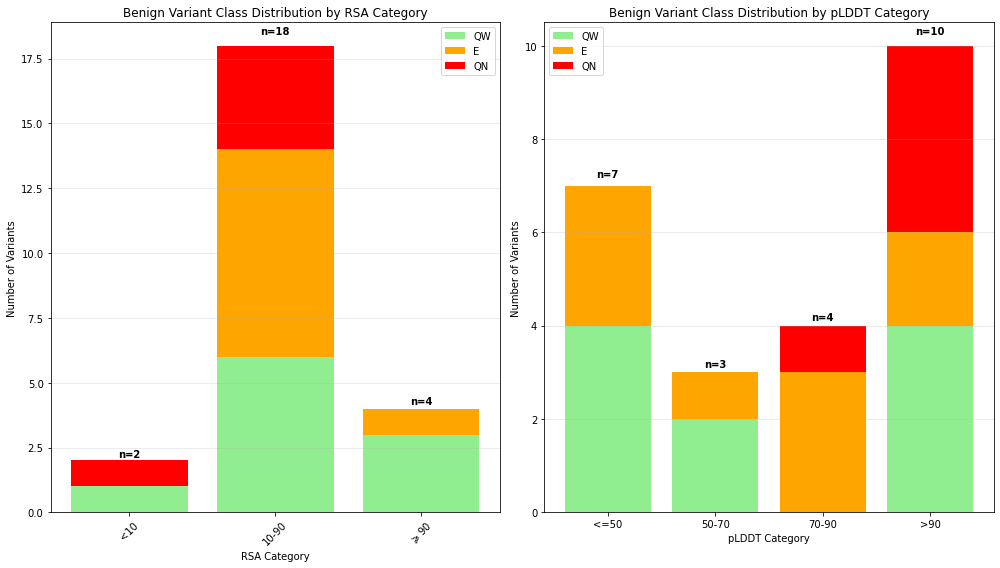

Summary Statistics:

RSA Category Distribution:
<10: 2 variants
  QW: 1 (50.0%)
  E: 0 (0.0%)
  QN: 1 (50.0%)
10-90: 18 variants
  QW: 6 (33.3%)
  E: 8 (44.4%)
  QN: 4 (22.2%)
$\geqslant$90: 4 variants
  QW: 3 (75.0%)
  E: 1 (25.0%)
  QN: 0 (0.0%)

pLDDT Category Distribution:
<=50: 7 variants
  QW: 4 (57.1%)
  E: 3 (42.9%)
  QN: 0 (0.0%)
50-70: 3 variants
  QW: 2 (66.7%)
  E: 1 (33.3%)
  QN: 0 (0.0%)
70-90: 4 variants
  QW: 0 (0.0%)
  E: 3 (75.0%)
  QN: 1 (25.0%)
>90: 10 variants
  QW: 4 (40.0%)
  E: 2 (20.0%)
  QN: 4 (40.0%)

Total variants analyzed:
  RSA data: 24
  pLDDT data: 24


In [ ]:
ben_df = all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")

# Create vertical stacked bar plots for variant class distribution across RSA and pLDDT categories

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# RSA categories stacked bar plot
rsa_data = (
    ben_df
    .filter(pl.col("RSA_Category").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["RSA_Category", "variant_class"])
    .len()
    .pivot(values="len", index="RSA_Category", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get RSA categories as a regular column, then set it as index properly
rsa_data = rsa_data.reset_index().set_index('RSA_Category')

rsa_order = ['<10', '10-90', '$\geqslant$90']

# Reindex to the desired order
rsa_data = rsa_data.reindex(rsa_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in rsa_data.columns:
        rsa_data[col] = 0
    else:
        rsa_data[col] = pd.to_numeric(rsa_data[col], errors='coerce').fillna(0)

print("RSA categories:", rsa_data.index.tolist())  # Debug print

# Create stacked bar plot for RSA
bottom_rsa = np.zeros(len(rsa_data))
x_positions = np.arange(len(rsa_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in rsa_data.columns:
        axes[0].bar(x_positions, rsa_data[variant_class], 
                   bottom=bottom_rsa, label=variant_class, 
                   color=variant_colors[variant_class])
        bottom_rsa += rsa_data[variant_class]

axes[0].set_xlabel('RSA Category')
axes[0].set_ylabel('Number of Variants')
axes[0].set_title('Benign Variant Class Distribution by RSA Category')
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(rsa_data.index, rotation=45)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(rsa_data.index):
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[0].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

# pLDDT categories stacked bar plot (same fix)
plddt_data = (
    ben_df
    .filter(pl.col("pLDDT_Category").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["pLDDT_Category", "variant_class"])
    .len()
    .pivot(values="len", index="pLDDT_Category", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get pLDDT categories as a regular column, then set it as index properly
plddt_data = plddt_data.reset_index().set_index('pLDDT_Category')

# Handle proper ordering for pLDDT
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# Reindex to the desired order
plddt_data = plddt_data.reindex(plddt_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in plddt_data.columns:
        plddt_data[col] = 0
    else:
        plddt_data[col] = pd.to_numeric(plddt_data[col], errors='coerce').fillna(0)

print("pLDDT categories:", plddt_data.index.tolist())  # Debug print

# Create stacked bar plot for pLDDT
bottom_plddt = np.zeros(len(plddt_data))
x_positions_plddt = np.arange(len(plddt_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in plddt_data.columns:
        axes[1].bar(x_positions_plddt, plddt_data[variant_class], 
                   bottom=bottom_plddt, label=variant_class, 
                   color=variant_colors[variant_class])
        bottom_plddt += plddt_data[variant_class]

axes[1].set_xlabel('pLDDT Category')
axes[1].set_ylabel('Number of Variants')
axes[1].set_title('Benign Variant Class Distribution by pLDDT Category')
axes[1].set_xticks(x_positions_plddt)
axes[1].set_xticklabels(plddt_data.index)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(plddt_data.index):
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[1].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nRSA Category Distribution:")
for category in rsa_data.index:
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in rsa_data.columns:
            count = int(rsa_data.loc[category, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print("\npLDDT Category Distribution:")
for category in plddt_data.index:
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in plddt_data.columns:
            count = int(plddt_data.loc[category, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed:")
print(f"  RSA data: {int(rsa_data[['E', 'QN', 'QW']].sum().sum())}")
print(f"  pLDDT data: {int(plddt_data[['E', 'QN', 'QW']].sum().sum())}")

RSA categories: ['<10', '10-90', '$\\geqslant$90']
pLDDT categories: ['<=50', '50-70', '70-90', '>90']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/713447294.py:12: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  vus_df
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/713447294.py:65: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  vus_df


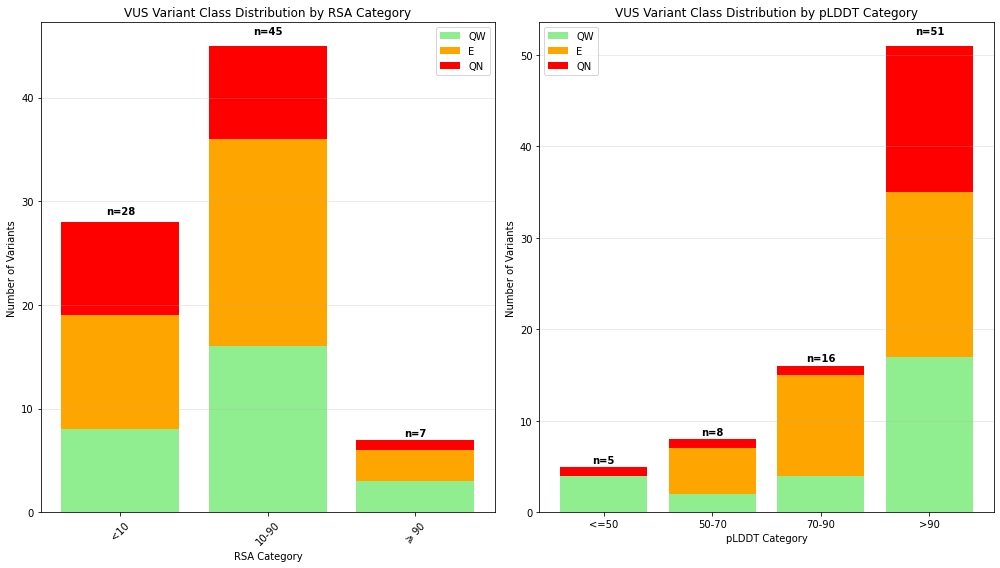

Summary Statistics:

RSA Category Distribution:
<10: 28 variants
  QW: 8 (28.6%)
  E: 11 (39.3%)
  QN: 9 (32.1%)
10-90: 45 variants
  QW: 16 (35.6%)
  E: 20 (44.4%)
  QN: 9 (20.0%)
$\geqslant$90: 7 variants
  QW: 3 (42.9%)
  E: 3 (42.9%)
  QN: 1 (14.3%)

pLDDT Category Distribution:
<=50: 5 variants
  QW: 4 (80.0%)
  E: 0 (0.0%)
  QN: 1 (20.0%)
50-70: 8 variants
  QW: 2 (25.0%)
  E: 5 (62.5%)
  QN: 1 (12.5%)
70-90: 16 variants
  QW: 4 (25.0%)
  E: 11 (68.8%)
  QN: 1 (6.2%)
>90: 51 variants
  QW: 17 (33.3%)
  E: 18 (35.3%)
  QN: 16 (31.4%)

Total variants analyzed:
  RSA data: 80
  pLDDT data: 80


In [ ]:
vus_df = all_variants_df_ppi_pl.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")

# Create vertical stacked bar plots for VUS variant class distribution across RSA and pLDDT categories

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Define colors for VUS variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# RSA categories stacked bar plot
rsa_data = (
    vus_df
    .filter(pl.col("RSA_Category").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["RSA_Category", "variant_class"])
    .len()
    .pivot(values="len", index="RSA_Category", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get RSA categories as a regular column, then set it as index properly
rsa_data = rsa_data.reset_index().set_index('RSA_Category')

rsa_order = ['<10', '10-90', '$\geqslant$90']

# Reindex to the desired order
rsa_data = rsa_data.reindex(rsa_order).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in rsa_data.columns:
        rsa_data[col] = 0
    else:
        rsa_data[col] = pd.to_numeric(rsa_data[col], errors='coerce').fillna(0)

print("RSA categories:", rsa_data.index.tolist())  # Debug print

# Create stacked bar plot for RSA
bottom_rsa = np.zeros(len(rsa_data))
x_positions = np.arange(len(rsa_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in rsa_data.columns:
        axes[0].bar(x_positions, rsa_data[variant_class], 
                   bottom=bottom_rsa, label=variant_class, 
                   color=variant_colors[variant_class])
        bottom_rsa += rsa_data[variant_class]

axes[0].set_xlabel('RSA Category')
axes[0].set_ylabel('Number of Variants')
axes[0].set_title('VUS Variant Class Distribution by RSA Category')
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(rsa_data.index, rotation=45)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(rsa_data.index):
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[0].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

# pLDDT categories stacked bar plot (same fix)
plddt_data = (
    vus_df
    .filter(pl.col("pLDDT_Category").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["pLDDT_Category", "variant_class"])
    .len()
    .pivot(values="len", index="pLDDT_Category", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get pLDDT categories as a regular column, then set it as index properly
plddt_data = plddt_data.reset_index().set_index('pLDDT_Category')

# Handle proper ordering for pLDDT
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# Reindex to the desired order
plddt_data = plddt_data.reindex(plddt_order).fillna(0)

# Ensure all VUS variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in plddt_data.columns:
        plddt_data[col] = 0
    else:
        plddt_data[col] = pd.to_numeric(plddt_data[col], errors='coerce').fillna(0)

print("pLDDT categories:", plddt_data.index.tolist())  # Debug print

# Create stacked bar plot for pLDDT
bottom_plddt = np.zeros(len(plddt_data))
x_positions_plddt = np.arange(len(plddt_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in plddt_data.columns:
        axes[1].bar(x_positions_plddt, plddt_data[variant_class], 
                   bottom=bottom_plddt, label=variant_class, 
                   color=variant_colors[variant_class])
        bottom_plddt += plddt_data[variant_class]

axes[1].set_xlabel('pLDDT Category')
axes[1].set_ylabel('Number of Variants')
axes[1].set_title('VUS Variant Class Distribution by pLDDT Category')
axes[1].set_xticks(x_positions_plddt)
axes[1].set_xticklabels(plddt_data.index)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Add total counts on top of bars
for i, category in enumerate(plddt_data.index):
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    axes[1].text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nRSA Category Distribution:")
for category in rsa_data.index:
    total = int(rsa_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in rsa_data.columns:
            count = int(rsa_data.loc[category, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print("\npLDDT Category Distribution:")
for category in plddt_data.index:
    total = int(plddt_data.loc[category, ["E", "QN", "QW"]].sum())
    print(f"{category}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in plddt_data.columns:
            count = int(plddt_data.loc[category, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed:")
print(f"  RSA data: {int(rsa_data[['E', 'QN', 'QW']].sum().sum())}")
print(f"  pLDDT data: {int(plddt_data[['E', 'QN', 'QW']].sum().sum())}")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/554754021.py:10: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  all_variants_df_ppi_pl


Inheritance patterns: ['autosomal dominant', 'autosomal recessive', 'x-linked', 'x-linked recessive', 'multiple']


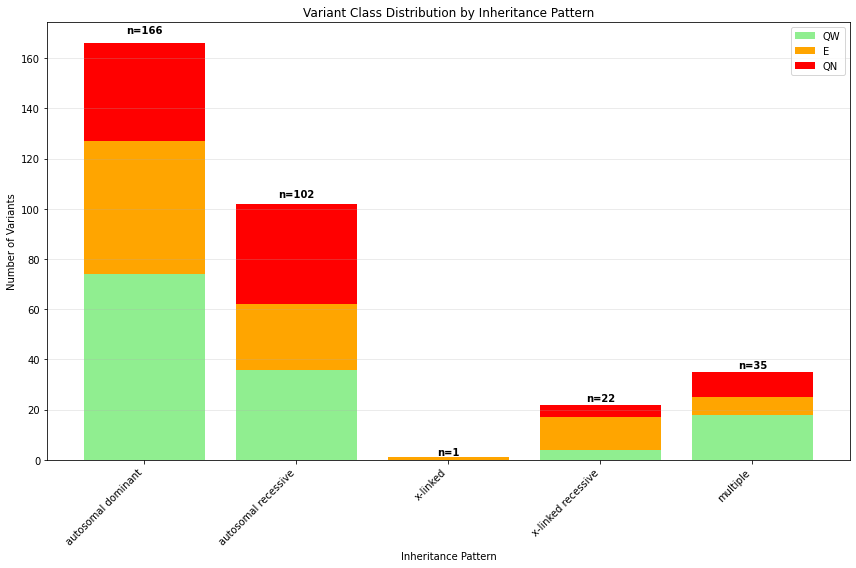

Summary Statistics:

Inheritance Pattern Distribution:
autosomal dominant: 166 variants
  QW: 74 (44.6%)
  E: 53 (31.9%)
  QN: 39 (23.5%)
autosomal recessive: 102 variants
  QW: 36 (35.3%)
  E: 26 (25.5%)
  QN: 40 (39.2%)
x-linked: 1 variants
  QW: 0 (0.0%)
  E: 1 (100.0%)
  QN: 0 (0.0%)
x-linked recessive: 22 variants
  QW: 4 (18.2%)
  E: 13 (59.1%)
  QN: 5 (22.7%)
multiple: 35 variants
  QW: 18 (51.4%)
  E: 7 (20.0%)
  QN: 10 (28.6%)

Total variants analyzed: 326

All inheritance patterns in dataset:
  autosomal dominant: 170 variants
  autosomal recessive: 119 variants
  multiple: 39 variants
  x-linked recessive: 32 variants
  x-linked: 2 variants


In [ ]:
# Create vertical stacked bar plots for variant class distribution across inheritance patterns

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# Filter to relevant inheritance patterns and variant classes
inheritance_data = (
    all_variants_df_ppi_pl
    .filter(pl.col("inheritance_pattern").is_not_null() & pl.col("variant_class").is_in(["E", "QN", "QW"]))
    .group_by(["inheritance_pattern", "variant_class"])
    .len()
    .pivot(values="len", index="inheritance_pattern", columns="variant_class")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get inheritance patterns as a regular column, then set it as index properly
inheritance_data = inheritance_data.reset_index().set_index('inheritance_pattern')

# Define the desired order for inheritance patterns
inheritance_order = ['autosomal dominant', 'autosomal recessive', 'x-linked', 'x-linked recessive', 'multiple']

# Filter to only include the inheritance patterns we want and reindex to desired order
inheritance_data = inheritance_data.reindex([pattern for pattern in inheritance_order if pattern in inheritance_data.index]).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in inheritance_data.columns:
        inheritance_data[col] = 0
    else:
        inheritance_data[col] = pd.to_numeric(inheritance_data[col], errors='coerce').fillna(0)

print("Inheritance patterns:", inheritance_data.index.tolist())  # Debug print

# Create stacked bar plot for inheritance patterns
bottom_inheritance = np.zeros(len(inheritance_data))
x_positions = np.arange(len(inheritance_data))

for variant_class in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class in inheritance_data.columns:
        ax.bar(x_positions, inheritance_data[variant_class], 
               bottom=bottom_inheritance, label=variant_class, 
               color=variant_colors[variant_class])
        bottom_inheritance += inheritance_data[variant_class]

ax.set_xlabel('Inheritance Pattern')
ax.set_ylabel('Number of Variants')
ax.set_title('Variant Class Distribution by Inheritance Pattern')
ax.set_xticks(x_positions)
ax.set_xticklabels(inheritance_data.index, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Add counts (not percentages) of each class above bars for inheritance patterns
# for i, pattern in enumerate(inheritance_data.index):
#     total = int(inheritance_data.loc[pattern, ["E", "QN", "QW"]].sum())
#     y_offset = total + total*0.02
    
#     # Show actual counts for each class
#     for j, variant_class in enumerate(["QW", "E", "QN"]):
#         if variant_class in inheritance_data.columns:
#             count = int(inheritance_data.loc[pattern, variant_class])
#             if count > 0:  # Only show non-zero counts
#                 ax.text(i, y_offset + j*total*0.06, f'{variant_class}: {count}', 
#                         ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, category in enumerate(inheritance_data.index):
    total = int(inheritance_data.loc[category, ["E", "QN", "QW"]].sum())
    ax.text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nInheritance Pattern Distribution:")
for pattern in inheritance_data.index:
    total = int(inheritance_data.loc[pattern, ["E", "QN", "QW"]].sum())
    print(f"{pattern}: {total} variants")
    for variant_class in ["QW", "E", "QN"]:
        if variant_class in inheritance_data.columns:
            count = int(inheritance_data.loc[pattern, variant_class])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed: {int(inheritance_data[['E', 'QN', 'QW']].sum().sum())}")

# Additional analysis: Show all inheritance patterns present in the data
print("\nAll inheritance patterns in dataset:")
all_inheritance_patterns = (
    all_variants_df_ppi_pl
    .filter(pl.col("inheritance_pattern").is_not_null())
    .group_by("inheritance_pattern")
    .len()
    .sort("len", descending=True)
    .to_pandas()
)
for _, row in all_inheritance_patterns.iterrows():
    print(f"  {row['inheritance_pattern']}: {row['len']} variants")

Inheritance patterns: ['autosomal dominant', 'autosomal recessive', 'x-linked', 'x-linked recessive', 'multiple']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/1235239921.py:10: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  all_variants_df_ppi_pl


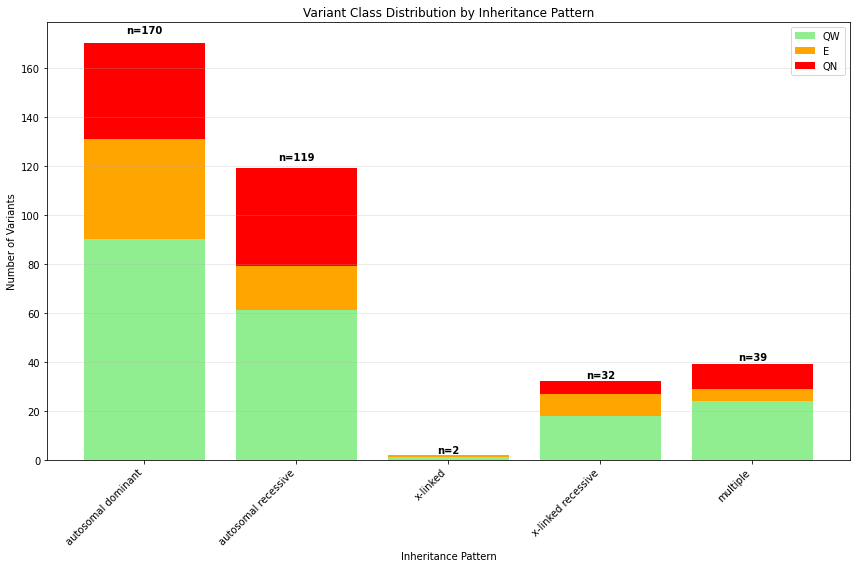

Summary Statistics:

Inheritance Pattern Distribution:
autosomal dominant: 170 variants
  QW: 90 (52.9%)
  E: 41 (24.1%)
  QN: 39 (22.9%)
autosomal recessive: 119 variants
  QW: 61 (51.3%)
  E: 18 (15.1%)
  QN: 40 (33.6%)
x-linked: 2 variants
  QW: 1 (50.0%)
  E: 1 (50.0%)
  QN: 0 (0.0%)
x-linked recessive: 32 variants
  QW: 18 (56.2%)
  E: 9 (28.1%)
  QN: 5 (15.6%)
multiple: 39 variants
  QW: 24 (61.5%)
  E: 5 (12.8%)
  QN: 10 (25.6%)

Total variants analyzed: 362

All inheritance patterns in dataset:
  autosomal dominant: 170 variants
  autosomal recessive: 119 variants
  multiple: 39 variants
  x-linked recessive: 32 variants
  x-linked: 2 variants


In [ ]:
# Create vertical stacked bar plots for variant class distribution across inheritance patterns

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# Filter to relevant inheritance patterns and variant classes
inheritance_data = (
    all_variants_df_ppi_pl
    .filter(pl.col("inheritance_pattern").is_not_null() & pl.col("variant_class_log2fc").is_in(["E", "QN", "QW"]))
    .group_by(["inheritance_pattern", "variant_class_log2fc"])
    .len()
    .pivot(values="len", index="inheritance_pattern", columns="variant_class_log2fc")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get inheritance patterns as a regular column, then set it as index properly
inheritance_data = inheritance_data.reset_index().set_index('inheritance_pattern')

# Define the desired order for inheritance patterns
inheritance_order = ['autosomal dominant', 'autosomal recessive', 'x-linked', 'x-linked recessive', 'multiple']

# Filter to only include the inheritance patterns we want and reindex to desired order
inheritance_data = inheritance_data.reindex([pattern for pattern in inheritance_order if pattern in inheritance_data.index]).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in inheritance_data.columns:
        inheritance_data[col] = 0
    else:
        inheritance_data[col] = pd.to_numeric(inheritance_data[col], errors='coerce').fillna(0)

print("Inheritance patterns:", inheritance_data.index.tolist())  # Debug print

# Create stacked bar plot for inheritance patterns
bottom_inheritance = np.zeros(len(inheritance_data))
x_positions = np.arange(len(inheritance_data))

for variant_class_log2fc in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class_log2fc in inheritance_data.columns:
        ax.bar(x_positions, inheritance_data[variant_class_log2fc], 
               bottom=bottom_inheritance, label=variant_class_log2fc, 
               color=variant_colors[variant_class_log2fc])
        bottom_inheritance += inheritance_data[variant_class_log2fc]

ax.set_xlabel('Inheritance Pattern')
ax.set_ylabel('Number of Variants')
ax.set_title('Variant Class Distribution by Inheritance Pattern')
ax.set_xticks(x_positions)
ax.set_xticklabels(inheritance_data.index, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Add counts (not percentages) of each class above bars for inheritance patterns
# for i, pattern in enumerate(inheritance_data.index):
#     total = int(inheritance_data.loc[pattern, ["E", "QN", "QW"]].sum())
#     y_offset = total + total*0.02
    
#     # Show actual counts for each class
#     for j, variant_class_log2fc in enumerate(["QW", "E", "QN"]):
#         if variant_class_log2fc in inheritance_data.columns:
#             count = int(inheritance_data.loc[pattern, variant_class_log2fc])
#             if count > 0:  # Only show non-zero counts
#                 ax.text(i, y_offset + j*total*0.06, f'{variant_class_log2fc}: {count}', 
#                         ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, category in enumerate(inheritance_data.index):
    total = int(inheritance_data.loc[category, ["E", "QN", "QW"]].sum())
    ax.text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nInheritance Pattern Distribution:")
for pattern in inheritance_data.index:
    total = int(inheritance_data.loc[pattern, ["E", "QN", "QW"]].sum())
    print(f"{pattern}: {total} variants")
    for variant_class_log2fc in ["QW", "E", "QN"]:
        if variant_class_log2fc in inheritance_data.columns:
            count = int(inheritance_data.loc[pattern, variant_class_log2fc])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class_log2fc}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed: {int(inheritance_data[['E', 'QN', 'QW']].sum().sum())}")

# Additional analysis: Show all inheritance patterns present in the data
print("\nAll inheritance patterns in dataset:")
all_inheritance_patterns = (
    all_variants_df_ppi_pl
    .filter(pl.col("inheritance_pattern").is_not_null())
    .group_by("inheritance_pattern")
    .len()
    .sort("len", descending=True)
    .to_pandas()
)
for _, row in all_inheritance_patterns.iterrows():
    print(f"  {row['inheritance_pattern']}: {row['len']} variants")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_25644/1235239921.py:10: DeprecationWarning: The argument `columns` for `DataFrame.pivot` is deprecated. It has been renamed to `on`.
  all_variants_df_ppi_pl


Inheritance patterns: ['autosomal dominant', 'autosomal recessive', 'x-linked', 'x-linked recessive', 'multiple']


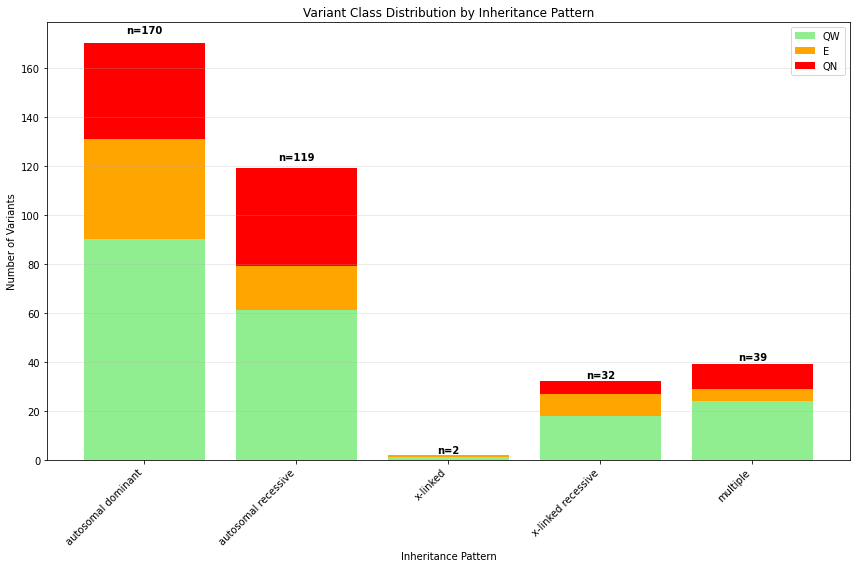

Summary Statistics:

Inheritance Pattern Distribution:
autosomal dominant: 170 variants
  QW: 90 (52.9%)
  E: 41 (24.1%)
  QN: 39 (22.9%)
autosomal recessive: 119 variants
  QW: 61 (51.3%)
  E: 18 (15.1%)
  QN: 40 (33.6%)
x-linked: 2 variants
  QW: 1 (50.0%)
  E: 1 (50.0%)
  QN: 0 (0.0%)
x-linked recessive: 32 variants
  QW: 18 (56.2%)
  E: 9 (28.1%)
  QN: 5 (15.6%)
multiple: 39 variants
  QW: 24 (61.5%)
  E: 5 (12.8%)
  QN: 10 (25.6%)

Total variants analyzed: 362

All inheritance patterns in dataset:
  autosomal dominant: 170 variants
  autosomal recessive: 119 variants
  multiple: 39 variants
  x-linked recessive: 32 variants
  x-linked: 2 variants


In [ ]:
# Create vertical stacked bar plots for variant class distribution across inheritance patterns

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# Define colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen'}

# Filter to relevant inheritance patterns and variant classes
inheritance_data = (
    all_variants_df_ppi_pl
    .filter(pl.col("inheritance_pattern").is_not_null() & pl.col("variant_class_log2fc").is_in(["E", "QN", "QW"]))
    .group_by(["inheritance_pattern", "variant_class_log2fc"])
    .len()
    .pivot(values="len", index="inheritance_pattern", columns="variant_class_log2fc")
    .fill_null(0)
    .to_pandas()
)

# Reset index to get inheritance patterns as a regular column, then set it as index properly
inheritance_data = inheritance_data.reset_index().set_index('inheritance_pattern')

# Define the desired order for inheritance patterns
inheritance_order = ['autosomal dominant', 'autosomal recessive', 'x-linked', 'x-linked recessive', 'multiple']

# Filter to only include the inheritance patterns we want and reindex to desired order
inheritance_data = inheritance_data.reindex([pattern for pattern in inheritance_order if pattern in inheritance_data.index]).fillna(0)

# Ensure all variant classes are present and convert to numeric
for col in ["E", "QN", "QW"]:
    if col not in inheritance_data.columns:
        inheritance_data[col] = 0
    else:
        inheritance_data[col] = pd.to_numeric(inheritance_data[col], errors='coerce').fillna(0)

print("Inheritance patterns:", inheritance_data.index.tolist())  # Debug print

# Create stacked bar plot for inheritance patterns
bottom_inheritance = np.zeros(len(inheritance_data))
x_positions = np.arange(len(inheritance_data))

for variant_class_log2fc in ["QW", "E", "QN"]:  # Order for stacking
    if variant_class_log2fc in inheritance_data.columns:
        ax.bar(x_positions, inheritance_data[variant_class_log2fc], 
               bottom=bottom_inheritance, label=variant_class_log2fc, 
               color=variant_colors[variant_class_log2fc])
        bottom_inheritance += inheritance_data[variant_class_log2fc]

ax.set_xlabel('Inheritance Pattern')
ax.set_ylabel('Number of Variants')
ax.set_title('Variant Class Distribution by Inheritance Pattern')
ax.set_xticks(x_positions)
ax.set_xticklabels(inheritance_data.index, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Add counts (not percentages) of each class above bars for inheritance patterns
# for i, pattern in enumerate(inheritance_data.index):
#     total = int(inheritance_data.loc[pattern, ["E", "QN", "QW"]].sum())
#     y_offset = total + total*0.02
    
#     # Show actual counts for each class
#     for j, variant_class_log2fc in enumerate(["QW", "E", "QN"]):
#         if variant_class_log2fc in inheritance_data.columns:
#             count = int(inheritance_data.loc[pattern, variant_class_log2fc])
#             if count > 0:  # Only show non-zero counts
#                 ax.text(i, y_offset + j*total*0.06, f'{variant_class_log2fc}: {count}', 
#                         ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, category in enumerate(inheritance_data.index):
    total = int(inheritance_data.loc[category, ["E", "QN", "QW"]].sum())
    ax.text(i, total + total*0.02, f'n={total}', 
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)

print("\nInheritance Pattern Distribution:")
for pattern in inheritance_data.index:
    total = int(inheritance_data.loc[pattern, ["E", "QN", "QW"]].sum())
    print(f"{pattern}: {total} variants")
    for variant_class_log2fc in ["QW", "E", "QN"]:
        if variant_class_log2fc in inheritance_data.columns:
            count = int(inheritance_data.loc[pattern, variant_class_log2fc])
            pct = (count / total) * 100 if total > 0 else 0
            print(f"  {variant_class_log2fc}: {count} ({pct:.1f}%)")

print(f"\nTotal variants analyzed: {int(inheritance_data[['E', 'QN', 'QW']].sum().sum())}")

# Additional analysis: Show all inheritance patterns present in the data
print("\nAll inheritance patterns in dataset:")
all_inheritance_patterns = (
    all_variants_df_ppi_pl
    .filter(pl.col("inheritance_pattern").is_not_null())
    .group_by("inheritance_pattern")
    .len()
    .sort("len", descending=True)
    .to_pandas()
)
for _, row in all_inheritance_patterns.iterrows():
    print(f"  {row['inheritance_pattern']}: {row['len']} variants")